# Human Influence in Rural Wildfire Ignitions

## Group: 02
### Name(s) & ID(s) of Group Members:
- Benedita Barreto da Costa Gonçalves - 202205903
- Isabela Moreira Merelles - 202602764
- Maria Leonor Soares Carvalho - 202307522
- Mariana Vale de Oliveira Coelho de Pinho - 202306234

## Table of Contents

1. [Research Question](#1-research-question)
2. [Collect Data](#2-collect-data)
   - 2.1 Dataset Source
   - 2.2 Dataset Details
   - 2.3 Data Preparation
3. [Explore Data](#3-explore-data)
   - 3.1 Q1: Changes in negligent causes
   - 3.2 Q2: Daily negligent ignitions on weekends and weekdays
   - 3.3 Q3: Burnt area across municipalities
   - 3.4 Q4: Burnt area by cause type and period
4. [Draw Inferences](#4-draw-inferences)
   - 4.1 Q1: Z-test for proportions
   - 4.2 Q2: Welch's two-sample t-test
   - 4.3 Q3: One-way ANOVA
   - 4.4 Q4: Two-way ANOVA
5. [Formulate Conclusions](#5-formulate-conclusions)
   - 5.1 to 5.4: one conclusion per question (Q1 to Q4)
6. [Look Back and Ahead](#6-look-back-and-ahead)
   - 6.1 Limitations
   - 6.2 Alternative Approaches and Future Work

---

## 1) Research Question

How did initial response times and burnt areas change before and after 2017, and how are these two variables associated across four Portuguese municipalities?

### Secondary Research Questions

1. **Q1.** Was the change in the proportion of negligent causes concentrated in the critical summer period, or did it also affect the traditional burning months (autumn/winter)?

    Difference in proportions (Variables: `Cause_Type`, `Period`, `Season_Risk_Period`). Test: two-proportion Z-test.

2. **Q2.** Did the mean number of daily negligent wildfire ignitions differ significantly between weekends and weekdays in the post-2017 period across the municipalities of Chaves, Montalegre, Ourém and Tomar?

    Mean comparison (Variables: `Daily_Ignitions_Count`, `Day_Type`, `Period`). Test: Welch's two-sample t-test.

3. **Q3.** Does the mean log-transformed burnt area per fire differ significantly across Chaves, Montalegre, Ourém and Tomar during 2018–2025?

    ANOVA (Variables: ln(`Total_Burnt_Area`), `Municipality`). Test: one-way ANOVA with Tukey HSD.

4. **Q4.** Did the disparity in final burnt area between intentional and negligent causes narrow in the post-2017 period in the municipalities under study?

    ANOVA (Variables: `Log_Total_Burnt_Area`, `Cause_Type`, `Period`). Test: two-way ANOVA.

---

## 2) Collect Data

### 2.1 Dataset Source

The dataset used in this project was sourced from the Institute for Nature Conservation and Forests (ICNF), specifically the wildfire statistics published under the Information Management section of [their website](https://www.icnf.pt/florestas/gfr/gfrgestaoinformacao/estatisticas). This dataset contains data on human influenced wildfire ignitions from 2001 until 2025. The records are split across three ICNF files (2001-2010, 2011-2020 and 2021-2025), and were combined into a single dataset before analysis.

The raw file contains 40 columns covering fire identifiers, location, timestamps, burnt area by land cover, fire weather indices, and cause classification. Only a subset of these columns was used in the analysis, and several variables were derived from them. The full mapping is described below so that the variables can be reproduced from the raw file.

### 2.2 Dataset Details

#### Qualitative Variables

- **Cause_Type**: Intentional vs. Negligent. Derived from the cause classification column (`TipoCausa`), keeping only validated human causes. Fires with an unclassified or unknown cause were excluded.

- **Period**: Pre-2017 (2001–2016) vs. Post-2017 (2018–2025). Derived from `Ano`. In practice, the law was only implemented in 2021, so the post-2017 group mixes pre-law and post-law years (see limitations).

- **Municipality**: Chaves, Montalegre, Ourém, Tomar. Taken from `Concelho`.

- **Season_Risk_Period**: Critical Period vs. Non-Critical Period. Derived from `Mes`, with the critical period defined as 1 June to 30 September.

- **Day_Type**: Weekend vs. Weekday. Derived from the fire alert date (`DataHoraAlerta`), with Saturday and Sunday classified as weekend.

- **Cause_Type_Period**: Combined factor of `Cause_Type` and `Period`, used for the pairwise comparisons in Q4.

#### Quantitative Variables

- **Daily_Ignitions_Count**: Number of negligent ignitions per municipality per day, computed by counting records grouped by `Date` and `Concelho`.

- **Total_Burnt_Area**: Total surface burnt per occurrence, in hectares, from `AreaTotal_ha`.

- **Log_Total_Burnt_Area**: log10(`Total_Burnt_Area` + 0.001), the response variable of Q4. Q3 uses the natural logarithm ln(`Total_Burnt_Area`) of the strictly positive areas, computed in Section 3.3.

- **Initial_Response_Time**: Time in minutes between `DataHoraAlerta` and `DataHora_PrimeiraIntervencao`.

- **Fire_Duration**: Total duration from fire alert to final extinction, in hours, from `Duracao_Horas`.

### 2.3 Data Preparation

#### Setup

All libraries, file paths and plotting conventions are defined once in the cell below and reused in every section. Each factor level keeps the same colour in all figures.

In [1]:
import sys
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import scipy
from scipy import stats
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels
import statsmodels.api as sm
import statsmodels.formula.api as smf
import statsmodels.stats.proportion as smp
from IPython.display import display

%matplotlib inline
%config InlineBackend.figure_format = "retina"

print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scipy", scipy.__version__, "| statsmodels", statsmodels.__version__,
      "| matplotlib", matplotlib.__version__, "| seaborn", sns.__version__)

# ---------------------------------------------------------------- paths
project_path = Path.cwd()
raw = project_path / "01_dataset/raw"
processed = project_path / "01_dataset/processed"
processed.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------- fixed factor orders
MUNICIPALITIES = ["Chaves", "Montalegre", "Ourém", "Tomar"]
PERIOD_ORDER = ["Pre-2017", "Post-2017"]
CAUSE_ORDER = ["Intentional", "Negligent"]
SEASON_ORDER = ["Critical", "Non-Critical"]
DAY_ORDER = ["Weekday", "Weekend"]

# ---------------------------------- colours (colour-blind-safe set)
BLUE, ORANGE, GREEN, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e1e0d9", "#fcfcfb"

PAL_PERIOD = dict(zip(PERIOD_ORDER, [BLUE, ORANGE]))
PAL_CAUSE = dict(zip(CAUSE_ORDER, [BLUE, ORANGE]))
PAL_SEASON = dict(zip(SEASON_ORDER, [BLUE, ORANGE]))
PAL_DAY = dict(zip(DAY_ORDER, [BLUE, ORANGE]))
PAL_MUN = dict(zip(MUNICIPALITIES, [BLUE, ORANGE, GREEN, YELLOW]))

# ------------------------------------------------ common plot style
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "font.sans-serif": ["DejaVu Sans"],
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": MUTED,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "legend.frameon": False,
})


def fig_title(fig, text):
    """Figure-level title for multi-panel figures, same look as the axes titles."""
    fig.suptitle(text, x=0.01, ha="left", fontsize=12, fontweight="bold")


def qq_panel(ax, values, color, title, ylabel="Sample quantiles"):
    """Normal Q-Q plot with a reference line through the quartiles."""
    (osm, osr), _ = stats.probplot(values, dist="norm")
    ax.scatter(osm, osr, s=6, color=color, alpha=.5, edgecolor="none")
    lo, hi = np.percentile(values, [25, 75])
    z_lo, z_hi = stats.norm.ppf([.25, .75])
    slope = (hi - lo) / (z_hi - z_lo)
    ax.plot(osm, lo + slope * (osm - z_lo), color=INK, linewidth=1)
    ax.set_title(title)
    ax.set_xlabel("Theoretical quantiles")
    ax.set_ylabel(ylabel)

Python 3.11.9 | numpy 1.26.4 | pandas 2.1.4 | scipy 1.13.0 | statsmodels 0.15.0 | matplotlib 3.8.4 | seaborn 0.13.2


#### Loading the raw files

In [2]:
needed_cols = [
    "Ano", "Mes", "Dia", "Hora", "AreaTotal_ha", "Duracao_Horas",
    "DataHoraAlerta", "DataHora_PrimeiraIntervencao", "DataHora_Extincao",
    "Concelho", "Freguesia", "TipoCausa", "Codigo_SGIF",
]

df1 = pd.read_excel(raw / "Registos_Incendios_SGIF_2021_2025.xlsx", usecols=needed_cols)
df2 = pd.read_excel(raw / "Registos_Incendios_SGIF_2011_2020.xlsx", usecols=needed_cols)
df3 = pd.read_excel(raw / "Registos_Incendios_SGIF_2001_2010.xlsx", usecols=needed_cols)

# confirm that the raw files share the same schema
print("df1 vs df2:", df1.columns.equals(df2.columns))
print("df2 vs df3:", df2.columns.equals(df3.columns))

df1 vs df2: True
df2 vs df3: True


Before deriving variables, the sample size was checked by municipality and year to confirm that all four municipalities are represented across the full period.

In [3]:
# Concatenate the three files (2001 to 2025)
df = pd.concat([df1, df2, df3], ignore_index=True)

# Keep the four municipalities and the full 2001-2025 window
df_final = df[df["Concelho"].isin(MUNICIPALITIES)].copy()
df_final = df_final[df_final["Ano"].between(2001, 2025)].copy()

print(df_final["Concelho"].value_counts())
print(pd.crosstab(df_final["Concelho"], df_final["Ano"], margins=True))

Concelho
Montalegre    5635
Chaves        3914
Ourém         2691
Tomar         2280
Name: count, dtype: int64
Ano         2001  2002  2003  2004  2005  2006  2007  2008  2009  2010  ...  \
Concelho                                                                ...   
Chaves       259   307   127   188   326   167   130   139   308   127  ...   
Montalegre   262   283   177   194   390   147   238   149   475   177  ...   
Ourém        118   159   116   166   293   188   136   144    99    97  ...   
Tomar         58   115    86   166   186   125   130   108   110    95  ...   
All          697   864   506   714  1195   627   634   540   992   496  ...   

Ano         2017  2018  2019  2020  2021  2022  2023  2024  2025    All  
Concelho                                                                 
Chaves       132    67    66    73    46   105    36    68    94   3914  
Montalegre   314   119   168   134   191   192   117    94   131   5635  
Ourém         96    82    63    97    6

#### Derived variables

In [4]:
# Quantitative variables

# Initial_Response_Time
for col in ["DataHoraAlerta", "DataHora_PrimeiraIntervencao", "DataHora_Extincao"]:
    df_final[col] = pd.to_datetime(df_final[col], errors="coerce")

df_final["Initial_Response_Time"] = (
    df_final["DataHora_PrimeiraIntervencao"] - df_final["DataHoraAlerta"]
).dt.total_seconds() / 60

# Fire_Duration
df_final["Fire_Duration"] = df_final["Duracao_Horas"]

# Total_Burnt_Area
df_final["Total_Burnt_Area"] = df_final["AreaTotal_ha"]

# Log scale used in the two-way ANOVA (Q4)
df_final["Log_Total_Burnt_Area"] = np.log10(df_final["Total_Burnt_Area"] + 0.001)

In [5]:
# Qualitative variables

# Period (2017 is a transition year and is excluded from every question)
df_final["Period"] = np.where(df_final["Ano"] <= 2016, "Pre-2017",
                       np.where(df_final["Ano"] >= 2018, "Post-2017", "Transition"))

# Season_Risk_Period
df_final["Season_Risk_Period"] = np.where(
    df_final["Mes"].isin([6, 7, 8, 9]),
    "Critical", "Non-Critical"
)

# Day_Type
df_final["Day_Type"] = np.where(
    df_final["DataHoraAlerta"].dt.dayofweek >= 5,
    "Weekend", "Weekday"
)

In [6]:
# Cause_Type: keep only validated human causes
cause_map = {
    "Negligente": "Negligent",
    "Intencional": "Intentional",
}

df_final["Cause_Type"] = df_final["TipoCausa"].map(cause_map)

df_final["Cause_Type_Period"] = np.where(
    df_final["Cause_Type"].isna(),
    np.nan,
    df_final["Cause_Type"].astype(str) + "_" + df_final["Period"].astype(str),
)

# Daily count of negligent ignitions (2017 excluded), used in Q2
df_final["Date"] = df_final["DataHoraAlerta"].dt.date

df_neg = df_final[
    (df_final["Cause_Type"] == "Negligent")
    & (df_final["Period"] != "Transition")
].copy()

daily = (
    df_neg.groupby(["Concelho", "Date", "Period"])
    .size()
    .reset_index(name="Daily_Ignitions_Count")
)

daily["Day_Type"] = np.where(
    pd.to_datetime(daily["Date"]).dt.dayofweek >= 5, "Weekend", "Weekday"
)

In [7]:
# Missing values in each column
print("Number of missing values for each column:")
print(df_final.isnull().sum())

Number of missing values for each column:
Codigo_SGIF                        0
Ano                                0
Mes                                0
Dia                                0
Hora                               0
AreaTotal_ha                       0
DataHoraAlerta                     0
DataHora_PrimeiraIntervencao    5583
DataHora_Extincao                 43
Duracao_Horas                     43
Concelho                           0
Freguesia                          0
TipoCausa                       6043
Initial_Response_Time           5583
Fire_Duration                     43
Total_Burnt_Area                   0
Log_Total_Burnt_Area               0
Period                             0
Season_Risk_Period                 0
Day_Type                           0
Cause_Type                      7357
Cause_Type_Period               7357
Date                               0
dtype: int64


In [8]:
df_final.describe()

,Ano,Mes,Dia,Hora,AreaTotal_ha,DataHoraAlerta,DataHora_PrimeiraIntervencao,DataHora_Extincao,Duracao_Horas,Initial_Response_Time,Fire_Duration,Total_Burnt_Area,Log_Total_Burnt_Area
count,14520.000000,14520.000000,14520.000000,14520.000000,14520.000000,14520,8937,14477,14477.000000,8937.000000,14477.000000,14520.000000,14520.000000
mean,2011.001446,6.891116,15.793595,14.687190,9.087475,2011-07-14 14:38:06.070247936,2015-08-30 20:28:02.517623296,2011-07-11 13:07:50.770463488,2.433111,18.117153,2.433111,9.087475,-0.772434
min,2001.000000,1.000000,1.000000,0.000000,0.000000,2001-02-18 20:45:00,2008-01-20 17:20:00,2001-02-18 23:05:00,0.000000,0.000000,0.000000,0.000000,-3.000000
25%,2005.000000,5.000000,8.000000,12.000000,0.010000,2005-08-25 18:52:30,2011-09-25 13:12:00,2005-08-25 14:57:00,0.616667,9.000000,0.616667,0.010000,-1.958607
50%,2010.000000,8.000000,16.000000,15.000000,0.200000,2010-10-28 16:55:00,2015-04-03 21:30:00,2010-10-18 17:58:00,1.250000,14.000000,1.250000,0.200000,-0.696804
75%,2016.000000,9.000000,23.000000,18.000000,1.130000,2016-09-11 15:47:45,2019-03-26 18:40:00,2016-09-11 15:38:00,2.533333,20.000000,2.533333,1.130000,0.053463
max,2025.000000,12.000000,31.000000,23.000000,6379.000000,2025-11-04 18:49:00,2025-11-04 19:10:00,2025-11-04 19:24:00,244.550000,1456.000000,244.550000,6379.000000,3.804753
std,6.668413,2.635995,8.666318,5.363572,116.325010,NaN,NaN,NaN,6.112195,30.905899,6.112195,116.325010,1.203978


#### Saving the processed data

The processed data are saved so that each question can be analysed from its own file.

In [9]:
df_final.to_excel(processed / "wildfires_processed.xlsx", index=False)
daily.to_excel(processed / "daily_ignitions.xlsx", index=False)

In [10]:
# Q1: Negligent vs Intentional, Pre vs Post, Critical vs Non-Critical (Z-test)
q1 = df_final[
    (df_final["Cause_Type"].notna()) & (df_final["Period"] != "Transition")
].copy()
q1.to_excel(processed / "q1_cause_period_season.xlsx", index=False)

# Q2: Daily negligent ignitions, Weekend vs Weekday (t-test)
q2 = daily.dropna(subset=["Date", "Daily_Ignitions_Count"]).copy()
q2.to_excel(processed / "q2_daily_ignitions.xlsx", index=False)

# Q3: Burnt area by municipality (one-way ANOVA; restricted to 2018-2025 in Section 3.3)
q3 = df_final[
    (df_final["Total_Burnt_Area"].notna())
    & (df_final["Period"] != "Transition")
].copy()
q3.to_excel(processed / "q3_burnt_area_municipality.xlsx", index=False)

# Q4: Burnt area by Cause_Type and Period (two-way ANOVA)
q4 = df_final[
    (df_final["Cause_Type"].notna())
    & (df_final["Period"] != "Transition")
    & (df_final["Total_Burnt_Area"].notna())
].copy()
q4.to_excel(processed / "q4_burnt_area_cause_period.xlsx", index=False)

#### Missing values

| Question | Variables used | Rows dropped where |
|---|---|---|
| Q1 | `Cause_Type`, `Period`, `Season_Risk_Period` | `Cause_Type` is missing or `Period == 'Transition'` (2017) |
| Q2 | `Daily_Ignitions_Count`, `Day_Type`, `Period` | Non-negligent causes, date is missing, or `Period == 'Transition'` |
| Q3 | ln(`Total_Burnt_Area`), `Municipality` | `Total_Burnt_Area` is missing or `Period == 'Transition'`; the analysis then keeps 2018–2025 only (Section 3.3) |
| Q4 | `Log_Total_Burnt_Area`, `Cause_Type`, `Period` | `Cause_Type` or `Total_Burnt_Area` is missing, or `Period == 'Transition'` |

In [11]:
log = pd.DataFrame({
    "dataset": ["pooled", "q1", "q2", "q3", "q4"],
    "n_rows": [len(df_final), len(q1), len(q2), len(q3), len(q4)],
    "exclusion": [
        "Initial 4-municipality cohort (2001-2025)",
        "Missing Cause_Type and Transition year (2017) excluded",
        "Negligent daily counts (2017 excluded)",
        "Missing Burnt Area and 2017 excluded",
        "Missing Cause_Type, Burnt Area, and 2017 excluded",
    ],
})
log.to_excel(processed / "sample_sizes.xlsx", index=False)
log

,dataset,n_rows,exclusion
0,pooled,14520,Initial 4-municipality cohort (2001-2025)
1,q1,6519,Missing Cause_Type and Transition year (2017) ...
2,q2,2897,Negligent daily counts (2017 excluded)
3,q3,13816,Missing Burnt Area and 2017 excluded
4,q4,6519,"Missing Cause_Type, Burnt Area, and 2017 excluded"


---

## 3) Explore Data

### 3.1 Q1: Changes in Negligent Causes

In this first phase, we focused on Q1: testing whether the change in the proportion of negligent causes was concentrated in the critical summer period or if it also affected autumn and winter burning months.

#### Counts by period and season

In [12]:
q1_counts = pd.crosstab(
    [q1["Period"], q1["Season_Risk_Period"]],
    q1["Cause_Type"],
    margins=True
)
q1_counts

Cause_Type                    Intentional  Negligent   All
Period    Season_Risk_Period                              
Post-2017 Critical                    639        576  1215
          Non-Critical                150       1120  1270
Pre-2017  Critical                   1120       1411  2531
          Non-Critical                261       1242  1503
All                                  2170       4349  6519

The total sample for Q1 consists of 6,519 fires due to human cause.

All four combinations have more than 1,200 observations. This means the sample is large enough to trust the Z-test on proportions, and we do not need to worry about small-cell bias.

In the critical period, the counts show intentional fires dropped (from 1,120 to 639), but negligent fires dropped even more (from 1,411 to 576).

#### Proportion of negligent fires

In [13]:
q1_props = (
    q1.groupby(["Period", "Season_Risk_Period"])["Cause_Type"]
      .apply(lambda s: (s == "Negligent").mean())
      .reset_index(name="negligent_share")
)
q1_props

,Period,Season_Risk_Period,negligent_share
0,Post-2017,Critical,0.474074
1,Post-2017,Non-Critical,0.881890
2,Pre-2017,Critical,0.557487
3,Pre-2017,Non-Critical,0.826347


In the Critical period, negligent ignitions dropped from 55.7% to 47.4% post-2017.

In the Non-Critical period, the negligent share actually went up from 82.6% to 88.2%. This is because the counts show that intentional fires in this season fell (261 down to 150), while negligent fires stayed relatively stable (1,242 down to 1,120). Because intentional fires dropped faster than negligent ones, the overall proportion of negligent fires went up.

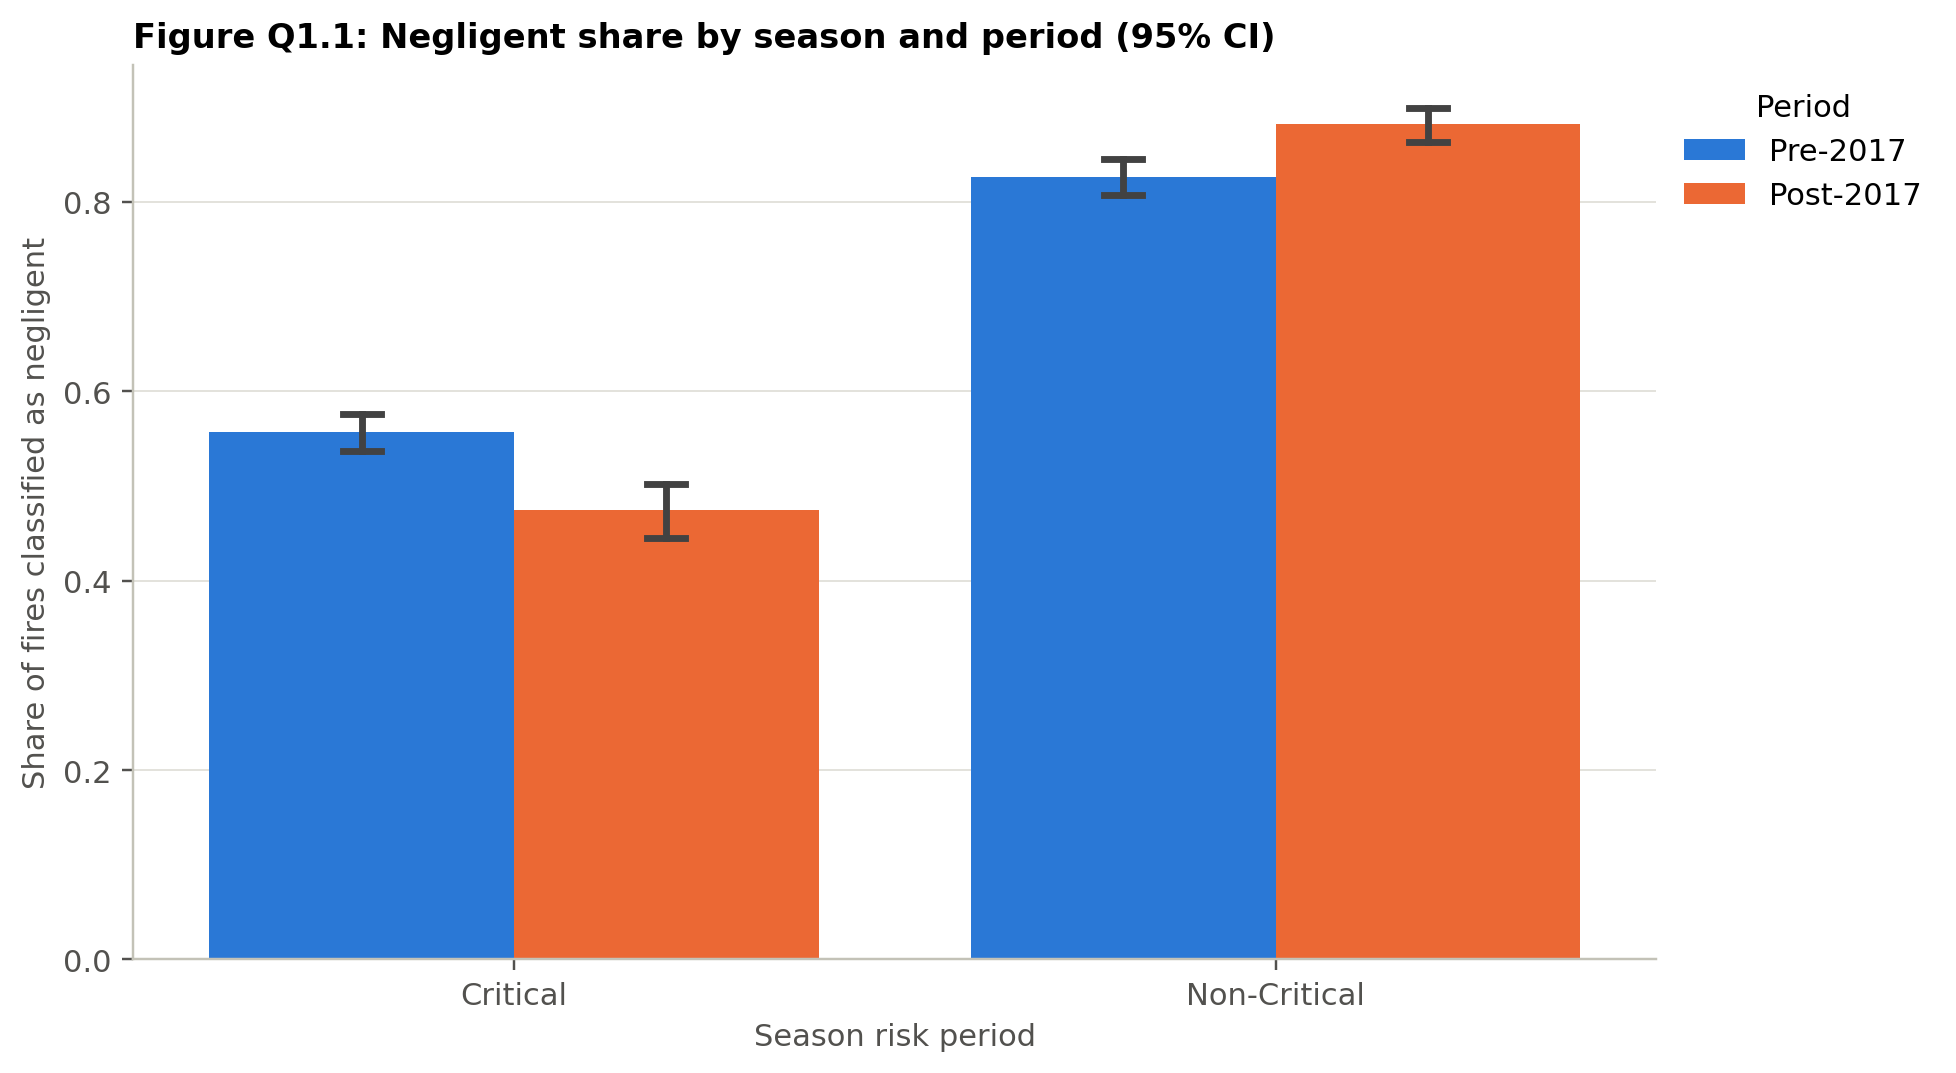

In [14]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(
    data=q1, x="Season_Risk_Period", y=(q1["Cause_Type"] == "Negligent").astype(int),
    hue="Period", order=SEASON_ORDER, hue_order=PERIOD_ORDER, palette=PAL_PERIOD,
    saturation=1, errorbar="ci", capsize=0.1, ax=ax
)
ax.set_title("Figure Q1.1: Negligent share by season and period (95% CI)")
ax.set_xlabel("Season risk period")
ax.set_ylabel("Share of fires classified as negligent")
ax.legend(title="Period", loc="upper left", bbox_to_anchor=(1.0, 1.0))
plt.tight_layout()
plt.show()

Figure Q1.1 shows the change in the proportion of negligent fires between the pre-2017 and post-2017 periods, split by season.

The decline in fires seems to happen mainly in the **Critical** period. The error bars do not overlap, meaning this drop is likely statistically significant.

In the **Non-Critical** period, the share remains very high in both periods. The slight increase is small and the error bars overlap, suggesting there is no real change.

#### Negligence over time

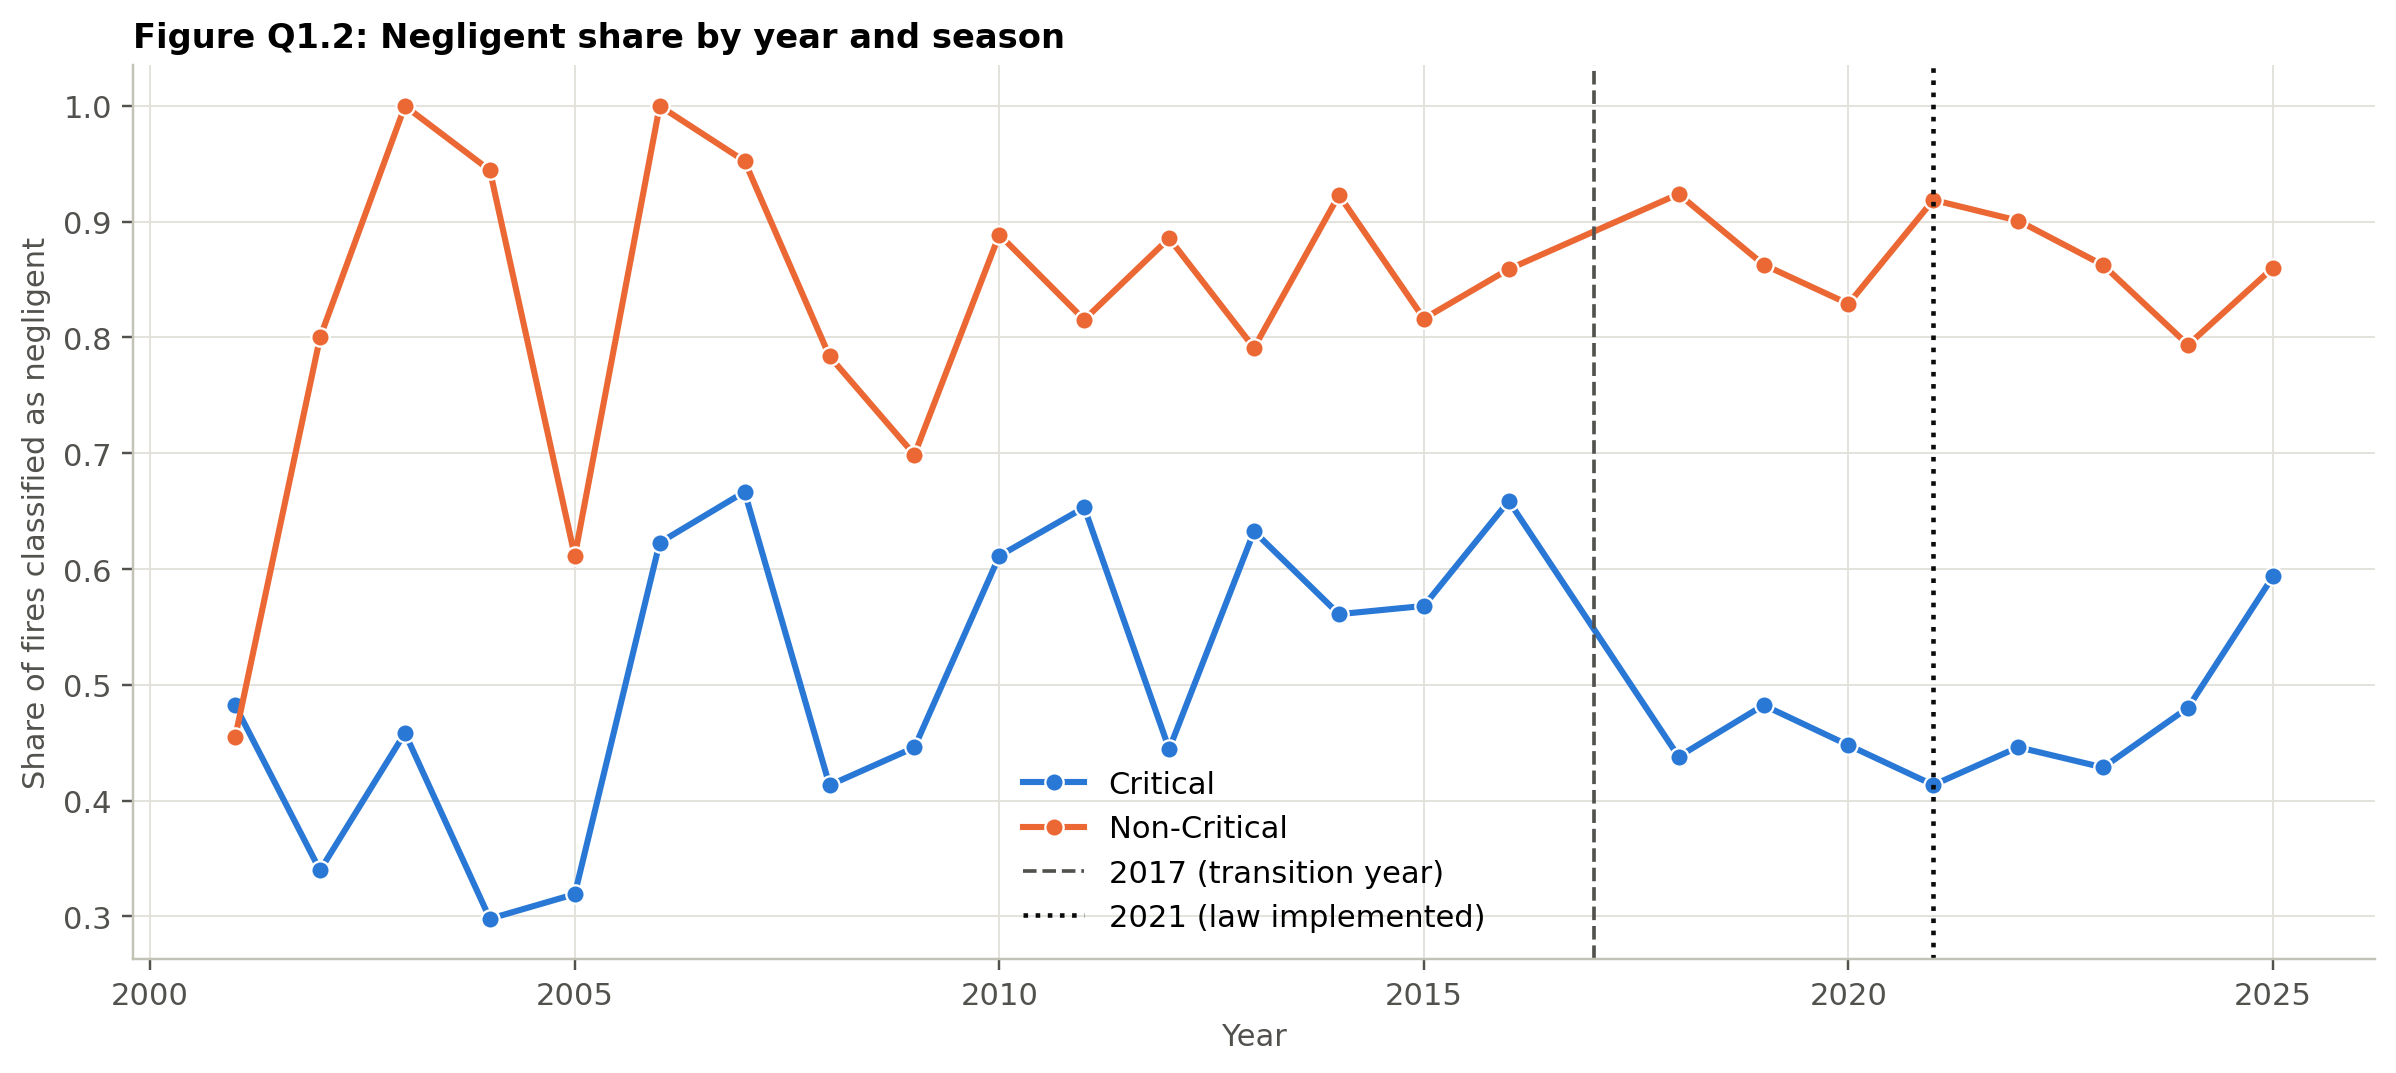

In [15]:
year_season = (
    q1.groupby(["Ano", "Season_Risk_Period"])["Cause_Type"]
      .apply(lambda s: (s == "Negligent").mean())
      .reset_index(name="negligent_share")
)

fig, ax = plt.subplots(figsize=(11, 5))
sns.lineplot(data=year_season, x="Ano", y="negligent_share",
             hue="Season_Risk_Period", hue_order=SEASON_ORDER, palette=PAL_SEASON,
             marker="o", linewidth=2, ax=ax)
ax.axvline(2017, color=MUTED, linestyle="--", linewidth=1.2, label="2017 (transition year)")
ax.axvline(2021, color=INK, linestyle=":", linewidth=1.5, label="2021 (law implemented)")
ax.set_title("Figure Q1.2: Negligent share by year and season")
ax.set_xlabel("Year")
ax.set_ylabel("Share of fires classified as negligent")
ax.legend(title="")
plt.tight_layout()
plt.show()

#### Summary

To explore this question, we split the data into pre-2017 and post-2017 periods and compared the negligent share between critical and non-critical seasons. The visualisations and proportions showed a clear divergence between the seasons. In the critical period, the negligent share dropped from 55.7% to 47.4% after 2017. But, in the non-critical months, the share of negligent fires actually increased from 82.6% to 88.2%.

This means that the seasons do not behave in the same way, the reduction in negligent ignitions did not affect the whole year. It was entirely concentrated in the critical summer months.

Also, if the law implemented in 2021 actually deterred negligent ignitions, we would expect a sharp drop right after the 2021 line in Figure Q1.2. Instead, the non-critical line stays flat, and the critical line drops slightly in 2021 but climbs right back up by 2024/2025.

---

### 3.2 Q2: Daily Negligent Ignitions on Weekends and Weekdays

In this section we address Q2, which asks whether the mean number of daily negligent wildfire ignitions differed significantly between weekends and weekdays in the post-2017 period across the municipalities of Chaves, Montalegre, Ourém and Tomar.

Before conducting inferential testing, we examine the sample distribution of daily negligent ignitions conditional on active fire days ($Y \ge 1$) across weekdays and weekends, contrasting the pre-2017 and post-2017 cohorts.

**Methodological note on zero-area records ($0\text{ ha}$).** All validated negligent wildfire occurrences recorded in the SGIF database, including those with a final burnt area of $0\text{ ha}$ (such as immediate extinguishments), are explicitly **retained** in the daily count aggregation (`Daily_Ignitions_Count`), as the research question evaluates ignition incidence rather than fire size. Because count variables present positive skewness, both robust measures (median, IQR) and parametric metrics (mean, standard deviation) are reported to fully assess central tendency and dispersion.

#### Data

In [16]:
q2 = pd.read_excel(processed / "q2_daily_ignitions.xlsx")

# fixed data types and factor orders
q2["Date"] = pd.to_datetime(q2["Date"])
q2["Period"] = pd.Categorical(q2["Period"], categories=PERIOD_ORDER, ordered=True)
q2["Day_Type"] = pd.Categorical(q2["Day_Type"], categories=DAY_ORDER, ordered=True)

q2.info()
q2.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2897 entries, 0 to 2896
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   Concelho               2897 non-null   object        
 1   Date                   2897 non-null   datetime64[ns]
 2   Period                 2897 non-null   category      
 3   Daily_Ignitions_Count  2897 non-null   int64         
 4   Day_Type               2897 non-null   category      
dtypes: category(2), datetime64[ns](1), int64(1), object(1)
memory usage: 73.9+ KB


,Concelho,Date,Period,Daily_Ignitions_Count,Day_Type
0,Chaves,2001-07-21,Pre-2017,1,Weekend
1,Chaves,2001-07-29,Pre-2017,1,Weekend
2,Chaves,2001-08-10,Pre-2017,1,Weekday
3,Chaves,2001-08-13,Pre-2017,1,Weekday
4,Chaves,2001-08-16,Pre-2017,1,Weekday


#### Descriptive statistics

In [17]:
# Summary statistics by Period and Day_Type
summary_stats = (
    q2.groupby(["Period", "Day_Type"], observed=False)["Daily_Ignitions_Count"]
    .agg(
        n="count",
        mean="mean",
        std="std",
        median="median",
        iqr=lambda x: x.quantile(0.75) - x.quantile(0.25),
        min="min",
        max="max",
    )
    .reset_index()
)

# standard error of the mean (SEM)
summary_stats["sem"] = summary_stats["std"] / np.sqrt(summary_stats["n"])

print("Summary statistics for daily negligent ignitions:")
display(summary_stats.round(3))

Summary statistics for daily negligent ignitions:


,Period,Day_Type,n,mean,std,median,iqr,min,max,sem
0,Pre-2017,Weekday,1253,1.505,1.056,1.0,1.0,1,10,0.030
1,Pre-2017,Weekend,505,1.519,1.067,1.0,1.0,1,8,0.047
2,Post-2017,Weekday,802,1.455,1.161,1.0,0.0,1,11,0.041
3,Post-2017,Weekend,337,1.570,1.402,1.0,1.0,1,12,0.076


#### Distribution of daily negligent ignitions

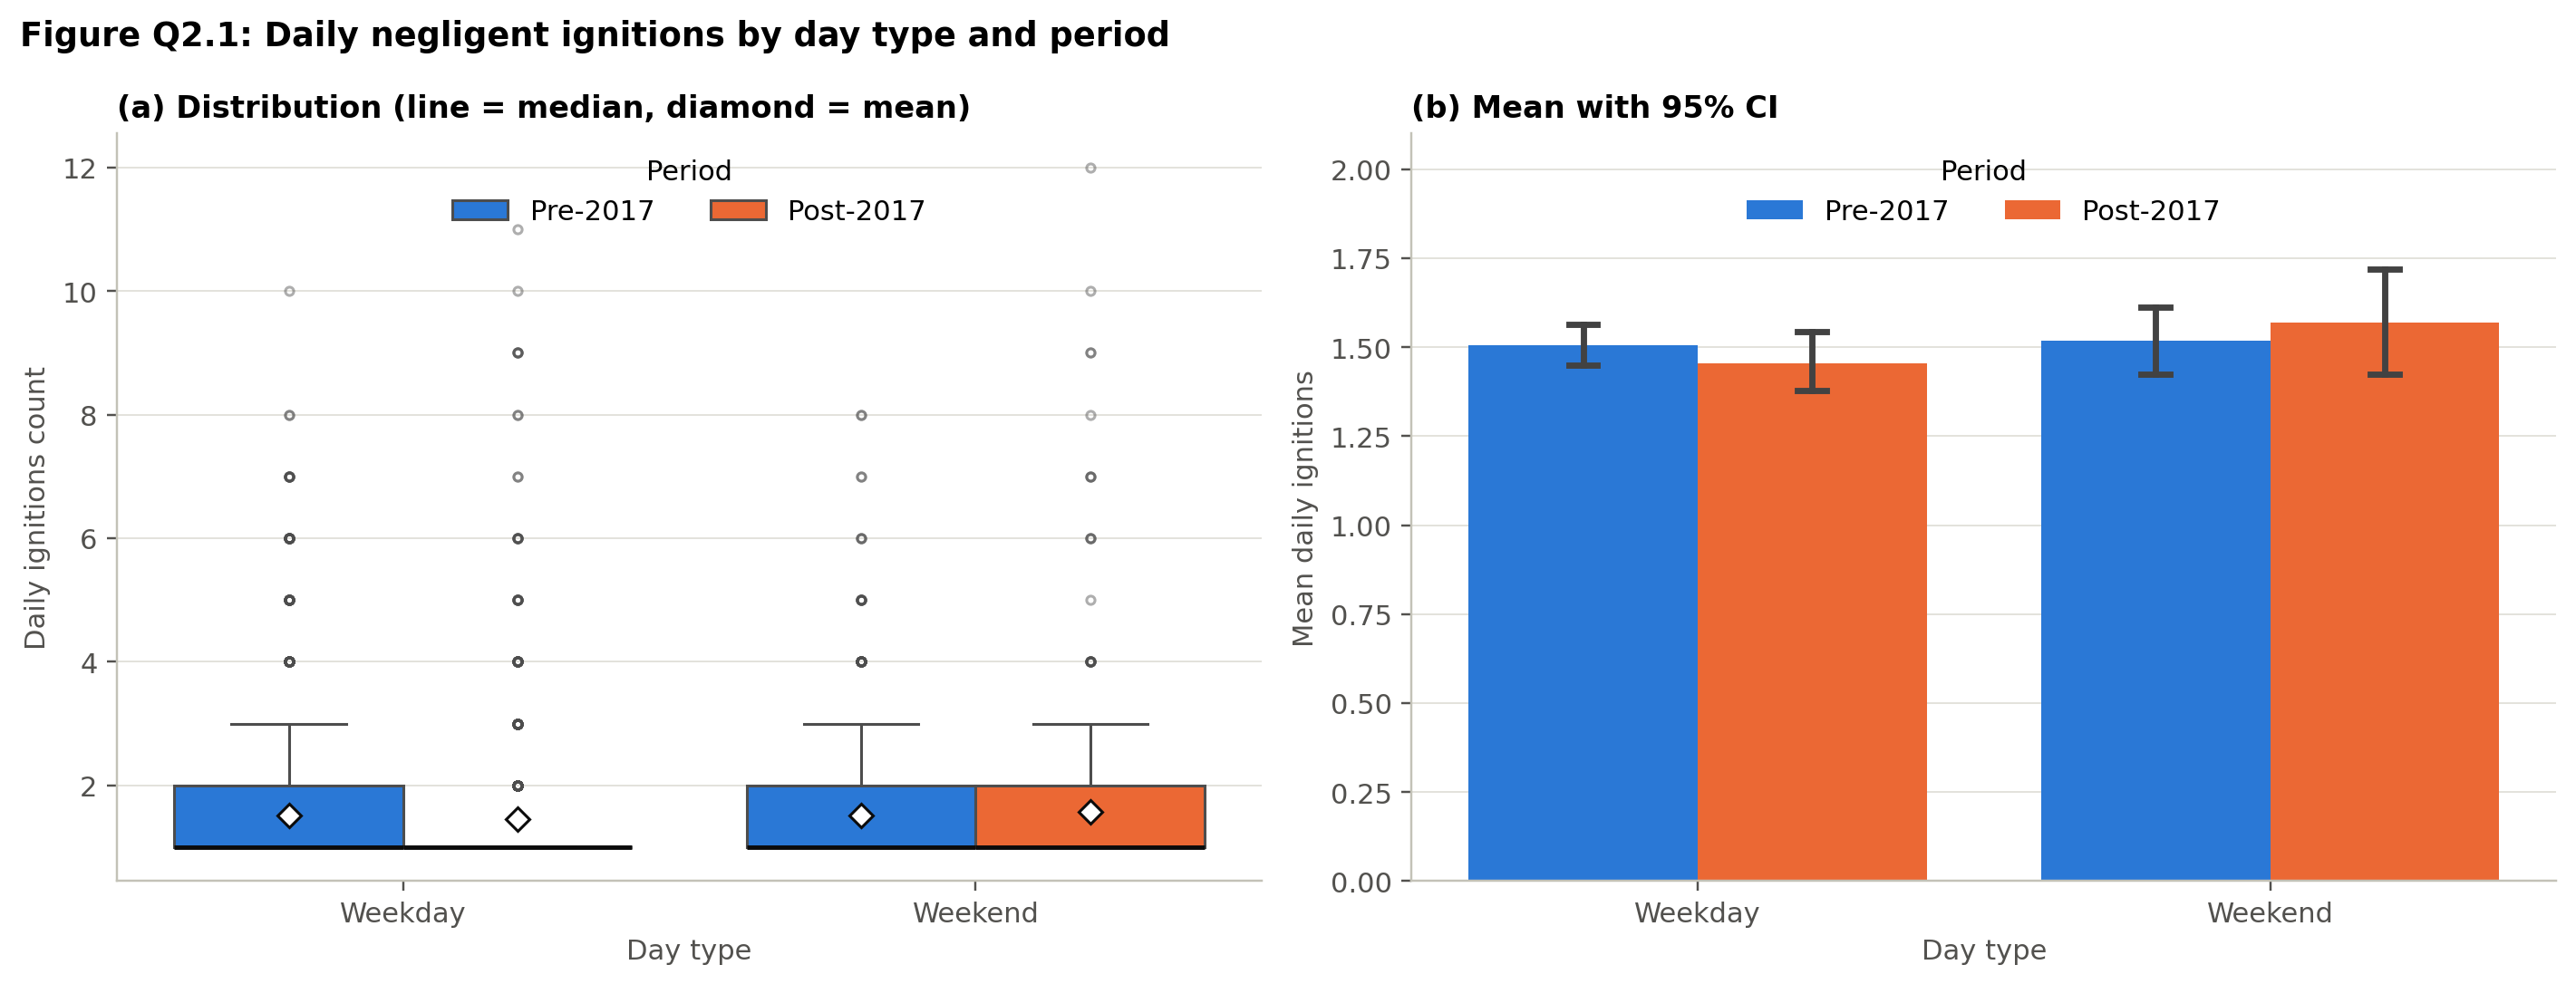

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# (a) Boxplot
sns.boxplot(
    data=q2, x="Day_Type", y="Daily_Ignitions_Count", hue="Period",
    order=DAY_ORDER, hue_order=PERIOD_ORDER, palette=PAL_PERIOD, saturation=1,
    ax=axes[0], showmeans=True,
    meanprops={"marker": "D", "markerfacecolor": "white", "markeredgecolor": INK, "markersize": 6},
    medianprops={"color": INK, "linewidth": 1.6},
    flierprops={"marker": "o", "markersize": 3, "alpha": .45},
)
axes[0].set_title("(a) Distribution (line = median, diamond = mean)")
axes[0].set_xlabel("Day type")
axes[0].set_ylabel("Daily ignitions count")
axes[0].legend(title="Period", loc="upper center", ncol=2)

# (b) Means with 95% CI
sns.barplot(
    data=q2, x="Day_Type", y="Daily_Ignitions_Count", hue="Period",
    order=DAY_ORDER, hue_order=PERIOD_ORDER, palette=PAL_PERIOD, saturation=1,
    errorbar=("ci", 95), capsize=0.1, ax=axes[1]
)
axes[1].set_title("(b) Mean with 95% CI")
axes[1].set_xlabel("Day type")
axes[1].set_ylabel("Mean daily ignitions")
axes[1].set_ylim(0, 2.1)
axes[1].legend(title="Period", loc="upper center", ncol=2)

fig_title(fig, "Figure Q2.1: Daily negligent ignitions by day type and period")
plt.tight_layout()
plt.show()

---

### 3.3 Q3: Burnt Area across Municipalities

In this section we address Q3, which asks whether the mean log-transformed burnt area per fire differs significantly across Chaves, Montalegre, Ourém and Tomar during 2018–2025.

| Element | Definition |
|---|---|
| Unit of observation | One wildfire occurrence (one SGIF record) |
| Response variable | ln(`Total_Burnt_Area`): natural logarithm of the final burnt area in hectares |
| Factor | `Concelho` (municipality), 4 levels |
| Period | 2018–2025 (filtered with `Ano`; 2017 is excluded as a transition year) |
| Significance level | α = 0.05 |

**What the ANOVA compares.** For strictly positive areas, the mean of ln(area) is the logarithm of the *geometric mean* of the area. Therefore, comparing means of ln(area) is equivalent to comparing geometric means (the "typical" fire) on the original scale, and differences become **ratios**. The ANOVA does **not** directly test equality of the *arithmetic* mean burnt area in hectares; the arithmetic means are reported only as descriptive statistics.

**Why the logarithm?** Burnt areas are extremely right-skewed (a few huge fires and many tiny ones). The exploratory analysis below and the assumption checks in Section 4.3 show that the classical ANOVA assumptions are not met on the original scale but are reasonably met on the log scale.

#### Data preparation and validation

The Q3 file saved in Section 2.3 covers both periods. Since Q3 only concerns 2018–2025, the sample is rebuilt here from the main processed file, filtered by `Ano` and **reconciled** with the Q3 file, so that the notebook fails loudly if a wrong version is used. No original file is modified.

In [19]:
AREA = "Total_Burnt_Area"          # burnt area in hectares (original scale)
STUDY_YEARS = (2018, 2025)
# No randomness is used in this analysis, so the results are fully deterministic.

wf = pd.read_excel(processed / "wildfires_processed.xlsx")
wf["Codigo_SGIF"] = wf["Codigo_SGIF"].astype(str)      # identifiers mix int and str in the Excel file
print("Processed file:", wf.shape)

# The Q3 file is only used to cross-check; if it is locked (open in Excel/OneDrive) we continue without it
try:
    q3_file = pd.read_excel(processed / "q3_burnt_area_municipality.xlsx")
    q3_file["Codigo_SGIF"] = q3_file["Codigo_SGIF"].astype(str)
    print("Q3 file:", q3_file.shape, "| years", q3_file["Ano"].min(), "-", q3_file["Ano"].max())
except (PermissionError, FileNotFoundError) as err:
    q3_file = None
    print("Q3 file not readable, cross-check skipped:", type(err).__name__)

# Step-by-step construction of the Q3 sample, with an attrition log
steps = []
d = wf.copy();                                    steps.append(("Processed file (2001-2025, 4 municipalities)", len(d)))
d = d[d["Concelho"].isin(MUNICIPALITIES)];        steps.append(("Keep the 4 municipalities", len(d)))
d = d[d["Ano"].between(*STUDY_YEARS)];            steps.append(("Keep 2018-2025 (uses Ano, not the derived Period)", len(d)))
d = d.dropna(subset=[AREA]);                      steps.append(("Drop missing burnt area", len(d)))
d = d[d[AREA] >= 0];                              steps.append(("Drop negative burnt area (invalid)", len(d)))

# Primary descriptive sample: ALL valid occurrences, whatever the cause. Nothing is dropped for cause or size.
q3 = d.reset_index(drop=True)
q3["Concelho"] = pd.Categorical(q3["Concelho"], categories=MUNICIPALITIES, ordered=True)

# Analytical sample for the ANOVA: ln() is only defined for positive areas
q3_ln = q3[q3[AREA] > 0].copy()
q3_ln["ln_area"] = np.log(q3_ln[AREA])
steps.append(("ANOVA sample: drop fires with 0 ha (ln undefined)", len(q3_ln)))

attrition = pd.DataFrame(steps, columns=["step", "n_remaining"])
attrition["removed"] = -attrition["n_remaining"].diff().fillna(0).astype(int)
print(attrition.to_string(index=False))

Processed file: (14520, 23)
Q3 file: (13816, 23) | years 2001 - 2025
                                             step  n_remaining  removed
     Processed file (2001-2025, 4 municipalities)        14520        0
                        Keep the 4 municipalities        14520        0
Keep 2018-2025 (uses Ano, not the derived Period)         2739    11781
                          Drop missing burnt area         2739        0
               Drop negative burnt area (invalid)         2739        0
ANOVA sample: drop fires with 0 ha (ln undefined)         2738        1


In [20]:
# Validation assertions
assert q3["Ano"].between(2018, 2025).all(),                      "years outside 2018-2025"
assert set(q3["Concelho"].astype(str)) == set(MUNICIPALITIES),   "missing municipality"
assert pd.api.types.is_numeric_dtype(q3[AREA]) and q3[AREA].notna().all() and (q3[AREA] >= 0).all()
assert q3["Codigo_SGIF"].is_unique,                              "duplicated SGIF identifiers"
assert (q3[AREA] == q3["AreaTotal_ha"]).all(),                   "Total_Burnt_Area differs from AreaTotal_ha"
assert (q3["Period"] == "Post-2017").all(),                      "Period label inconsistent with Ano"
assert len(q3) == 2739 and len(q3_ln) == 2738 and np.isfinite(q3_ln["ln_area"]).all()
assert q3["Concelho"].value_counts().to_dict() == {"Montalegre": 1146, "Ourém": 620, "Chaves": 555, "Tomar": 418}

if q3_file is not None:   # reconcile with the Q3 file
    in_window = q3_file[q3_file["Ano"].between(*STUDY_YEARS)]
    assert set(in_window["Codigo_SGIF"]) == set(q3["Codigo_SGIF"]), "does not reconcile with the Q3 file"
print("All validation checks passed. n =", len(q3), "| ANOVA sample n =", len(q3_ln))

# Quality-control summary
g_ = q3.groupby("Concelho", observed=True)
qc = pd.DataFrame({"n": g_.size(), "area = 0 ha": g_[AREA].apply(lambda s: int((s == 0).sum())),
                   "% < 1 ha": g_[AREA].apply(lambda s: round(100 * (s < 1).mean(), 1)),
                   "missing cause": g_["TipoCausa"].apply(lambda s: int(s.isna().sum()))})
print(qc.to_string())
print("Temporal coverage:", q3["DataHoraAlerta"].min(), "->", q3["DataHoraAlerta"].max(),
      "| 2025 records in November:", int((q3.loc[q3["Ano"] == 2025, "DataHoraAlerta"].dt.month == 11).sum()), "(2025 is incomplete)")

# Recorded areas near 0.01 ha
near = np.isclose(q3[AREA], 0.01, atol=1e-9)
print(f"Areas below 0.01 ha: {(q3[AREA] < 0.01).sum()} fires (smallest positive area: {q3.loc[q3[AREA] > 0, AREA].min():.5f} ha); "
      f"areas of exactly 0.01 ha: {near.sum()} fires ({100 * near.mean():.1f} %)")

All validation checks passed. n = 2739 | ANOVA sample n = 2738
               n  area = 0 ha  % < 1 ha  missing cause
Concelho                                              
Chaves       555            0      75.3              2
Montalegre  1146            0      66.5             10
Ourém        620            1      89.5              0
Tomar        418            0      93.8              0
Temporal coverage: 2018-01-29 16:23:00 -> 2025-11-04 18:49:00 | 2025 records in November: 1 (2025 is incomplete)
Areas below 0.01 ha: 312 fires (smallest positive area: 0.00005 ha); areas of exactly 0.01 ha: 315 fires (11.5 %)


In [21]:
# Cause categories (reported as recorded; nothing is excluded for being unknown or non-human)
cause_tab = (q3.assign(TipoCausa=q3["TipoCausa"].fillna("(missing)")).groupby("TipoCausa")[AREA]
               .agg(n="size", mean_ha="mean", median_ha="median", total_ha="sum").round(2).sort_values("n", ascending=False))
cause_tab["% of total area"] = (100 * cause_tab["total_ha"] / cause_tab["total_ha"].sum()).round(1)
print(cause_tab.to_string())

# Reignitions: how many follow another fire in the same parish within 3 days? (a proximity heuristic, NOT proof of a link)
rk = q3[q3["TipoCausa"] == "Reacendimento"]
def has_recent_fire(x):
    prev = q3[(q3["Concelho"] == x["Concelho"]) & (q3["Freguesia"] == x["Freguesia"]) &
              (q3["DataHoraAlerta"] < x["DataHoraAlerta"]) & (q3["DataHoraAlerta"] >= x["DataHoraAlerta"] - pd.Timedelta(days=3))]
    return len(prev) > 0
linked = int(rk.apply(has_recent_fire, axis=1).sum())
print(f"Reignition records: {len(rk)}; {linked} ({100 * linked / len(rk):.0f} %) follow another fire in the same parish within 3 days.")

# Alternative samples used in the robustness checks (Section 4.3)
sample_human = q3[q3["TipoCausa"].isin(["Negligente", "Intencional"])]
sample_no_2025 = q3[q3["Ano"] != 2025]
print("Human-related only:", len(sample_human), "| excluding 2025:", len(sample_no_2025))

                  n  mean_ha  median_ha  total_ha  % of total area
TipoCausa                                                         
Negligente     1696     8.73       0.29  14798.58             41.5
Intencional     789    23.23       0.08  18326.01             51.4
Reacendimento   130    11.29       0.08   1468.02              4.1
Desconhecida     98    10.38       0.02   1017.21              2.9
Natural          14     0.83       0.05     11.68              0.0
(missing)        12     3.53       2.00     42.41              0.1
Reignition records: 130; 90 (69 %) follow another fire in the same parish within 3 days.
Human-related only: 2485 | excluding 2025: 2419


**Decisions and findings**

- **Sample.** After filtering to 2018–2025 there are 2,739 fires (Chaves 555, Montalegre 1,146, Ourém 620, Tomar 418), with no missing or negative areas and no duplicated identifiers. The sample reconciles with the source files. Descriptive statistics of the original area use all 2,739 fires.
- **ANOVA sample.** One fire has an area of exactly 0 ha, for which ln(area) is undefined; it is left out of the ANOVA, which therefore uses n = 2,738 (documented in the attrition log above).
- **All causes are kept** (literal reading of Q3). Only the human-related subset (intentional/negligent) is used later as a sensitivity check.
- **Reignitions are kept.** Each has its own SGIF code and area. Most of them follow another fire in the same parish within 3 days, which suggests that some may be continuations of earlier events, but this proximity rule does not prove it.
- **No outlier removal.** The largest fires are internally consistent records (their areas equal the sum of the land-cover components and their durations are plausible), so they are legitimate extreme events.
- **0.01 ha.** There is a noticeable concentration of recorded areas at exactly 0.01 ha, possibly reflecting rounding or reporting conventions. It is not a minimum recorded value: hundreds of fires have areas below 0.01 ha.
- **2025 is incomplete** (alerts end on 4 November).

#### Descriptive statistics

We describe the data before testing. Descriptive differences below are **not** evidence of significant differences. The original area (hectares) is used for the descriptive statistics; the **geometric mean** is the quantity that the ANOVA on ln(area) will compare, so it is shown next to the arithmetic mean and the median.

- **Arithmetic mean:** average area (very sensitive to huge fires). **Median:** the middle fire. **Geometric mean:** exp(mean of ln area), for fires with area > 0.
- **Q1/Q3:** 25 % / 75 % of fires have an area below these values; **IQR** = Q3 − Q1.

In [22]:
q3_groups = {m: q3.loc[q3["Concelho"] == m, AREA].to_numpy() for m in MUNICIPALITIES}                   # original scale (ha), n = 2,739
q3_ln_groups = {m: q3_ln.loc[q3_ln["Concelho"] == m, "ln_area"].to_numpy() for m in MUNICIPALITIES}    # ln(ha), n = 2,738

def describe(a):
    a = pd.Series(a); lo, hi = a.quantile(.25), a.quantile(.75); pos = a[a > 0]
    return pd.Series({"n": len(a), "arithmetic mean": a.mean(), "median": a.median(), "geometric mean": np.exp(np.log(pos).mean()),
                      "sd": a.std(ddof=1), "variance": a.var(ddof=1), "min": a.min(), "q1": lo, "q3": hi, "iqr": hi - lo,
                      "p90": a.quantile(.90), "p99": a.quantile(.99), "max": a.max(),
                      "% zero": 100 * (a == 0).mean(), "% < 1 ha": 100 * (a < 1).mean()})

summary = pd.DataFrame({m: describe(q3_groups[m]) for m in MUNICIPALITIES}).T
summary.loc["All"] = describe(q3[AREA].to_numpy())
print("Burnt area per fire, original scale (hectares). Geometric mean computed for areas > 0.")
print(summary.round(3).to_string())

by_mun = summary.loc[MUNICIPALITIES]
print()
print("Ranking by arithmetic mean:", " > ".join(by_mun["arithmetic mean"].sort_values(ascending=False).index))
print("Ranking by median         :", " > ".join(by_mun["median"].sort_values(ascending=False).index))
print("Ranking by geometric mean :", " > ".join(by_mun["geometric mean"].sort_values(ascending=False).index))
print(f"Largest/smallest sample variance (original scale): {by_mun['variance'].max() / by_mun['variance'].min():.1f}")

# Influence of the largest fires on the arithmetic mean (descriptive)
rows = []
for m in MUNICIPALITIES:
    a = np.sort(q3_groups[m])
    rows.append({"municipality": m, "arithmetic mean (ha)": a.mean(), "mean without its 5 largest fires (ha)": a[:-5].mean(),
                 "share of area in 5 largest fires (%)": 100 * a[-5:].sum() / a.sum(), "largest fire (ha)": a[-1]})
print()
print(pd.DataFrame(rows).set_index("municipality").round(2).to_string())

Burnt area per fire, original scale (hectares). Geometric mean computed for areas > 0.
                 n  arithmetic mean  median  geometric mean       sd   variance  min     q1     q3    iqr     p90      p99       max  % zero  % < 1 ha
Chaves       555.0           18.125   0.158           0.139  191.871  36814.377  0.0  0.010  0.962  0.952   3.000  311.852  3367.930   0.000    75.315
Montalegre  1146.0           13.682   0.772           0.505  130.046  16911.923  0.0  0.100  3.038  2.938  21.145  167.993  4147.733   0.000    66.492
Ourém        620.0           13.869   0.054           0.051  159.285  25371.664  0.0  0.012  0.196  0.183   1.117  212.112  2936.000   0.161    89.516
Tomar        418.0            3.172   0.045           0.041   35.486   1259.224  0.0  0.010  0.202  0.191   0.502   23.690   606.525   0.000    93.780
All         2739.0           13.021   0.162           0.158  143.072  20469.475  0.0  0.017  0.900  0.883   7.500  171.175  4147.733   0.037    77.656

Rankin

#### Burnt area per fire by municipality

In Figure Q3.1 the boxes show the typical fire (median and quartiles) and the points show the extremes. The vertical axis is **logarithmic** (each gridline is ×10), because on the raw scale a few fires thousands of times larger than the rest would squash the boxes flat. The diamond is the **geometric mean**, the quantity compared by the ANOVA (it is not the arithmetic mean).

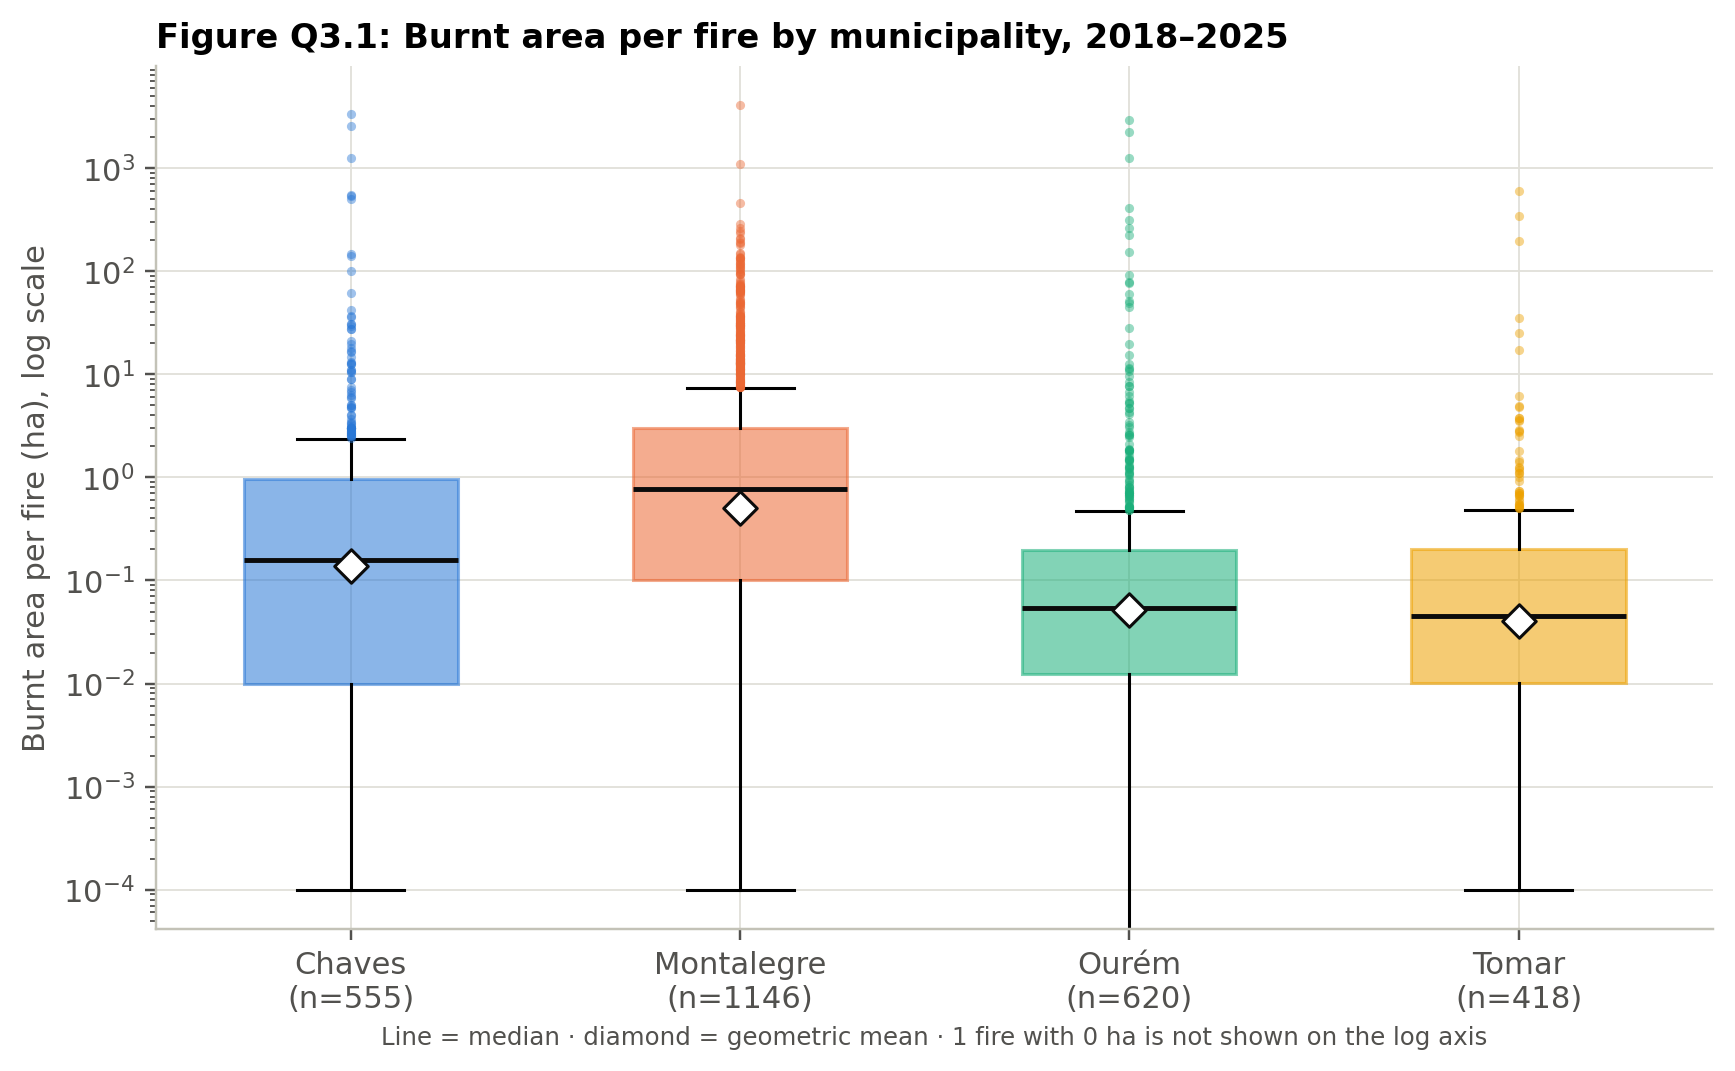

In [23]:
labels_n = [f"{m}\n(n={len(q3_groups[m])})" for m in MUNICIPALITIES]
fig, ax = plt.subplots(figsize=(8, 5))
bp = ax.boxplot([q3_groups[m] for m in MUNICIPALITIES], patch_artist=True, widths=0.55,
                flierprops=dict(marker="o", markersize=3, alpha=.45, markeredgewidth=0),
                medianprops=dict(color=INK, linewidth=1.6))
for patch, fl, m in zip(bp["boxes"], bp["fliers"], MUNICIPALITIES):
    patch.set(facecolor=PAL_MUN[m], alpha=.55, edgecolor=PAL_MUN[m]); fl.set(markerfacecolor=PAL_MUN[m], markeredgecolor=PAL_MUN[m])
ax.scatter(range(1, 5), [np.exp(q3_ln_groups[m].mean()) for m in MUNICIPALITIES], marker="D", s=60,
           facecolor="white", edgecolor=INK, zorder=4)
ax.set_xticks(range(1, 5)); ax.set_xticklabels(labels_n)
ax.set_yscale("log"); ax.set_ylabel("Burnt area per fire (ha), log scale")
ax.set_title("Figure Q3.1: Burnt area per fire by municipality, 2018–2025")
ax.set_xlabel(f"Line = median · diamond = geometric mean · {int((q3[AREA] == 0).sum())} fire with 0 ha is not shown on the log axis", fontsize=8)
plt.tight_layout(); plt.show()

#### How much do a few fires and a few years matter?

Figure Q3.2 has two panels. (a) Fires sorted from largest to smallest; the curve gives the cumulative share of total burnt area. (b) Total burnt area (hectares, original scale) by year and municipality.

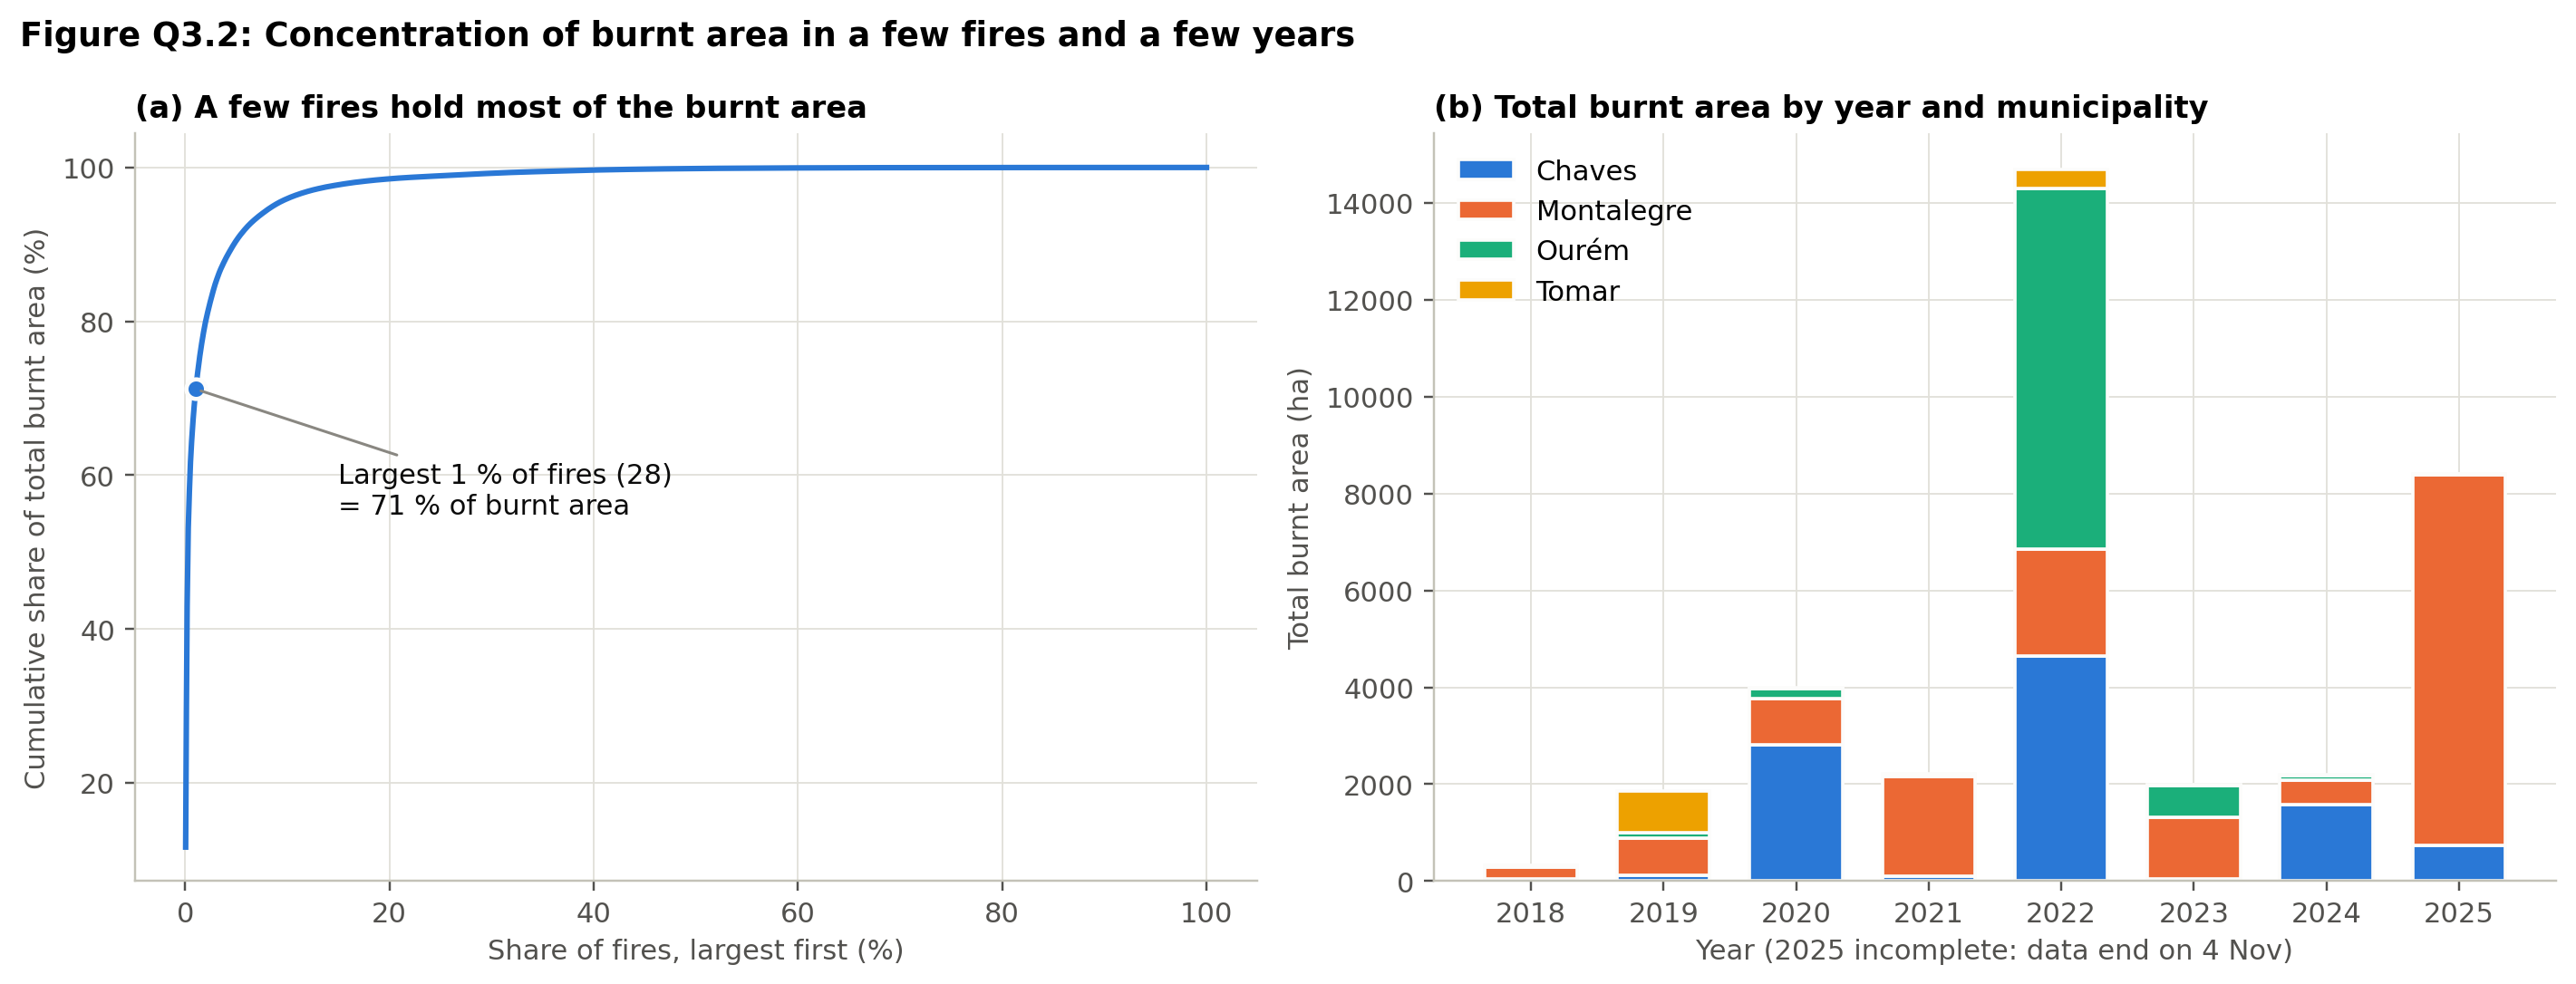

Ano
2018     0.9
2019     5.2
2020    11.2
2021     6.2
2022    41.2
2023     5.6
2024     6.1
2025    23.6
Largest 1 % of fires hold 71.2 % of the total area ( 28 fires )


In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ax = axes[0]
a = np.sort(q3[AREA].to_numpy())[::-1]
share_fires = np.arange(1, len(a) + 1) / len(a); share_area = np.cumsum(a) / a.sum()
ax.plot(100 * share_fires, 100 * share_area, color=BLUE, linewidth=2)
k_top = int(np.ceil(0.01 * len(a)))
ax.scatter([100 * k_top / len(a)], [100 * share_area[k_top - 1]], color=BLUE, s=50, zorder=3, edgecolor=SURFACE, linewidth=1.5)
ax.annotate(f"Largest 1 % of fires ({k_top})\n= {100 * share_area[k_top - 1]:.0f} % of burnt area", xy=(100 * k_top / len(a), 100 * share_area[k_top - 1]),
            xytext=(15, 55), arrowprops=dict(arrowstyle="-", color="#898781"), color=INK)
ax.set_xlabel("Share of fires, largest first (%)"); ax.set_ylabel("Cumulative share of total burnt area (%)")
ax.set_title("(a) A few fires hold most of the burnt area")

ax = axes[1]
by_year = q3.pivot_table(index="Ano", columns="Concelho", values=AREA, aggfunc="sum", observed=True)[MUNICIPALITIES]
bottom = np.zeros(len(by_year))
for m in MUNICIPALITIES:
    ax.bar(by_year.index, by_year[m], bottom=bottom, color=PAL_MUN[m], label=m, edgecolor=SURFACE, linewidth=1.2, width=.7)
    bottom += by_year[m].to_numpy()
ax.set_ylabel("Total burnt area (ha)"); ax.set_xlabel("Year (2025 incomplete: data end on 4 Nov)")
ax.set_title("(b) Total burnt area by year and municipality"); ax.legend(loc="upper left")

fig_title(fig, "Figure Q3.2: Concentration of burnt area in a few fires and a few years")
plt.tight_layout(); plt.show()

yr = by_year.sum(axis=1)
print((100 * yr / yr.sum()).round(1).rename("% of total burnt area").to_string())
print("Largest 1 % of fires hold", round(100 * share_area[k_top - 1], 1), "% of the total area (", k_top, "fires )")

#### Summary

The points below are descriptive only.

- **Many small fires, a few giant ones.** 77.7 % of fires burn less than 1 ha, yet the 28 largest (1 %) account for 71.2 % of the burnt area. The overall arithmetic mean (13.0 ha) is about 80 times the median (0.16 ha).
- **Arithmetic mean, median and geometric mean rank the municipalities differently.** By arithmetic mean: Chaves (18.1) > Ourém (13.9) > Montalegre (13.7) > Tomar (3.2 ha). By median and by geometric mean: Montalegre > Chaves > Ourém > Tomar (geometric means ≈ 0.50, 0.14, 0.05 and 0.04 ha). The arithmetic means are driven by a handful of huge fires: the five largest fires hold 83 % (Chaves), 84 % (Ourém), 91 % (Tomar) and 40 % (Montalegre) of the area of each municipality.
- **A few years dominate:** 2022 holds 41.2 % and 2025 (incomplete) 23.6 % of the burnt area.
- **Spread.** On the original scale the sample variances differ by a factor of 29 between municipalities.
- No negative or missing areas were found, and the largest fires are internally consistent records.

---

### 3.4 Q4: Burnt Area by Cause Type and Period

In this section we address Q4, which asks whether the gap in final burnt area between intentional and negligent fires became smaller after 2017 in the four municipalities under study.

The burnt area is analysed on a log10 scale because it is extremely right-skewed, with most fires below 1 ha and a few above 1,000 ha. On this scale, the mean corresponds to the geometric mean, which describes the typical fire better than the arithmetic mean.

#### Data

In [25]:
q4 = pd.read_excel(processed / "q4_burnt_area_cause_period.xlsx")

# fixed order of the factor levels for tables and plots
q4["Period"] = pd.Categorical(q4["Period"], categories=PERIOD_ORDER, ordered=True)
q4["Cause_Type"] = pd.Categorical(q4["Cause_Type"], categories=CAUSE_ORDER, ordered=True)

pd.crosstab(q4["Cause_Type"], q4["Period"], margins=True)

Period,Pre-2017,Post-2017,All
Cause_Type,,,
Intentional,1381,789,2170
Negligent,2653,1696,4349
All,4034,2485,6519


#### Descriptive statistics

In [26]:
q4_desc = (
    q4.groupby(["Period", "Cause_Type"], observed=True)
      .agg(n=("Log_Total_Burnt_Area", "size"),
           mean_log=("Log_Total_Burnt_Area", "mean"),
           sd_log=("Log_Total_Burnt_Area", "std"),
           median_ha=("Total_Burnt_Area", "median"),
           mean_ha=("Total_Burnt_Area", "mean"))
)
# geometric mean in hectares (back-transformation of the log mean)
q4_desc["geom_mean_ha"] = 10 ** q4_desc["mean_log"]
q4_desc.round(3)

n  mean_log  sd_log  median_ha  mean_ha  \
Period    Cause_Type                                                
Pre-2017  Intentional  1381    -0.553   1.228      0.260   24.761   
          Negligent    2653    -0.395   1.109      0.500    8.622   
Post-2017 Intentional   789    -0.934   1.195      0.085   23.227   
          Negligent    1696    -0.634   1.170      0.290    8.726   

                       geom_mean_ha  
Period    Cause_Type                 
Pre-2017  Intentional         0.280  
          Negligent           0.403  
Post-2017 Intentional         0.116  
          Negligent           0.232

The design is unbalanced (from 789 to 2,653 fires per group), but every group is large. The table also shows why the log scale is needed. Intentional fires have a much higher arithmetic mean (around 23 to 25 ha vs 9 ha), but a lower median (0.26 vs 0.50 ha before 2017), because a few very large intentional fires inflate the mean. The geometric means agree with the medians.

#### Distribution of burnt area by group

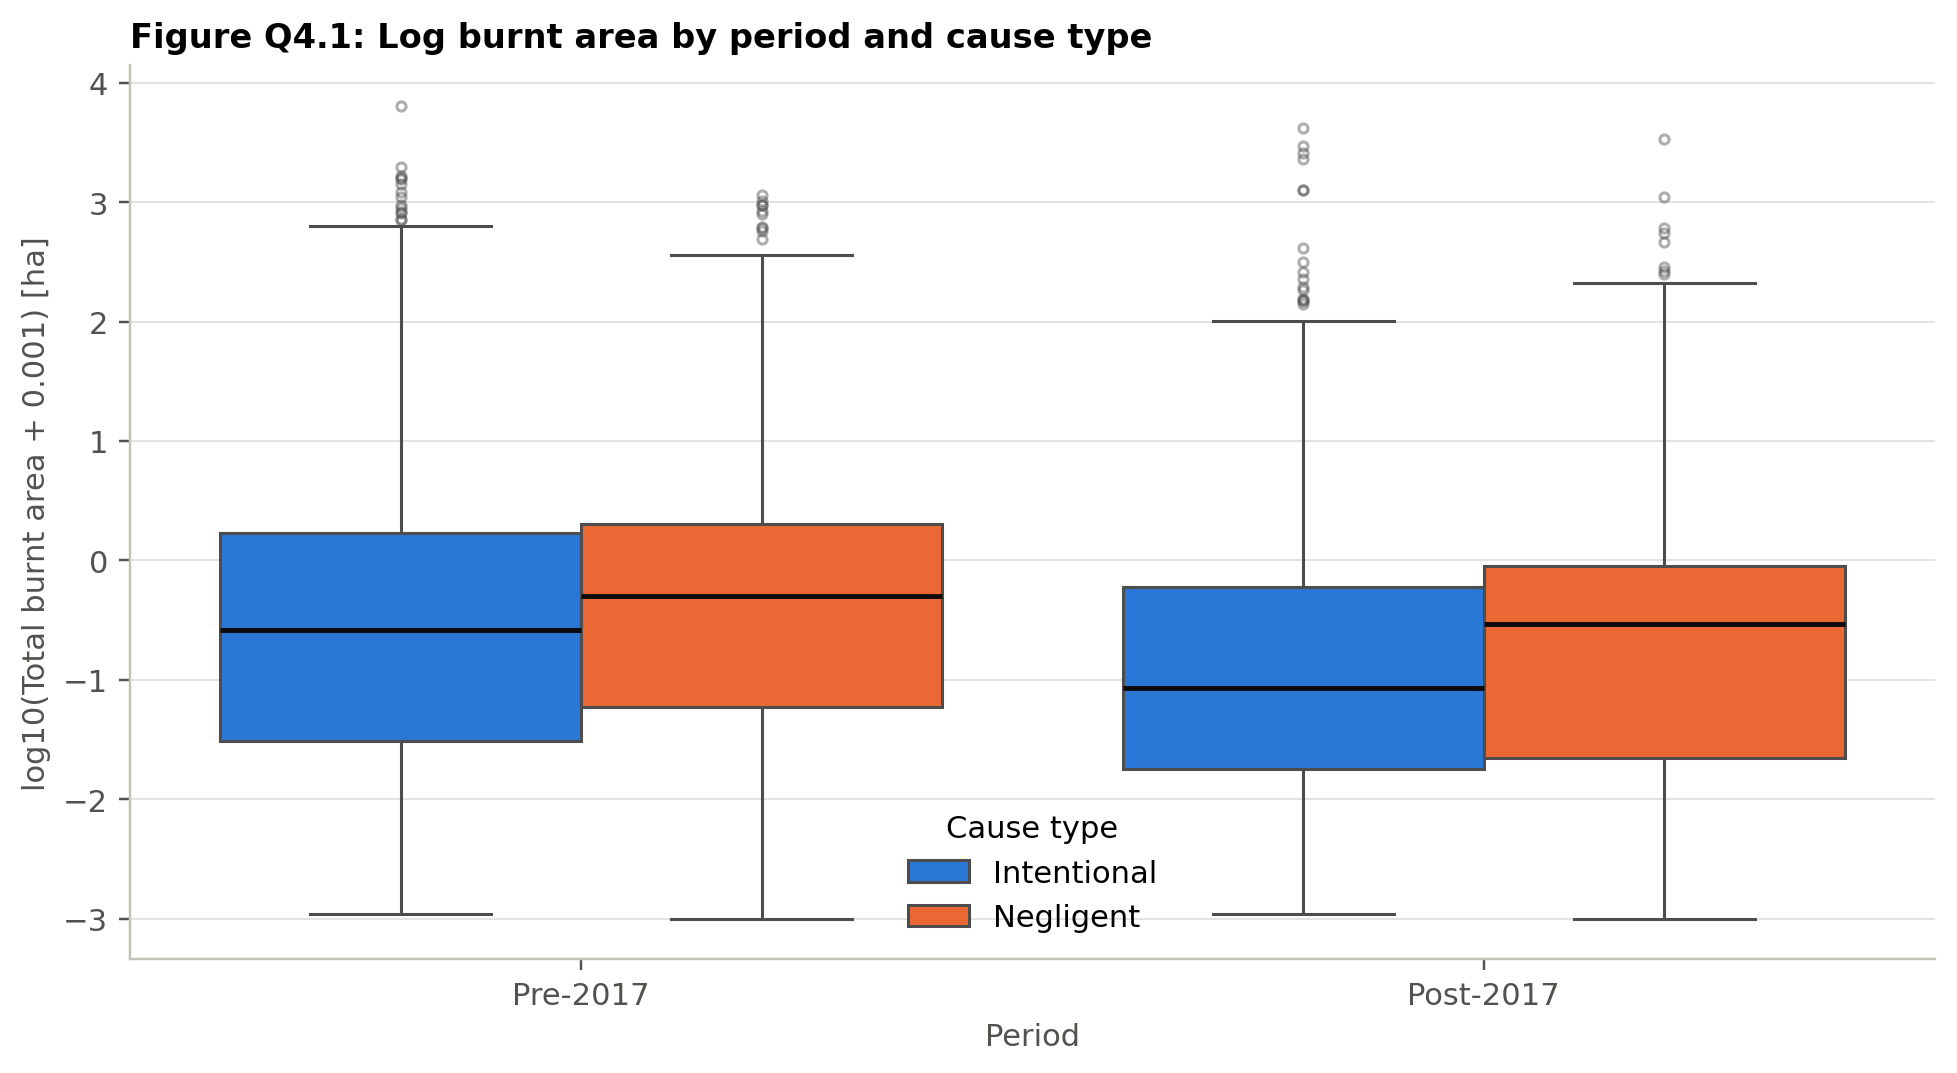

In [27]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=q4, x="Period", y="Log_Total_Burnt_Area", hue="Cause_Type",
            order=PERIOD_ORDER, hue_order=CAUSE_ORDER, palette=PAL_CAUSE, saturation=1,
            medianprops={"color": INK, "linewidth": 1.6},
            flierprops={"marker": "o", "markersize": 3, "alpha": .45}, ax=ax)
ax.set_title("Figure Q4.1: Log burnt area by period and cause type")
ax.set_ylabel("log10(Total burnt area + 0.001) [ha]")
ax.set_xlabel("Period")
ax.legend(title="Cause type")
plt.tight_layout()
plt.show()

In [28]:
# Numbers behind Figure Q4.1 (boxplot statistics on the log scale)
box_rows = []
for (cause, period), g in q4.groupby(["Cause_Type", "Period"], observed=True):
    x = g["Log_Total_Burnt_Area"]
    area = g["Total_Burnt_Area"]
    lo, med, hi = x.quantile([0.25, 0.5, 0.75])
    iqr = hi - lo
    box_rows.append({
        "Cause_Type": cause,
        "Period": period,
        "min": x.min(),
        "lower_whisker": x[x >= lo - 1.5 * iqr].min(),
        "Q1": lo,
        "median": med,
        "Q3": hi,
        "upper_whisker": x[x <= hi + 1.5 * iqr].max(),
        "max": x.max(),
        "n_outliers_upper": (x > hi + 1.5 * iqr).sum(),
        "n_outliers_lower": (x < lo - 1.5 * iqr).sum(),
        "n_0_ha": (area == 0).sum(),
        "n_0.01_ha": (area == 0.01).sum(),
    })
pd.DataFrame(box_rows).round(3)

,Cause_Type,Period,min,lower_whisker,Q1,median,Q3,upper_whisker,max,n_outliers_upper,n_outliers_lower,n_0_ha,n_0.01_ha
0,Intentional,Pre-2017,-2.959,-2.959,-1.509,-0.583,0.231,2.801,3.805,14,0,0,76
1,Intentional,Post-2017,-2.959,-2.959,-1.745,-1.066,-0.221,2.008,3.618,16,0,0,32
2,Negligent,Pre-2017,-3.000,-3.000,-1.223,-0.300,0.301,2.556,3.060,10,0,2,268
3,Negligent,Post-2017,-3.000,-3.000,-1.658,-0.536,-0.045,2.324,3.527,8,0,1,229


In [29]:
# Most frequent burnt area values (in ha)
q4["Total_Burnt_Area"].value_counts().head(6)

Total_Burnt_Area
0.01    605
0.50    442
1.00    375
2.00    227
0.10    193
1.50    166
Name: count, dtype: int64

Figure Q4.1 shows that the four distributions overlap heavily, as expected for a variable with high natural variability. Even so, the median of negligent fires is higher than that of intentional fires in both periods (-0.30 vs -0.58 before 2017 and -0.54 vs -1.07 after 2017), and all medians are lower after 2017. The lower whiskers reach about -3 because of very small fires (0.0001 ha or 0 ha). Areas are often recorded as rounded values, and 0.01 ha is the most frequent value (605 fires).

#### Interaction plot

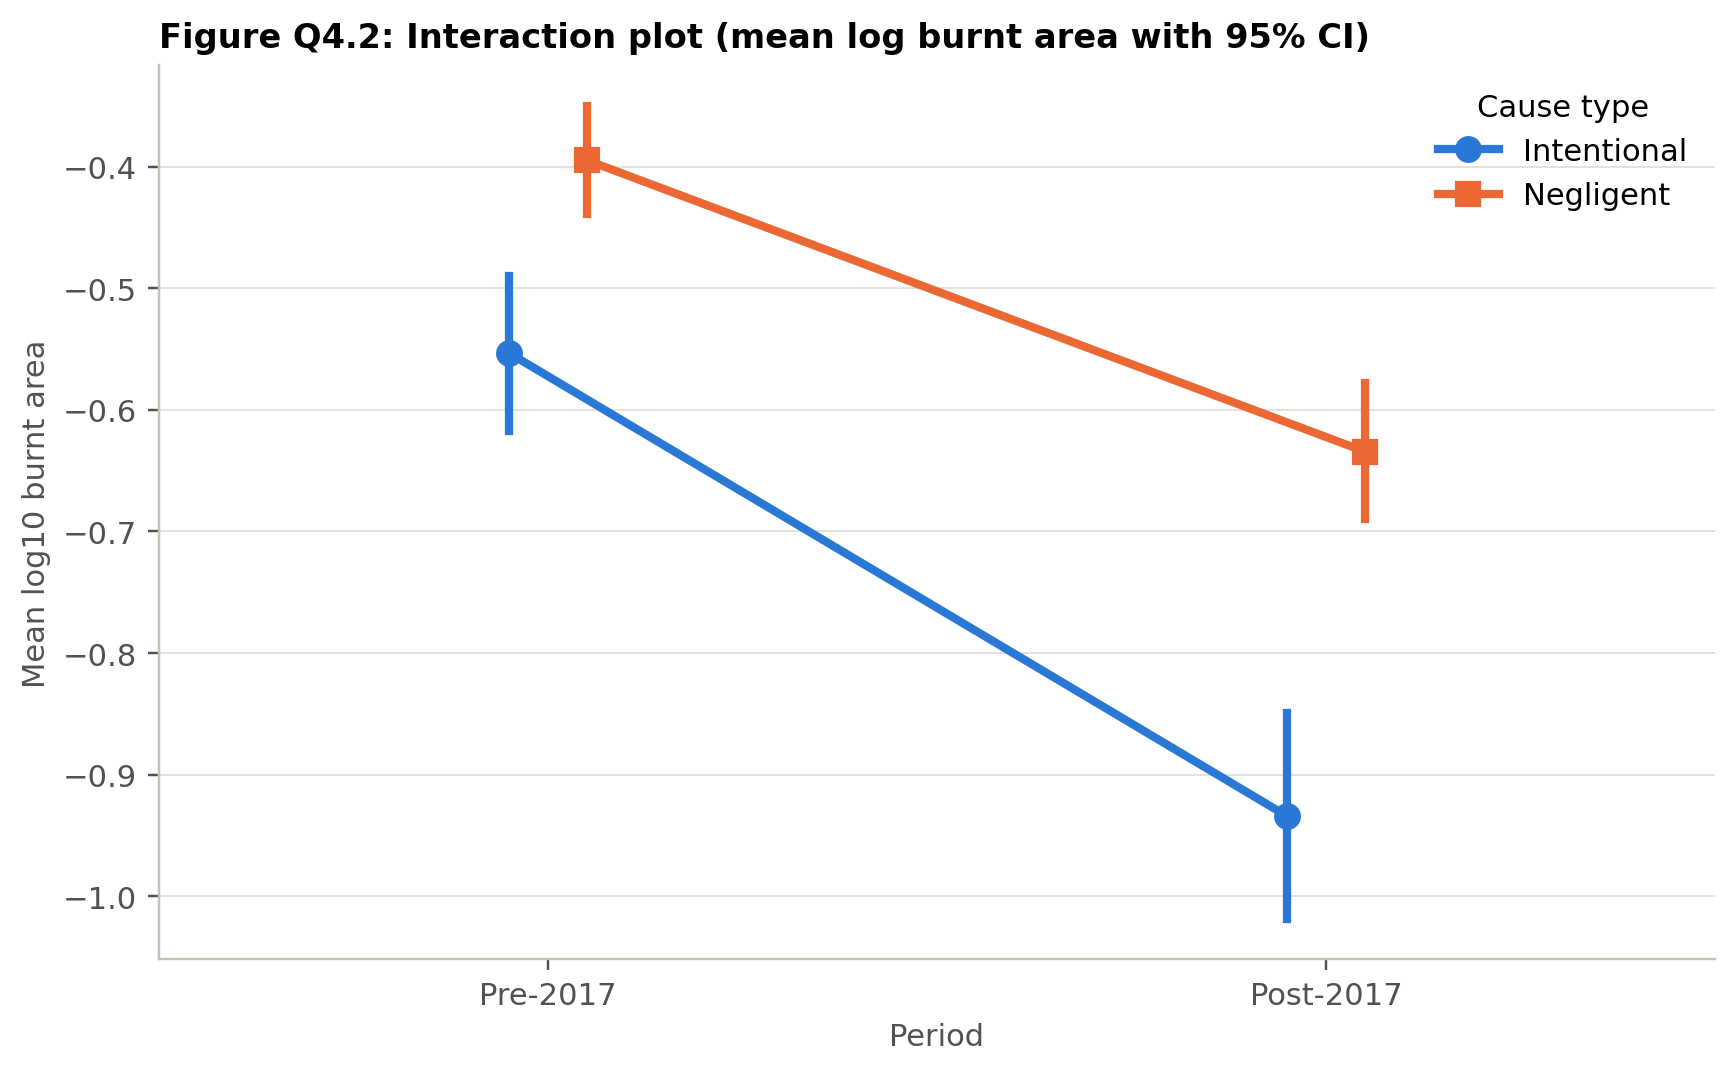

In [30]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.pointplot(data=q4, x="Period", y="Log_Total_Burnt_Area", hue="Cause_Type",
              order=PERIOD_ORDER, hue_order=CAUSE_ORDER, palette=PAL_CAUSE,
              errorbar=("ci", 95), dodge=0.1, markers=["o", "s"], ax=ax)
ax.set_title("Figure Q4.2: Interaction plot (mean log burnt area with 95% CI)")
ax.set_ylabel("Mean log10 burnt area")
ax.set_xlabel("Period")
ax.legend(title="Cause type")
plt.tight_layout()
plt.show()

In [31]:
# Numbers behind Figure Q4.2
q4_means = (
    q4.groupby(["Period", "Cause_Type"], observed=True)["Log_Total_Burnt_Area"]
      .agg(n="size", mean="mean", sd="std")
)
q4_means["se"] = q4_means["sd"] / np.sqrt(q4_means["n"])
t_crit_q4 = stats.t.ppf(0.975, q4_means["n"] - 1)
q4_means["ci_low"] = q4_means["mean"] - t_crit_q4 * q4_means["se"]
q4_means["ci_high"] = q4_means["mean"] + t_crit_q4 * q4_means["se"]
display(q4_means.round(3))

mean_tab = q4_means["mean"].unstack()
drop = mean_tab.loc["Pre-2017"] - mean_tab.loc["Post-2017"]
gap = mean_tab["Negligent"] - mean_tab["Intentional"]
print("Drop after 2017 (log units):")
print(drop.round(3))
print("\nGap Negligent - Intentional (log units):")
print(gap.round(3))
print(f"\nChange in the gap: {gap['Post-2017'] - gap['Pre-2017']:.3f}")

n   mean     sd     se  ci_low  ci_high
Period    Cause_Type                                             
Pre-2017  Intentional  1381 -0.553  1.228  0.033  -0.618   -0.488
          Negligent    2653 -0.395  1.109  0.022  -0.437   -0.352
Post-2017 Intentional   789 -0.934  1.195  0.043  -1.018   -0.851
          Negligent    1696 -0.634  1.170  0.028  -0.690   -0.579

Drop after 2017 (log units):
Cause_Type
Intentional    0.381
Negligent      0.240
dtype: float64

Gap Negligent - Intentional (log units):
Period
Pre-2017     0.159
Post-2017    0.300
dtype: float64

Change in the gap: 0.141


Figure Q4.2 is the most direct visual answer to the research question. If the gap between causes had narrowed after 2017, the two lines would converge. Instead, they move slightly apart. The mean for intentional fires drops by 0.38 log units (from -0.55 to -0.93), while the mean for negligent fires drops by 0.24 (from -0.39 to -0.63). As a result, the gap between causes goes from 0.16 to 0.30 log units, an increase of 0.14.

#### Summary

The descriptive analysis suggests that the gap between causes did not narrow after 2017. In both periods, the typical negligent fire burnt a larger area than the typical intentional fire, and all groups had smaller fires after 2017. Intentional fires decreased more, so the two lines in Figure Q4.2 move slightly apart. Whether these differences are statistically significant is tested in Section 4.4.

---

## 4) Draw Inferences

### 4.1 Q1: Z-test for Proportions

To determine if the change post-2017 was concentrated in the critical period (1 June to 30 September) or also affected the traditional months, we ran a two-proportion Z-test separately for the Critical and Non-Critical periods.

If the reduction in negligent causes was concentrated in the critical period, we would expect a significant drop in the Critical period and no significant change (or an increase) in the Non-Critical period.

#### Terminology

* **$p_1$**: The proportion of negligent fires in the Pre-2017 period.
* **$p_2$**: The proportion of negligent fires in the Post-2017 period.
* **$n_1$**: The total number of human-caused fires in the Pre-2017 period.
* **$n_2$**: The total number of human-caused fires in the Post-2017 period.
* **$\alpha$**: The significance level, set at 0.05.

#### Hypotheses

* **$H_0$**: $p_1 = p_2$ (the proportion of negligent fires is the same before and after 2017).
* **$H_1$**: $p_1 \neq p_2$ (the proportion of negligent fires changed after 2017).

#### Methodology

We use a two-proportion Z-test for each season separately:

* **Critical Period:** Pre-2017 ($n_1 = 2531$) vs. Post-2017 ($n_2 = 1215$).
* **Non-Critical Period:** Pre-2017 ($n_1 = 1503$) vs. Post-2017 ($n_2 = 1270$).

#### Checking the assumptions

1. **Independence:** The fires are independent observations.
2. **Large sample size:** The smallest cell count is 576 (Post-2017 Critical Negligent).

#### Z statistic and p-value

In [32]:
# Critical Period
z_crit, p_crit = smp.proportions_ztest([576, 1411], [1215, 2531])

# Non-Critical Period
z_non, p_non = smp.proportions_ztest([1120, 1242], [1270, 1503])

print(f"Critical Period: Z = {z_crit:.4f}, p-value = {p_crit:.4e}")
print(f"Non-Critical Period: Z = {z_non:.4f}, p-value = {p_non:.4e}")

Critical Period: Z = -4.7887, p-value = 1.6784e-06
Non-Critical Period: Z = 4.1013, p-value = 4.1085e-05


---

### 4.2 Q2: Welch's Two-Sample t-test

We aim to test whether the mean number of daily negligent ignitions differs significantly between weekends and weekdays in the post-2017 period.

#### Terminology

- **$\mu_{\text{Weekend}}$**: Population mean number of daily negligent ignitions on active weekend days in the post-2017 period ($n_1 = 337$).
- **$\mu_{\text{Weekday}}$**: Population mean number of daily negligent ignitions on active weekdays in the post-2017 period ($n_2 = 802$).
- **$\alpha$**: The significance level, set at 0.05.

#### Hypotheses

- **$H_0$**: $\mu_{\text{Weekend}} - \mu_{\text{Weekday}} = 0$ (there is no difference in the population mean daily negligent ignitions between weekends and weekdays).
- **$H_1$**: $\mu_{\text{Weekend}} - \mu_{\text{Weekday}} \neq 0$ (two-sided: the population mean daily negligent ignitions differ between weekends and weekdays).

#### Checking the assumptions

A two-sample $t$-test requires three conditions:

1. **Independence:** Each observation represents a distinct municipal active fire day (`Concelho` $\times$ `Date`). While synoptic weather conditions can induce spatial/temporal clustering (discussed in the limitations in Section 6), observations across weekdays and weekends are treated as independent samples.
2. **Normality:** Assessed below via histograms, normal Q-Q plots, skewness, excess kurtosis, and the Shapiro-Wilk test within each group. Because daily ignition counts are discrete and strongly right-skewed ($Y \ge 1$, skewness $\approx 4$, excess kurtosis $\approx 20$), normality of the raw observations is clearly rejected ($p < 0.001$ in both groups). However, given the large sample sizes ($n_{\text{Weekend}} = 337 \ge 30$ and $n_{\text{Weekday}} = 802 \ge 30$), the sampling distribution of the sample means is **approximately normal by the Central Limit Theorem (CLT)**, although the strong positive skewness may slow the rate of convergence.
3. **Homoscedasticity (equal variances):** Evaluated via the sample variance ratio and both mean-centred (Levene) and median-centred (Brown-Forsythe) tests. Notice that the two tests may disagree because mean-centred Levene is sensitive to the heavy right tail ($p < 0.05$), whereas median-centred Brown-Forsythe is more robust to skewness ($p > 0.05$). Regardless of whether equal variances hold, **Welch's two-sample $t$-test** (`equal_var=False`) is used as the primary parametric test because it adjusts the degrees of freedom (Welch-Satterthwaite) and remains valid in both cases.

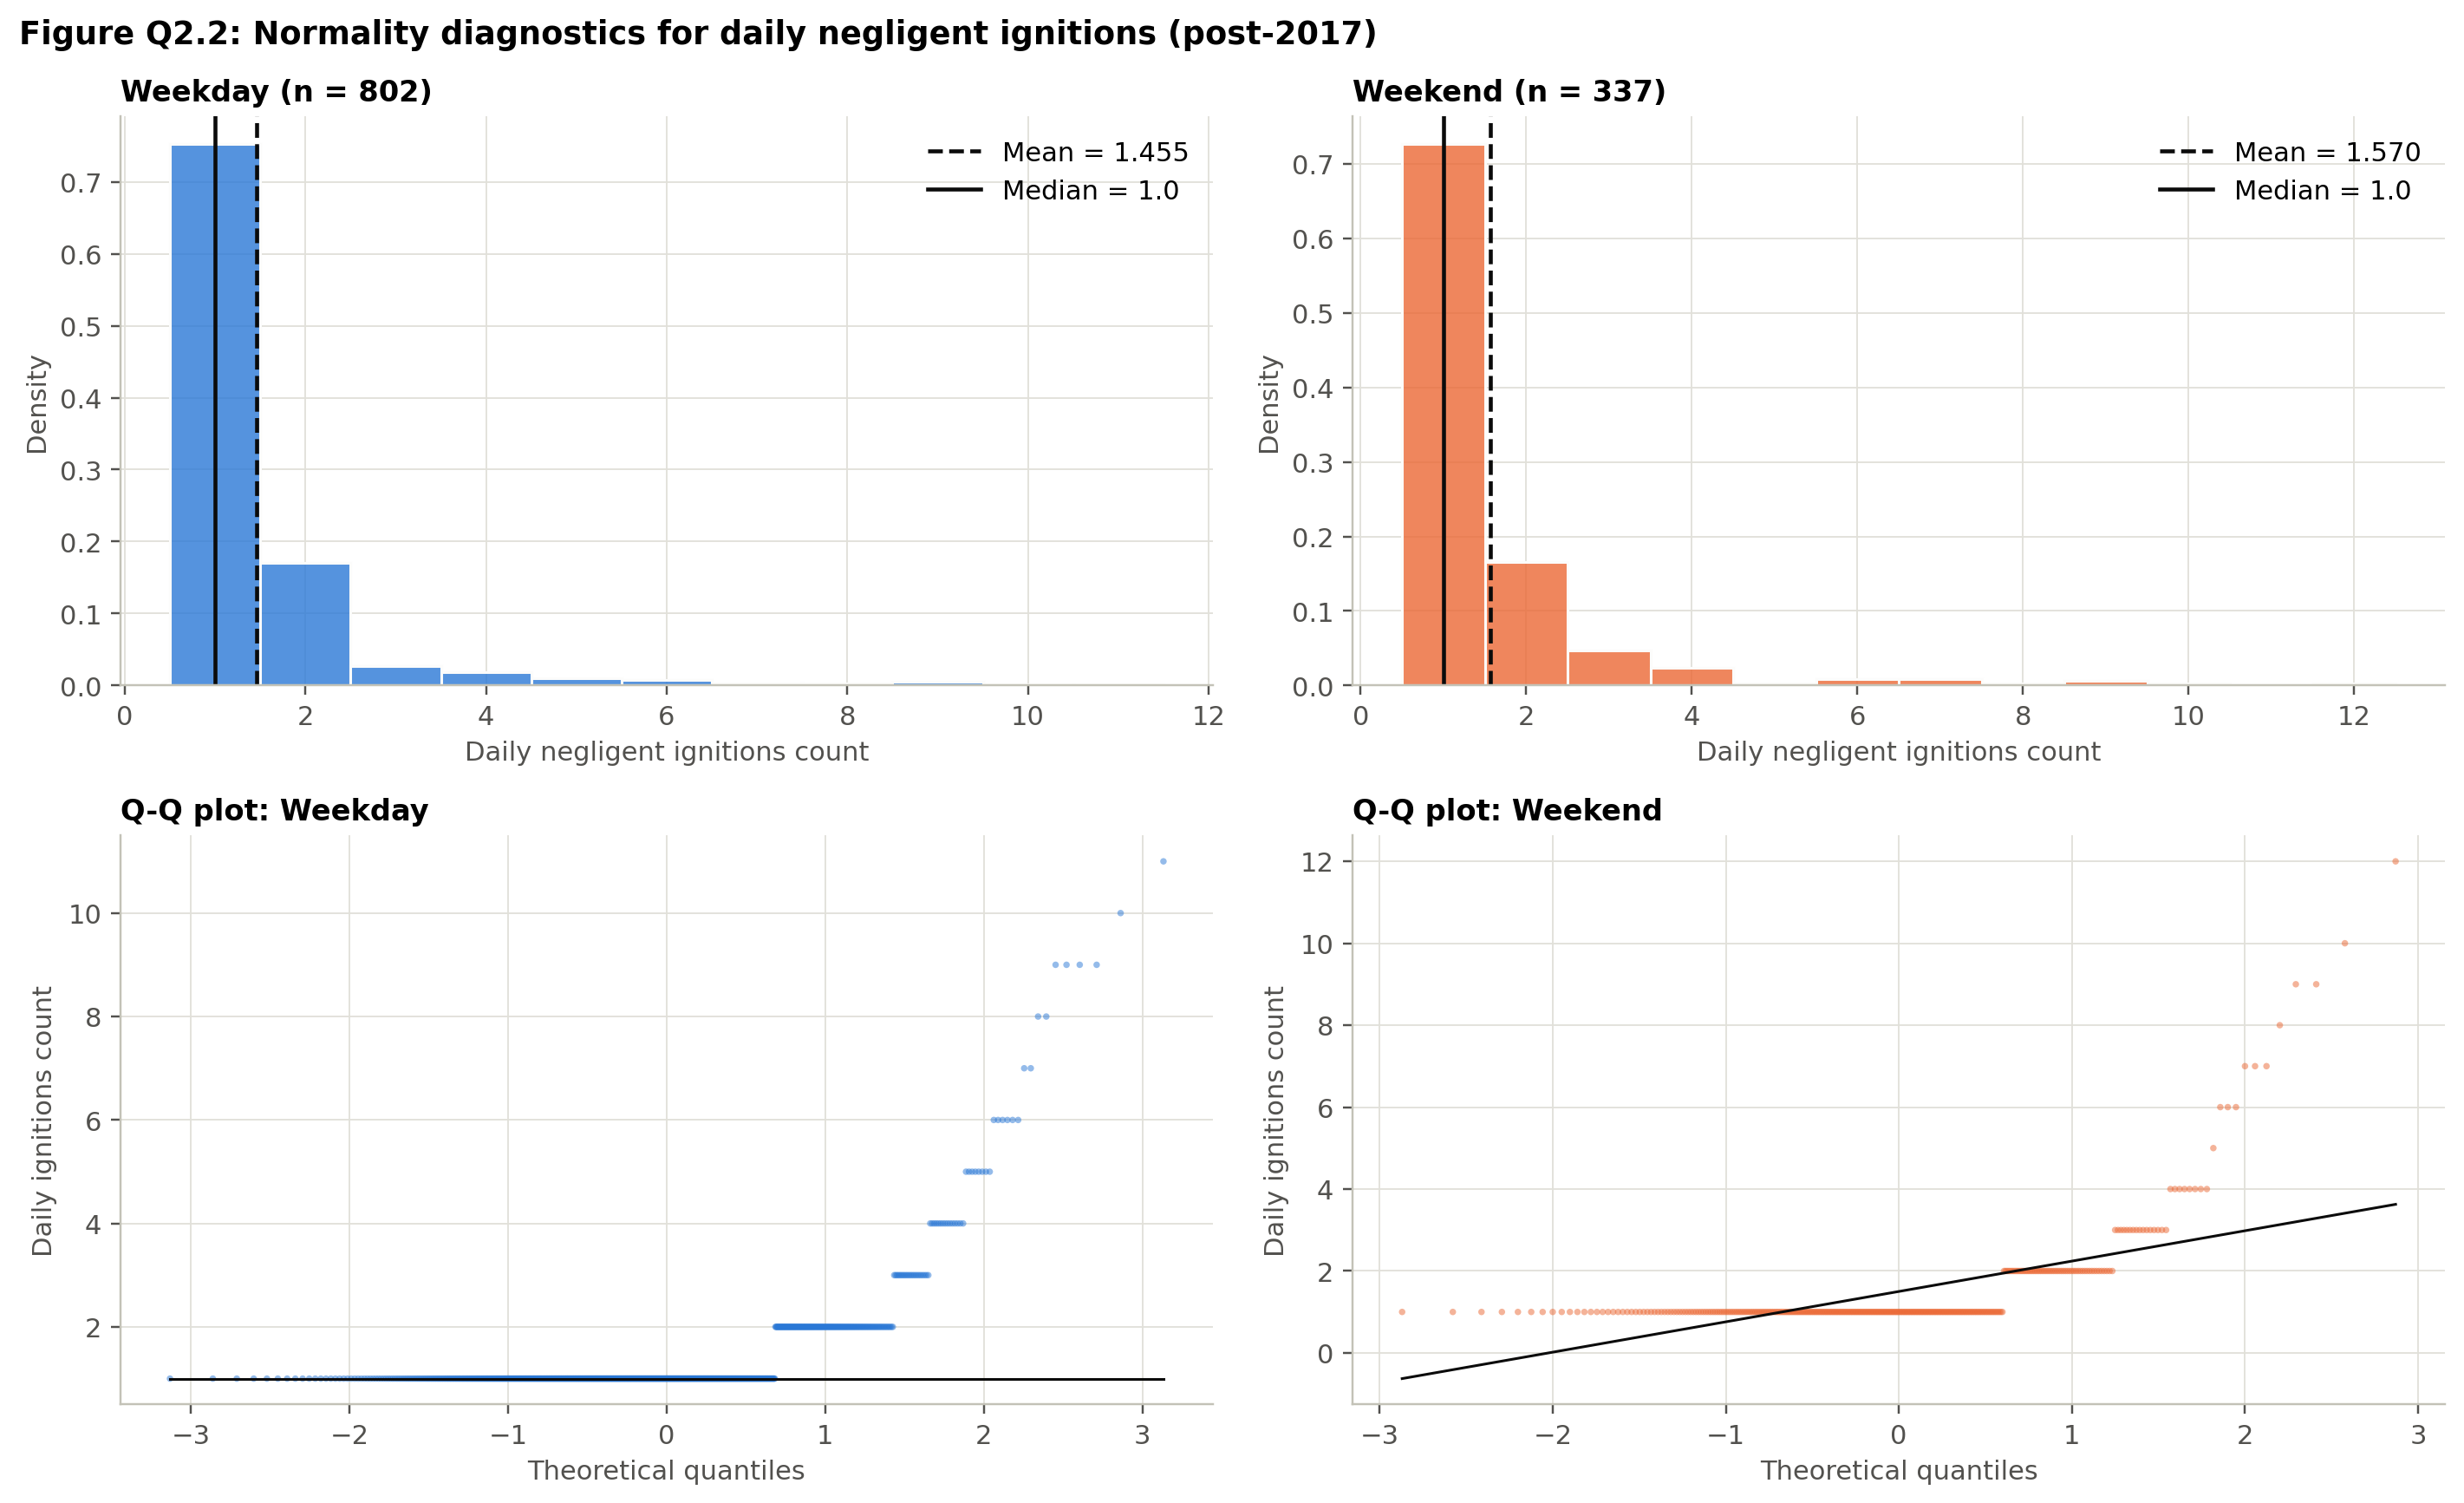

Normality and CLT diagnostics:


,Group (Post-2017),n,Mean,SD,Variance,Skewness,Excess_Kurtosis,Shapiro_W,Shapiro_p,CLT_Applies (n >= 30)
0,Weekday,802,1.4551,1.1606,1.3469,4.2565,22.3345,0.4379,< 0.001,True
1,Weekend,337,1.5697,1.4022,1.9661,4.0247,19.3698,0.4568,< 0.001,True



Homoscedasticity (equality of variances):
Variance ratio (max / min): 1.460 (SD ratio: 1.208)
Levene (centre = mean)           : W = 4.8690, p = 0.0275
Brown-Forsythe (centre = median) : W = 2.0377, p = 0.1537
Note: the two tests can disagree because of the strong right-skewness; Welch's t-test (equal_var=False) remains valid in both cases.


In [33]:
# Post-2017 subset
post_data = q2[q2["Period"] == "Post-2017"].copy()

weekday_post = post_data[post_data["Day_Type"] == "Weekday"]["Daily_Ignitions_Count"]
weekend_post = post_data[post_data["Day_Type"] == "Weekend"]["Daily_Ignitions_Count"]

# 1. Visual check of normality: histograms + Q-Q plots (post-2017)
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
groups_post = [("Weekday", weekday_post), ("Weekend", weekend_post)]

for i, (label, serie) in enumerate(groups_post):
    color = PAL_DAY[label]
    # histogram (top row)
    sns.histplot(serie, discrete=True, stat="density", color=color, alpha=0.8, edgecolor=SURFACE, ax=axes[0, i])
    axes[0, i].axvline(serie.mean(), color=INK, linestyle="--", linewidth=1.5, label=f"Mean = {serie.mean():.3f}")
    axes[0, i].axvline(serie.median(), color=INK, linestyle="-", linewidth=1.5, label=f"Median = {serie.median():.1f}")
    axes[0, i].set_title(f"{label} (n = {len(serie)})")
    axes[0, i].set_xlabel("Daily negligent ignitions count")
    axes[0, i].set_ylabel("Density")
    axes[0, i].legend()

    # normal Q-Q plot (bottom row)
    qq_panel(axes[1, i], serie, color, f"Q-Q plot: {label}", ylabel="Daily ignitions count")

fig_title(fig, "Figure Q2.2: Normality diagnostics for daily negligent ignitions (post-2017)")
plt.tight_layout()
plt.show()

# 2. Normality summary (skewness, kurtosis and Shapiro-Wilk)
norm_rows = []
for label, serie in groups_post:
    sw_stat, sw_p = stats.shapiro(serie)
    norm_rows.append({
        "Group (Post-2017)": label,
        "n": len(serie),
        "Mean": round(serie.mean(), 4),
        "SD": round(serie.std(ddof=1), 4),
        "Variance": round(serie.var(ddof=1), 4),
        "Skewness": round(stats.skew(serie), 4),
        "Excess_Kurtosis": round(stats.kurtosis(serie), 4),
        "Shapiro_W": round(sw_stat, 4),
        "Shapiro_p": "< 0.001" if sw_p < 0.001 else f"{sw_p:.4f}",
        "CLT_Applies (n >= 30)": len(serie) >= 30
    })

norm_df = pd.DataFrame(norm_rows)
print("Normality and CLT diagnostics:")
display(norm_df)

# 3. Equal variances: Levene (mean) vs Brown-Forsythe (median)
levene_stat, levene_p = stats.levene(weekday_post, weekend_post, center="mean")
bf_stat, bf_p = stats.levene(weekday_post, weekend_post, center="median")
var_ratio = max(weekend_post.var(ddof=1), weekday_post.var(ddof=1)) / min(weekend_post.var(ddof=1), weekday_post.var(ddof=1))

print("\nHomoscedasticity (equality of variances):")
print(f"Variance ratio (max / min): {var_ratio:.3f} (SD ratio: {np.sqrt(var_ratio):.3f})")
print(f"Levene (centre = mean)           : W = {levene_stat:.4f}, p = {levene_p:.4f}")
print(f"Brown-Forsythe (centre = median) : W = {bf_stat:.4f}, p = {bf_p:.4f}")
print("Note: the two tests can disagree because of the strong right-skewness; Welch's t-test (equal_var=False) remains valid in both cases.")

#### Welch's t-test

In [34]:
# Welch's t-test (equal_var=False)
t_stat, p_val = stats.ttest_ind(weekend_post, weekday_post, equal_var=False)

# Welch-Satterthwaite degrees of freedom
s1, s2 = np.var(weekend_post, ddof=1), np.var(weekday_post, ddof=1)
n1, n2 = len(weekend_post), len(weekday_post)
df_welch = ((s1 / n1 + s2 / n2) ** 2) / (
    ((s1 / n1) ** 2) / (n1 - 1) + ((s2 / n2) ** 2) / (n2 - 1)
)

# Critical value (two-sided, alpha = 0.05) and 95% confidence interval
alpha = 0.05
t_crit = stats.t.ppf(1 - alpha / 2, df=df_welch)
diff_mean = weekend_post.mean() - weekday_post.mean()
se_diff = np.sqrt(s1 / n1 + s2 / n2)
ci_low, ci_high = stats.t.interval(
    1 - alpha, df=df_welch, loc=diff_mean, scale=se_diff
)

print("Welch's two-sample t-test (post-2017):")
print(f"Mean Weekend: {weekend_post.mean():.3f} (SD = {weekend_post.std(ddof=1):.3f}, n = {n1})")
print(f"Mean Weekday: {weekday_post.mean():.3f} (SD = {weekday_post.std(ddof=1):.3f}, n = {n2})")
print(f"Difference in means (Weekend - Weekday): {diff_mean:.3f} (SE = {se_diff:.4f})")
print(f"Welch t-statistic (t_obs): {t_stat:.4f}")
print(f"Degrees of freedom (df): {df_welch:.2f}")
print(f"Critical value (t_crit, alpha = 0.05 two-sided): ±{t_crit:.4f}")
print(f"p-value: {p_val:.4f}")
print(f"95% confidence interval for the difference: [{ci_low:.3f}, {ci_high:.3f}]")
decision = "Reject H0" if p_val < alpha else "Fail to reject H0"
print(f"Decision: {decision} (|t_obs| = {abs(t_stat):.4f}, t_crit = {t_crit:.4f}, p = {p_val:.4f}, alpha = {alpha})")

Welch's two-sample t-test (post-2017):
Mean Weekend: 1.570 (SD = 1.402, n = 337)
Mean Weekday: 1.455 (SD = 1.161, n = 802)
Difference in means (Weekend - Weekday): 0.115 (SE = 0.0867)
Welch t-statistic (t_obs): 1.3223
Degrees of freedom (df): 538.57
Critical value (t_crit, alpha = 0.05 two-sided): ±1.9644
p-value: 0.1866
95% confidence interval for the difference: [-0.056, 0.285]
Decision: Fail to reject H0 (|t_obs| = 1.3223, t_crit = 1.9644, p = 0.1866, alpha = 0.05)


#### Robustness check: controlling for municipality

As shown in the table below, the four municipalities differ substantially in daily negligent ignition counts, with the weekend mean ranging from about $1.05$ ignitions/day in `Tomar` to $1.99$ ignitions/day in `Montalegre` (and the weekday mean ranging from $1.08$ in `Ourém` to $1.82$ in `Montalegre`). To verify that pooling the observations across `Chaves`, `Montalegre`, `Ourém` and `Tomar` does not mask a municipality-specific weekend effect (Simpson's paradox), we repeat Welch's two-sample $t$-test separately within each municipality and plot the 95% confidence intervals for the difference in means ($\mu_{\text{Weekend}} - \mu_{\text{Weekday}}$). Applying a Bonferroni correction across the $K = 4$ municipal tests ($\alpha_{\text{Bonf}} = 0.05 / 4 = 0.0125$) does not change the conclusion, as $p > 0.05$ in every municipality.

Welch's t-test by municipality (Bonferroni alpha = 0.05/4 = 0.0125):


,Municipality,n_Weekend,n_Weekday,Mean_Weekend,Mean_Weekday,Diff (Wknd - Wkdy),SE,t_stat,df,p_value,CI_95_low,CI_95_high,Alpha_Threshold,Significant
0,Chaves,84,181,1.3690,1.2376,0.1315,0.0808,1.6263,131.5094,0.1063,-0.0285,0.2914,0.0125,False
1,Montalegre,153,363,1.9935,1.8237,0.1698,0.1763,0.9629,243.8556,0.3365,-0.1775,0.5170,0.0125,False
2,Ourém,44,131,1.1364,1.0840,0.0524,0.0587,0.8923,66.6711,0.3754,-0.0648,0.1696,0.0125,False
3,Tomar,56,127,1.0536,1.0945,-0.0409,0.0487,-0.8396,112.7996,0.4029,-0.1375,0.0556,0.0125,False
4,All (pooled),337,802,1.5697,1.4551,0.1146,0.0867,1.3223,538.5686,0.1866,-0.0557,0.2849,0.0500,False


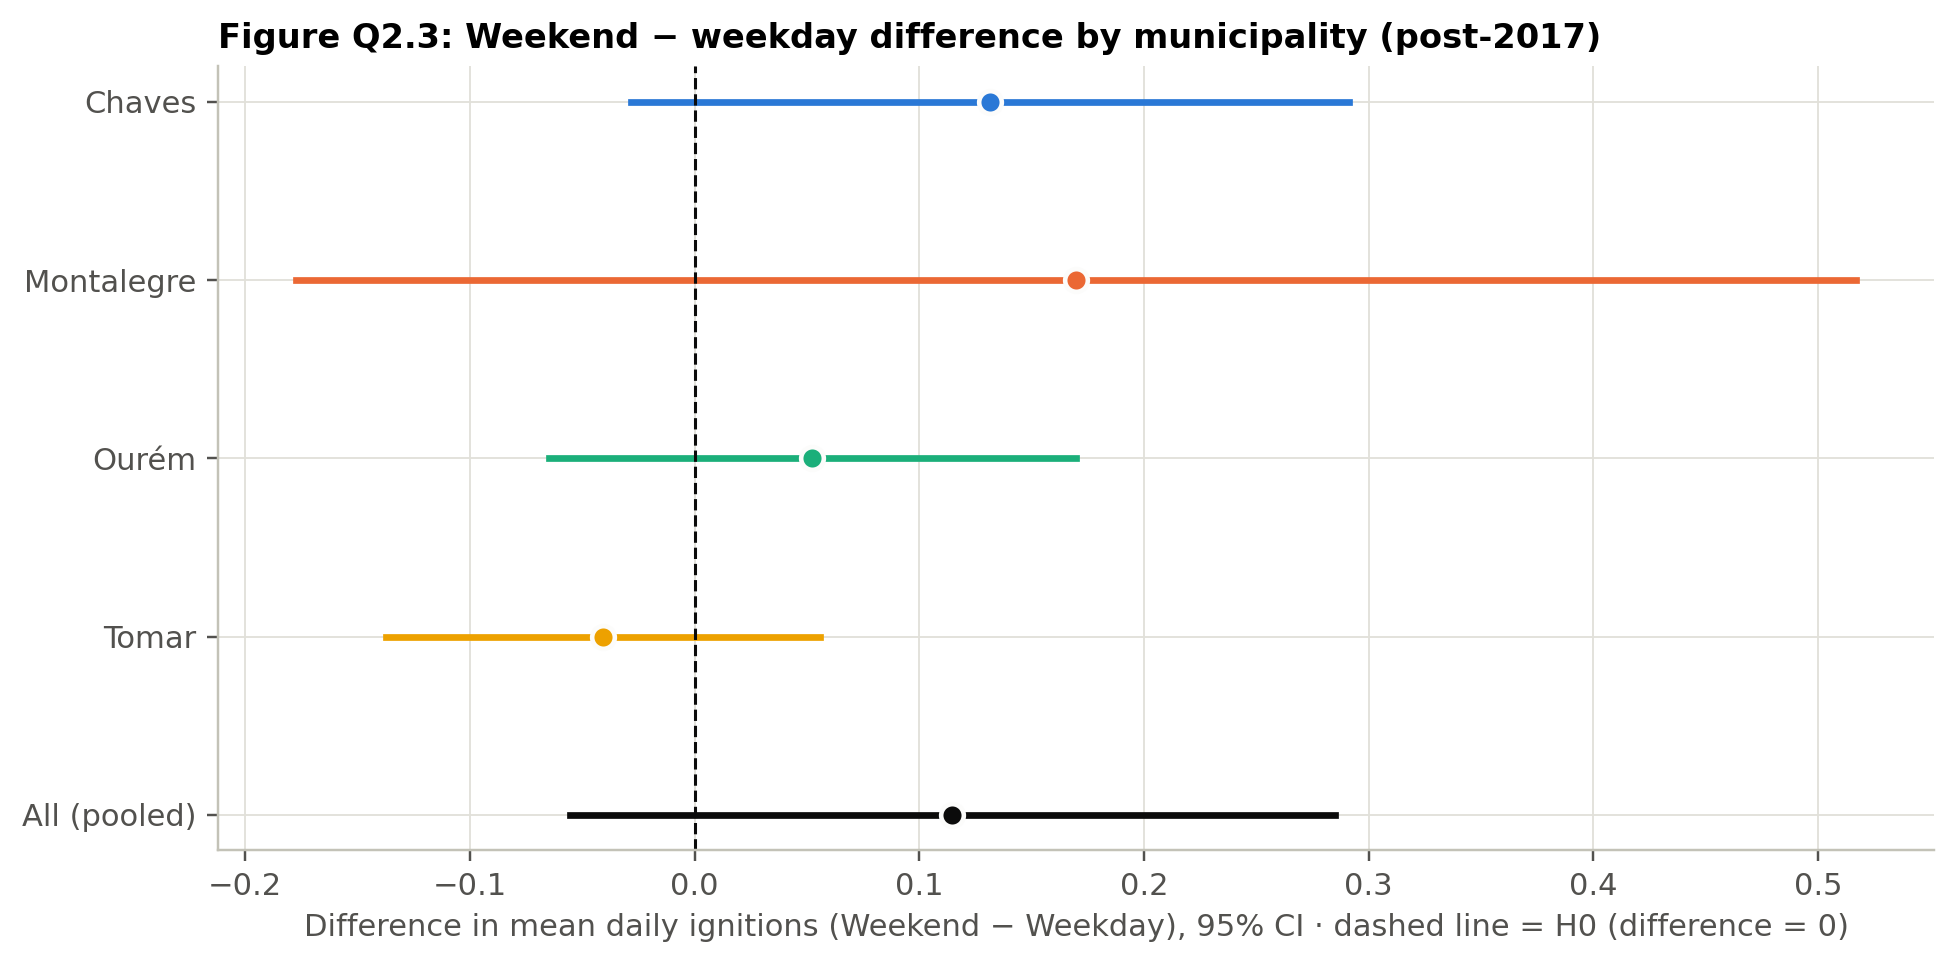

In [35]:
# Welch's t-test by municipality in the post-2017 period
alpha_bonf_mun = 0.05 / 4  # Bonferroni correction for 4 municipalities (0.0125)
mun_rows = []
for mun in MUNICIPALITIES:
    sub_m = post_data[post_data["Concelho"] == mun]
    wknd_m = sub_m[sub_m["Day_Type"] == "Weekend"]["Daily_Ignitions_Count"]
    wkdy_m = sub_m[sub_m["Day_Type"] == "Weekday"]["Daily_Ignitions_Count"]
    if len(wknd_m) >= 2 and len(wkdy_m) >= 2:
        t_m, p_m = stats.ttest_ind(wknd_m, wkdy_m, equal_var=False)
        v1_m, v2_m = wknd_m.var(ddof=1), wkdy_m.var(ddof=1)
        n1_m, n2_m = len(wknd_m), len(wkdy_m)
        se_m = np.sqrt(v1_m / n1_m + v2_m / n2_m)
        df_m = ((v1_m / n1_m + v2_m / n2_m) ** 2) / (((v1_m / n1_m) ** 2) / (n1_m - 1) + ((v2_m / n2_m) ** 2) / (n2_m - 1))
        diff_m = wknd_m.mean() - wkdy_m.mean()
        ci_l, ci_h = stats.t.interval(0.95, df=df_m, loc=diff_m, scale=se_m)
        mun_rows.append({
            "Municipality": mun,
            "n_Weekend": n1_m,
            "n_Weekday": n2_m,
            "Mean_Weekend": wknd_m.mean(),
            "Mean_Weekday": wkdy_m.mean(),
            "Diff (Wknd - Wkdy)": diff_m,
            "SE": se_m,
            "t_stat": t_m,
            "df": df_m,
            "p_value": p_m,
            "CI_95_low": ci_l,
            "CI_95_high": ci_h,
            "Alpha_Threshold": alpha_bonf_mun,
            "Significant": p_m < alpha_bonf_mun
        })

# Pooled row (all municipalities, post-2017) for visual comparison
mun_rows.append({
    "Municipality": "All (pooled)",
    "n_Weekend": n1,
    "n_Weekday": n2,
    "Mean_Weekend": weekend_post.mean(),
    "Mean_Weekday": weekday_post.mean(),
    "Diff (Wknd - Wkdy)": diff_mean,
    "SE": se_diff,
    "t_stat": t_stat,
    "df": df_welch,
    "p_value": p_val,
    "CI_95_low": ci_low,
    "CI_95_high": ci_high,
    "Alpha_Threshold": 0.05,
    "Significant": p_val < 0.05
})

mun_df = pd.DataFrame(mun_rows)
print(f"Welch's t-test by municipality (Bonferroni alpha = 0.05/4 = {alpha_bonf_mun:.4f}):")
display(mun_df.round(4))

# Forest plot of the 95% confidence intervals for (mu_Weekend - mu_Weekday)
fig, ax = plt.subplots(figsize=(9, 4.5))
y_pos = np.arange(len(mun_df))

for idx, row in mun_df.iterrows():
    col = INK if row["Municipality"] == "All (pooled)" else PAL_MUN[row["Municipality"]]
    ax.plot([row["CI_95_low"], row["CI_95_high"]], [idx, idx], color=col, linewidth=2.2)
    ax.scatter(row["Diff (Wknd - Wkdy)"], idx, s=55, color=col, zorder=3, edgecolor=SURFACE, linewidth=1.5)

ax.axvline(0, color=INK, linestyle="--", linewidth=1)
ax.set_yticks(y_pos)
ax.set_yticklabels(mun_df["Municipality"])
ax.invert_yaxis()
ax.set_xlabel("Difference in mean daily ignitions (Weekend − Weekday), 95% CI · dashed line = H0 (difference = 0)")
ax.set_title("Figure Q2.3: Weekend − weekday difference by municipality (post-2017)")
plt.tight_layout()
plt.show()

#### Complementary comparison: weekends before and after 2017

In [36]:
# Did the weekend mean change from pre-2017 to post-2017?
weekend_pre = q2[
    (q2["Period"] == "Pre-2017") & (q2["Day_Type"] == "Weekend")
]["Daily_Ignitions_Count"]

t_stat_evol, p_val_evol = stats.ttest_ind(
    weekend_pre, weekend_post, equal_var=False
)
print("Welch's t-test: weekends pre-2017 vs post-2017")
print(
    f"Mean Weekend Pre-2017: {weekend_pre.mean():.3f} vs Post-2017: {weekend_post.mean():.3f}"
)
print(f"t-statistic: {t_stat_evol:.4f}, p-value: {p_val_evol:.4f}")

Welch's t-test: weekends pre-2017 vs post-2017
Mean Weekend Pre-2017: 1.519 vs Post-2017: 1.570
t-statistic: -0.5662, p-value: 0.5715


---

### 4.3 Q3: One-way ANOVA

A one-way ANOVA was chosen because the response variable, ln(`Total_Burnt_Area`), is quantitative and there is one qualitative factor, the municipality, with four levels.

#### Hypotheses

(on the log scale, significance level α = 0.05)

- **H₀**: the population means of ln(burnt area) are equal in the four municipalities.
- **H₁**: at least one population mean of ln(burnt area) differs.

#### Checking the assumptions

The classical one-way ANOVA model is yᵢⱼ = μᵢ + εᵢⱼ, where the errors εᵢⱼ are assumed to be **(1) independent**, **(2) normal** and **(3) of equal variance** in all groups. A **residual** is what is left after removing the group mean (eᵢⱼ = yᵢⱼ − ȳᵢ), so assumptions 2 and 3 are checked on residuals. Here we check them on the **original scale (hectares)**; the same checks are repeated on the log scale under *Transformation and method selection*.

##### Independence

Independence means that knowing the burnt area of one fire tells us nothing about another. It is a property of how the data were generated and **cannot be proved by a statistical test**. We only look for *indications of possible clustering*; these are not proof of dependence (several fires on the same day in the same municipality may be unrelated events, and a fire near an earlier one may or may not be its continuation).

In [37]:
d_ = q3.assign(Date_only=q3["DataHoraAlerta"].dt.date)
per_day = d_.groupby(["Concelho", "Date_only"], observed=True)["Codigo_SGIF"].transform("size")
print(f"(a) Fires on a day with >= 2 fires in the same municipality: {(per_day >= 2).sum()} ({100 * (per_day >= 2).mean():.1f} %)")
print(f"(b) Reignition records: {len(rk)} ({100 * len(rk) / len(q3):.1f} %); {linked} of them follow another fire in the same parish within 3 days (heuristic)")

ly = q3_ln["ln_area"]; ss_total = ((ly - ly.mean()) ** 2).sum()
eta_year = sum(len(x) * (x.mean() - ly.mean()) ** 2 for _, x in ly.groupby(q3_ln["Ano"])) / ss_total
eta_mun = sum(len(x) * (x.mean() - ly.mean()) ** 2 for _, x in ly.groupby(q3_ln["Concelho"], observed=True)) / ss_total
print(f"(c) Share of the variance of ln(area) associated with year: {eta_year:.3f}; with municipality: {eta_mun:.3f}")

(a) Fires on a day with >= 2 fires in the same municipality: 1513 (55.2 %)
(b) Reignition records: 130 (4.7 %); 90 of them follow another fire in the same parish within 3 days (heuristic)
(c) Share of the variance of ln(area) associated with year: 0.019; with municipality: 0.134


##### Normality of the residuals

A **Q-Q plot** shows each residual against the value it would have if the data were perfectly normal: points on the line mean normality, bent tails mean skewness or heavy tails. **Skewness** (0 = symmetric) and **excess kurtosis** (0 = normal tails) summarise the shape. The **Shapiro-Wilk test** (H₀: normal) is a complement only: in large samples it rejects even harmless departures, so the plots and the size of the departure matter more than the p-value.

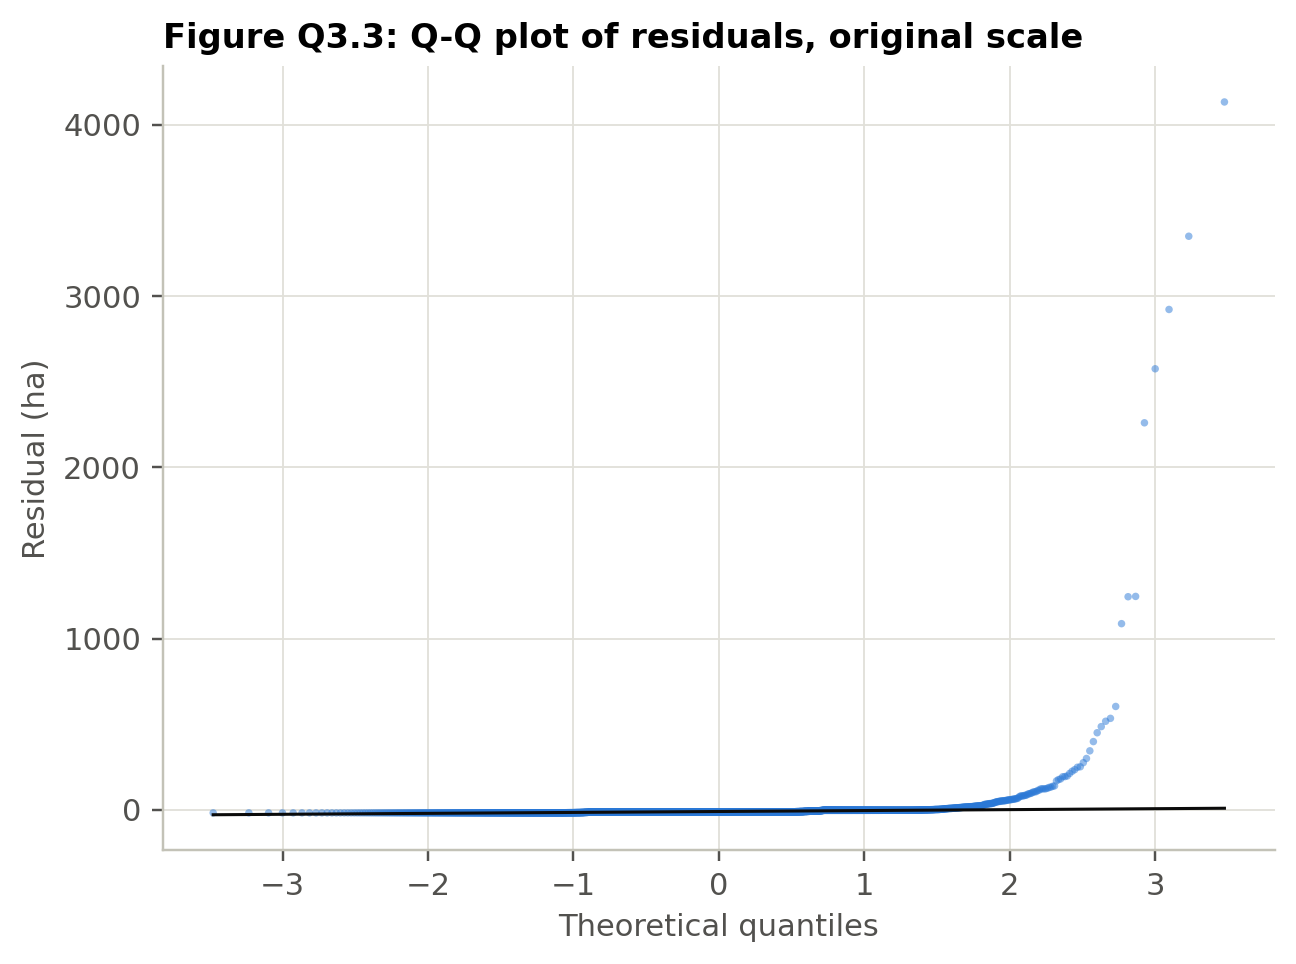

                    n  skewness  excess kurtosis  Shapiro W  Shapiro p
Chaves            555     14.58            227.2    0.06717  1.624e-45
Montalegre       1146     28.66            894.1    0.06045  2.247e-59
Ourém             620     15.42              252     0.0601   1.42e-47
Tomar             418     14.38            221.3    0.06178  7.085e-41
Pooled residuals 2739     20.98              493    0.06671  7.273e-79


In [38]:
resid_raw = np.concatenate([q3_groups[m] - q3_groups[m].mean() for m in MUNICIPALITIES])
fig, ax = plt.subplots(figsize=(6, 4.5))
qq_panel(ax, resid_raw, BLUE, "Figure Q3.3: Q-Q plot of residuals, original scale", ylabel="Residual (ha)")
plt.tight_layout(); plt.show()

rows = {}
for m in MUNICIPALITIES:
    a = q3_groups[m]; sw = stats.shapiro(a)
    rows[m] = {"n": len(a), "skewness": stats.skew(a), "excess kurtosis": stats.kurtosis(a), "Shapiro W": sw.statistic, "Shapiro p": sw.pvalue}
sw_all = stats.shapiro(resid_raw)
rows["Pooled residuals"] = {"n": len(resid_raw), "skewness": stats.skew(resid_raw), "excess kurtosis": stats.kurtosis(resid_raw),
                            "Shapiro W": sw_all.statistic, "Shapiro p": sw_all.pvalue}
print(pd.DataFrame(rows).T.to_string(float_format=lambda v: f"{v:.4g}"))

##### Homogeneity of variances

**Levene's test** (H₀: equal variances) compares how far observations are from their group centre; **Brown-Forsythe** is the version centred on the median, more robust to skewness. A non-significant result would not prove equal variances, and with thousands of observations a significant one can flag small differences, so the **ratio of variances** is also reported.

In [39]:
var_tab = pd.DataFrame({"n": {m: len(q3_groups[m]) for m in MUNICIPALITIES}, "variance": {m: q3_groups[m].var(ddof=1) for m in MUNICIPALITIES},
                        "sd": {m: q3_groups[m].std(ddof=1) for m in MUNICIPALITIES}})
print(var_tab.round(1).to_string())
print(f"Variance ratio (max/min): {var_tab['variance'].max() / var_tab['variance'].min():.1f}")
lev_mean = stats.levene(*q3_groups.values(), center="mean"); lev_med = stats.levene(*q3_groups.values(), center="median")
print(f"Levene (centre = mean)           : W = {lev_mean.statistic:.3f}, p = {lev_mean.pvalue:.4g}")
print(f"Brown-Forsythe (centre = median) : W = {lev_med.statistic:.3f}, p = {lev_med.pvalue:.4g}")

               n  variance     sd
Chaves       555   36814.4  191.9
Montalegre  1146   16911.9  130.0
Ourém        620   25371.7  159.3
Tomar        418    1259.2   35.5
Variance ratio (max/min): 29.2
Levene (centre = mean)           : W = 3.177, p = 0.02315
Brown-Forsythe (centre = median) : W = 0.906, p = 0.4372


##### Summary of the assumptions on the original scale

| Assumption | Evidence | Verdict |
|---|---|---|
| **Independence** | Cannot be verified from observational records. Indications of *possible* clustering: 55 % of fires occur on days with ≥ 2 fires in the same municipality; 90 of the 130 reignition records follow another fire in the same parish within 3 days; year is associated with 2 % of the variance of ln(area). None of this proves dependence. | Not verifiable; reported as a limitation |
| **Normality** | Q-Q plot bends sharply (Figure Q3.3); skewness 21.0 and excess kurtosis 493 (pooled residuals); Shapiro-Wilk p < 10⁻⁴⁰ in every group | **Clearly violated** |
| **Equal variances** | Variance ratio 29.2 (SD ratio 5.4); Levene (mean) p = 0.023; Brown-Forsythe p = 0.437 | **Not supported** (the two tests disagree because they emphasise different parts of the distribution) |

On the original scale the classical ANOVA is therefore not appropriate. The next block examines whether a transformation solves the problem.

#### Transformation and method selection

The problem is a very long right tail. A common remedy for positive, right-skewed data is the logarithm, which turns multiplicative differences into additive ones and compresses the huge fires. Because the ANOVA would then be computed on a **new scale**, its conclusions refer to ln(area), i.e. to geometric means and ratios (Section 3.3).

We compare three response scales using the diagnostics above: the original area, `log(1 + area)` and the natural logarithm `ln(area)` (the latter excludes the single 0 ha fire). Note that `log(1 + x)` is almost equal to `x` for areas below 1 ha, which are 78 % of the fires, so it is expected to remove the skewness only partly.

In [40]:
def diagnostics(g, label):
    resid = np.concatenate([g[m] - g[m].mean() for m in MUNICIPALITIES]); var = np.array([g[m].var(ddof=1) for m in MUNICIPALITIES])
    return pd.Series({"n": sum(len(g[m]) for m in MUNICIPALITIES), "residual skewness": stats.skew(resid), "residual excess kurtosis": stats.kurtosis(resid),
                      "min Shapiro W (groups)": min(stats.shapiro(g[m]).statistic for m in MUNICIPALITIES),
                      "variance ratio (max/min)": var.max() / var.min(),
                      "Levene p (mean)": stats.levene(*g.values(), center="mean").pvalue,
                      "Brown-Forsythe p": stats.levene(*g.values(), center="median").pvalue}, name=label)

q3_log1p_groups = {m: np.log1p(q3_groups[m]) for m in MUNICIPALITIES}
diag = pd.DataFrame([diagnostics(q3_groups, "original (ha)"), diagnostics(q3_log1p_groups, "log(1 + area)"), diagnostics(q3_ln_groups, "ln(area)")]).T
print(diag.to_string(float_format=lambda v: f"{v:.4g}"))

                          original (ha)  log(1 + area)  ln(area)
n                                  2739           2739      2738
residual skewness                 20.98          2.774    0.1287
residual excess kurtosis            493          9.991    0.2666
min Shapiro W (groups)           0.0601         0.3343     0.962
variance ratio (max/min)          29.24          4.443     1.316
Levene p (mean)                 0.02315      3.543e-73 0.0001075
Brown-Forsythe p                 0.4372       6.77e-44 0.0002396


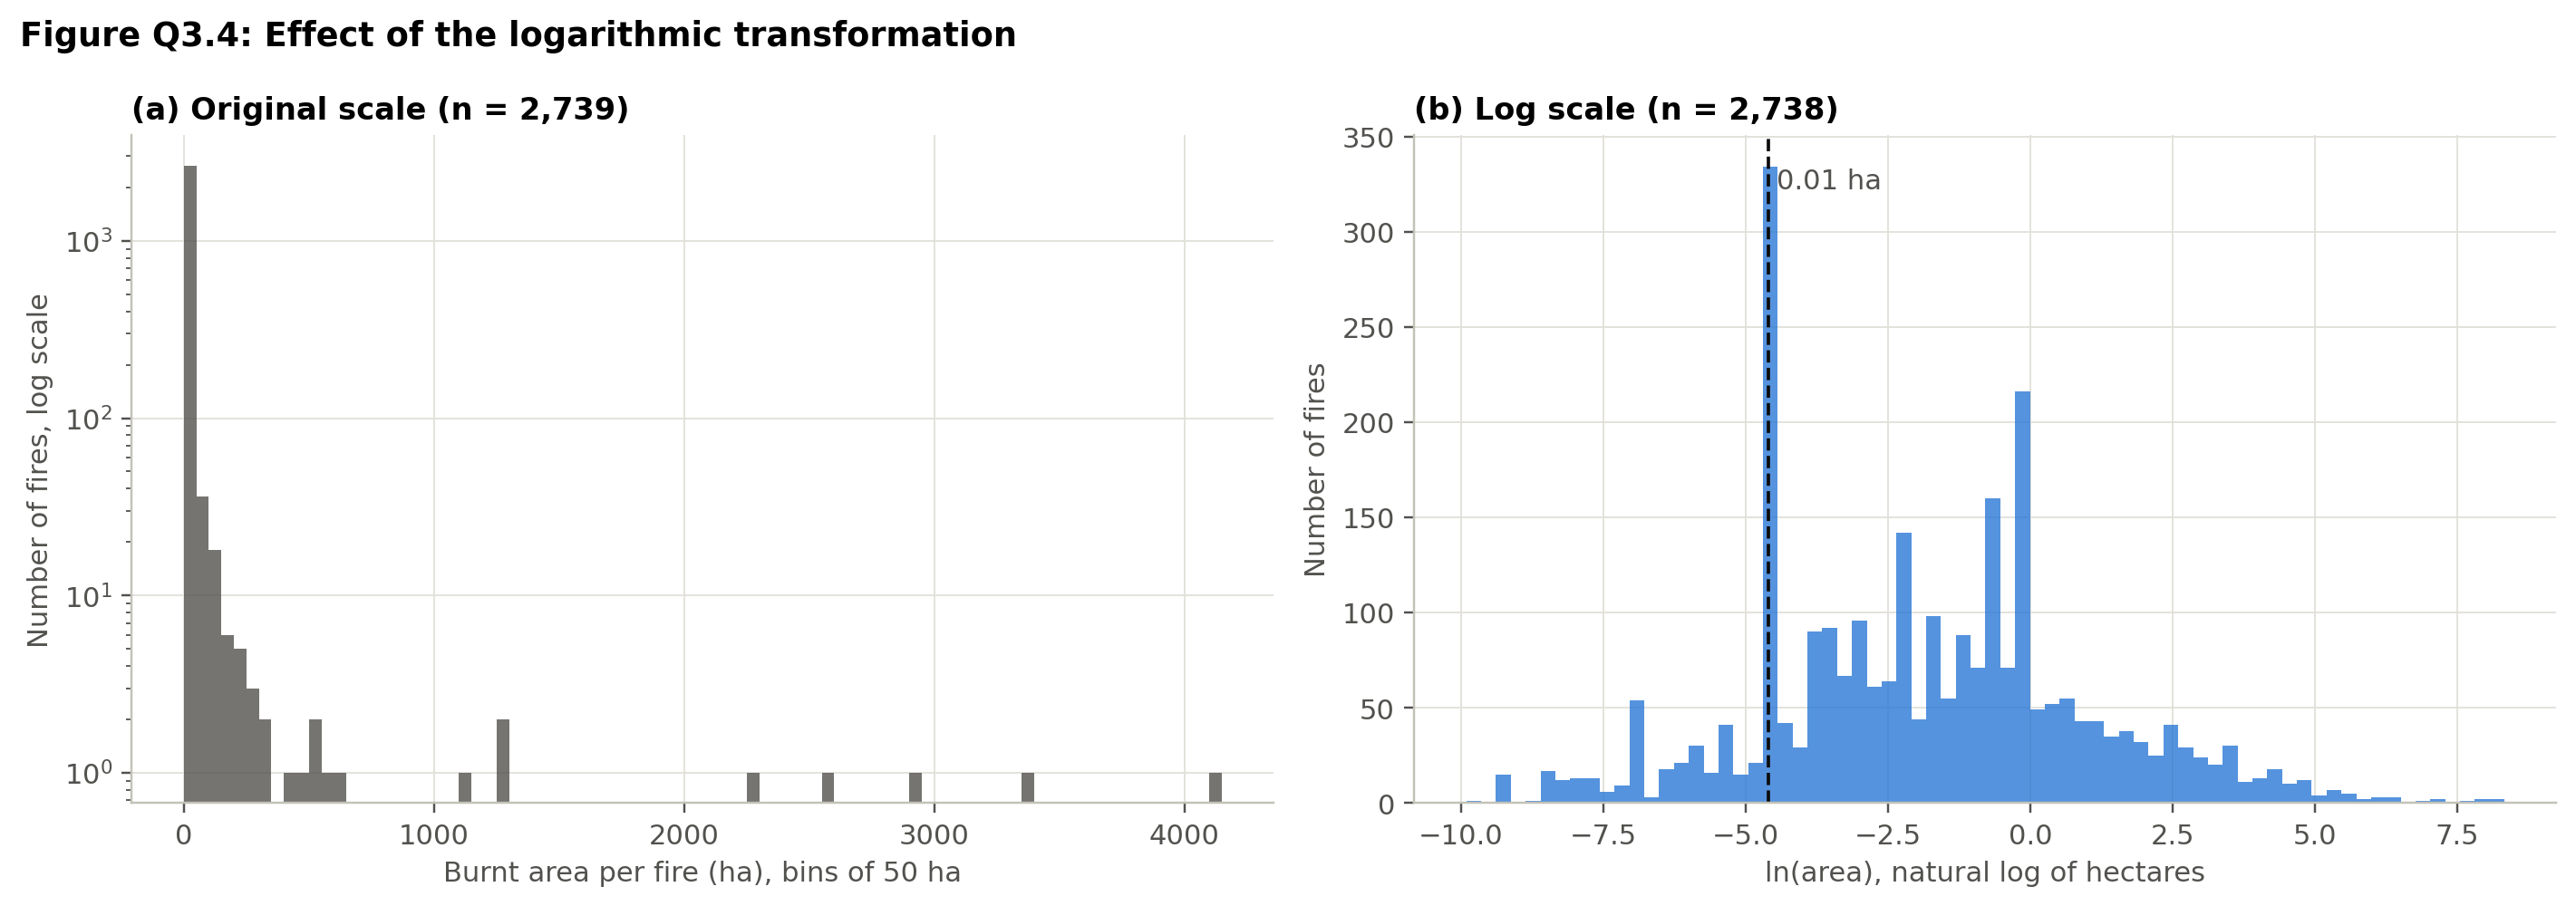

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
axes[0].hist(q3[AREA], bins=np.arange(0, q3[AREA].max() + 50, 50), color=MUTED, alpha=.8)
axes[0].set_yscale("log"); axes[0].set_xlabel("Burnt area per fire (ha), bins of 50 ha"); axes[0].set_ylabel("Number of fires, log scale")
axes[0].set_title(f"(a) Original scale (n = {len(q3):,})")
axes[1].hist(q3_ln["ln_area"], bins=70, color=BLUE, alpha=.8)
axes[1].axvline(np.log(0.01), color=INK, linewidth=1.2, linestyle="--")
axes[1].text(np.log(0.01) + .15, axes[1].get_ylim()[1] * .92, "0.01 ha", color=MUTED)
axes[1].set_xlabel("ln(area), natural log of hectares"); axes[1].set_ylabel("Number of fires")
axes[1].set_title(f"(b) Log scale (n = {len(q3_ln):,})")
fig_title(fig, "Figure Q3.4: Effect of the logarithmic transformation")
plt.tight_layout(); plt.show()

##### Residual diagnostics on the log scale

We now inspect the residuals of ln(area) both pooled and **by municipality**, together with group sizes and spreads.

              n  sd of ln(area)  skewness  excess kurtosis  Shapiro W  Shapiro p
Chaves      555           2.712    0.3838           0.2596      0.962  8.617e-11
Montalegre 1146           2.813  -0.08395          -0.4723     0.9709  2.048e-14
Ourém       619           2.712    0.4091            1.438     0.9712  1.129e-09
Tomar       418           2.452   -0.0138           0.9545     0.9765  2.697e-06
Largest/smallest SD: 1.15 | largest/smallest variance: 1.32 | largest/smallest n: 2.74


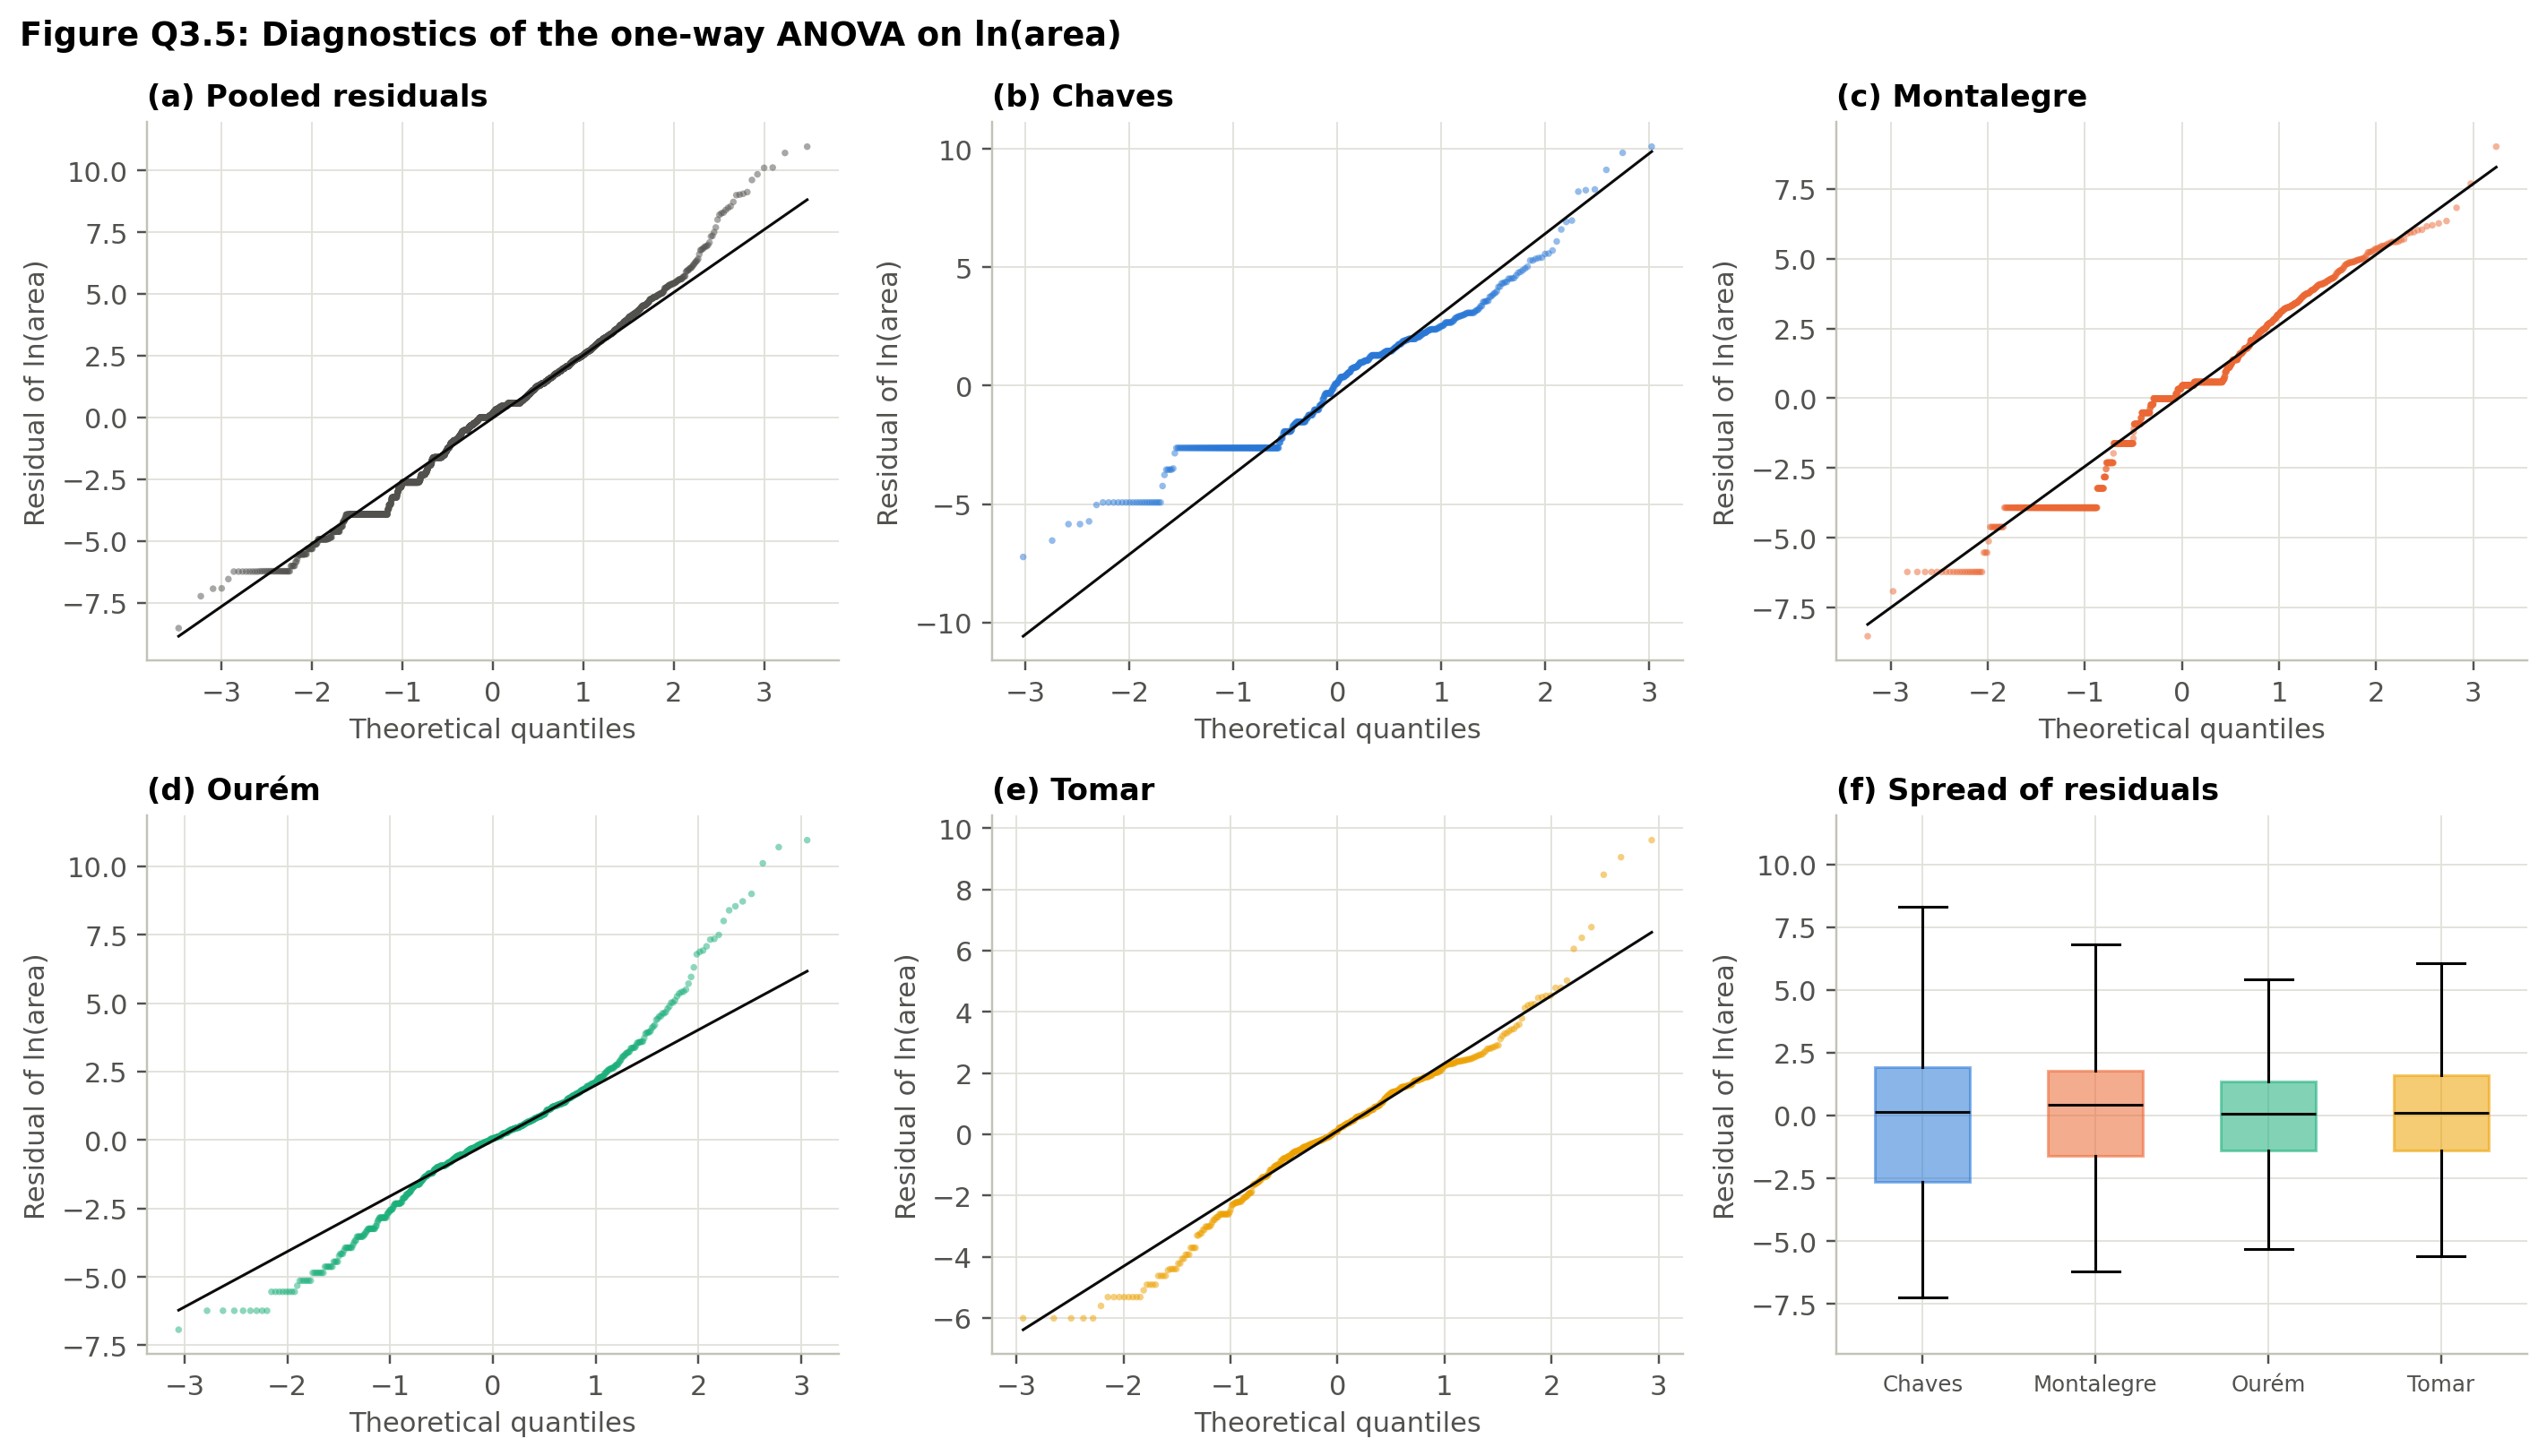

In [42]:
rows = {}
for m in MUNICIPALITIES:
    x = q3_ln_groups[m]; sw = stats.shapiro(x)
    rows[m] = {"n": len(x), "sd of ln(area)": x.std(ddof=1), "skewness": stats.skew(x), "excess kurtosis": stats.kurtosis(x),
               "Shapiro W": sw.statistic, "Shapiro p": sw.pvalue}
ln_tab = pd.DataFrame(rows).T
print(ln_tab.to_string(float_format=lambda v: f"{v:.4g}"))
sds = ln_tab["sd of ln(area)"]
print(f"Largest/smallest SD: {sds.max() / sds.min():.2f} | largest/smallest variance: {(sds.max() / sds.min()) ** 2:.2f} | largest/smallest n: {ln_tab['n'].max() / ln_tab['n'].min():.2f}")

resid_ln = {m: q3_ln_groups[m] - q3_ln_groups[m].mean() for m in MUNICIPALITIES}
fig, axes = plt.subplots(2, 3, figsize=(13, 7.5))
qq_panel(axes[0, 0], np.concatenate(list(resid_ln.values())), MUTED, "(a) Pooled residuals", ylabel="Residual of ln(area)")
for ax, m, tag in zip([axes[0, 1], axes[0, 2], axes[1, 0], axes[1, 1]], MUNICIPALITIES, "bcde"):
    qq_panel(ax, resid_ln[m], PAL_MUN[m], f"({tag}) {m}", ylabel="Residual of ln(area)")
bp = axes[1, 2].boxplot([resid_ln[m] for m in MUNICIPALITIES], patch_artist=True, widths=.55, medianprops=dict(color=INK),
                        flierprops=dict(marker="o", markersize=2, alpha=.4, markeredgewidth=0))
for patch, m in zip(bp["boxes"], MUNICIPALITIES):
    patch.set(facecolor=PAL_MUN[m], alpha=.55, edgecolor=PAL_MUN[m])
axes[1, 2].set_xticks(range(1, 5)); axes[1, 2].set_xticklabels(MUNICIPALITIES, fontsize=8)
axes[1, 2].set_title("(f) Spread of residuals"); axes[1, 2].set_ylabel("Residual of ln(area)")
fig_title(fig, "Figure Q3.5: Diagnostics of the one-way ANOVA on ln(area)")
plt.tight_layout(); plt.show()

##### Assessment and choice of method

| Response scale | Residual skewness | Excess kurtosis | Variance ratio | Assessment |
|---|---:|---:|---:|---|
| Original (ha) | 21.0 | 493 | 29.2 | Assumptions clearly not met |
| log(1 + area) | 2.8 | 10.0 | 4.4 | Improves, but still strongly skewed |
| **ln(area)** | **0.13** | **0.27** | **1.32** | Approximately symmetric, similar spreads |

- **Normality on the log scale.** In the centre, the Q-Q plots of the pooled residuals and of each municipality follow the reference line closely (group skewness between −0.08 and 0.41). The lower tail shows stair-steps caused by repeated recorded areas (probably rounding), and Ourém has a somewhat heavier upper tail (excess kurtosis 1.4). Shapiro-Wilk still rejects (W ≈ 0.96–0.98), as expected with 400–1,100 observations per group; the departures are moderate and much smaller than on the original scale (skewness 21, kurtosis 493).
- **Equal variances on the log scale.** The variance ratio is 1.32 (SD ratio 1.15). Levene and Brown-Forsythe remain significant (p ≈ 0.0001–0.0002), but with 2,738 observations such a small difference is detectable; it is not practically important. Because the groups with larger sizes (Montalegre, n = 1,146) also have the largest SD, the classical F-test tends to be, if anything, slightly conservative. Welch's ANOVA on the same response is nevertheless run as a sensitivity check in the robustness checks.
- **Remaining limits.** The concentration of recorded areas at 0.01 ha (possibly rounding or reporting conventions) creates a visible spike in Figure Q3.4b, and independence cannot be verified (see *Independence* above).
- **`log(1 + area)`** is not used because it does not remove the skewness.

**Decision.** The **primary analysis is the classical one-way ANOVA on ln(burnt area)**, with **Tukey HSD** for the pairwise comparisons. It answers the research question as formulated (differences in mean ln(area), i.e. in geometric means) and its assumptions are reasonably met. This choice was fixed from the diagnostics, before looking at any ANOVA p-value. Robustness is checked below with Welch's ANOVA and Games-Howell on the same response, a rank-based Kruskal-Wallis test, and three alternative samples. The ANOVA does not make inferences about arithmetic means in hectares.

#### One-way ANOVA

**Idea.** Compare how far the municipality means are from each other (**between-group variation, SSB**) with how much the fires vary inside each municipality (**within-group variation, SSW**). Dividing each sum of squares by its degrees of freedom gives mean squares, and **F = MSB / MSW**. If H₀ were true, F would be close to 1; a large F means that the group means are further apart than the within-group noise explains. The **p-value** is the probability of an F at least this large if H₀ were true (and the assumptions held). A significant result says that *at least one* mean differs, not which one.

**Why not several t-tests?** With 4 groups there are 6 pairs; each test at α = 0.05 carries a 5 % false-positive risk, which accumulates to about 26 % across 6 tests. The ANOVA tests everything at once, and Tukey HSD controls the error rate across the pairs.

H₀: μ_Chaves = μ_Montalegre = μ_Ourém = μ_Tomar (means of ln area) · H₁: at least one differs · α = 0.05

In [43]:
# ANOVA table computed by hand (every number is traceable), then cross-checked with scipy
N_ln = len(q3_ln); n_groups = len(q3_ln_groups)
grand = q3_ln["ln_area"].mean()
ssb = sum(len(v) * (v.mean() - grand) ** 2 for v in q3_ln_groups.values())
ssw = sum(((v - v.mean()) ** 2).sum() for v in q3_ln_groups.values()); sst = ssb + ssw
df_b, df_w = n_groups - 1, N_ln - n_groups
msb, msw = ssb / df_b, ssw / df_w
F = msb / msw; p_anova = stats.f.sf(F, df_b, df_w)

F_scipy, p_scipy = stats.f_oneway(*q3_ln_groups.values())
assert np.isclose(F, F_scipy) and np.isclose(p_anova, p_scipy), "manual ANOVA differs from scipy"

anova_q3 = pd.DataFrame({"SS": [ssb, ssw, sst], "df": [df_b, df_w, N_ln - 1], "MS": [msb, msw, np.nan], "F": [F, np.nan, np.nan],
                         "p-value": [p_anova, np.nan, np.nan]}, index=["Between municipalities", "Within (residual)", "Total"])
print(anova_q3.to_string(float_format=lambda v: f"{v:.5g}"))
eta2 = ssb / sst; omega2 = (ssb - df_b * msw) / (sst + msw)
print(f"F({df_b}, {df_w}) = {F:.2f}, p = {p_anova:.3g}")
print(f"Effect size on the ln scale: eta^2 = {eta2:.3f}, omega^2 = {omega2:.3f} (benchmarks: 0.01 small, 0.06 medium, 0.14 large)")

                           SS    df     MS      F    p-value
Between municipalities 3110.6     3 1036.9 140.43 1.2661e-84
Within (residual)       20187  2734 7.3836    NaN        NaN
Total                   23297  2737    NaN    NaN        NaN
F(3, 2734) = 140.43, p = 1.27e-84
Effect size on the ln scale: eta^2 = 0.134, omega^2 = 0.133 (benchmarks: 0.01 small, 0.06 medium, 0.14 large)


In [44]:
# Group estimates on the log scale and back-transformed to hectares (geometric means), with 95 % t-intervals
rows = []
for m in MUNICIPALITIES:
    v = q3_ln_groups[m]; n = len(v); mean = v.mean(); se = v.std(ddof=1) / np.sqrt(n); t = stats.t.ppf(.975, n - 1)
    rows.append({"municipality": m, "n": n, "mean ln(area)": mean, "sd ln(area)": v.std(ddof=1), "geometric mean (ha)": np.exp(mean),
                 "95% CI low (ha)": np.exp(mean - t * se), "95% CI high (ha)": np.exp(mean + t * se)})
gm = pd.DataFrame(rows).set_index("municipality")
print(gm.round(3).to_string())

# Cross-check with statsmodels
fit_q3 = smf.ols("ln_area ~ C(Concelho)", data=q3_ln.assign(Concelho=q3_ln["Concelho"].astype(str))).fit()
tab_q3 = sm.stats.anova_lm(fit_q3, typ=1)
print("statsmodels F =", round(float(tab_q3["F"].iloc[0]), 2), "| matches manual F:", bool(np.isclose(tab_q3["F"].iloc[0], F)))

                 n  mean ln(area)  sd ln(area)  geometric mean (ha)  95% CI low (ha)  95% CI high (ha)
municipality                                                                                          
Chaves         555         -1.977        2.712                0.139            0.110             0.174
Montalegre    1146         -0.683        2.813                0.505            0.429             0.594
Ourém          619         -2.973        2.712                0.051            0.041             0.063
Tomar          418         -3.200        2.452                0.041            0.032             0.052
statsmodels F = 140.43 | matches manual F: True


- **Decision.** F(3, 2734) = 140.4, p < 0.001. At α = 0.05 we **reject H₀**: there is strong evidence that the mean of ln(burnt area) is not the same in the four municipalities, i.e. that the geometric mean (typical) burnt area per fire differs between at least two of them.
- **Effect size.** η² = 0.134 (ω² = 0.133): about 13 % of the variation **of ln(burnt area)** in this model is associated with the municipality, a medium-to-large effect by conventional benchmarks. This is *not* the share of the variation of the area in hectares, and it is not a causal statement. Most of the variation (87 %) is between fires of the same municipality.
- **Geometric means** (exp of the mean of ln area, not arithmetic means and not medians): Montalegre ≈ 0.50 ha, Chaves ≈ 0.14 ha, Ourém ≈ 0.05 ha, Tomar ≈ 0.04 ha. They are close to, but not equal to, the sample medians.
- The ANOVA does not say which municipalities differ; that is the role of the post-hoc analysis below. The p-value assumes independent fires, which cannot be verified, so it should be read as strong but approximate evidence.

#### Post-hoc analysis

The ANOVA only says *whether* some mean differs. To see *which* municipalities differ we compare all 6 pairs with **Tukey HSD**, which adjusts the p-values so that the probability of **any** false positive stays at 5 % (the *family-wise error rate*). With unequal group sizes it is the Tukey-Kramer version (what `scipy.stats.tukey_hsd` computes). It is appropriate here because the primary ANOVA is the classical one on ln(area), with nearly equal variances.

The differences are in ln(area). Exponentiated, each difference is a **ratio of geometric means**: a ratio of 3 means that the typical fire in the first municipality is 3 times that of the second; a ratio of 1 means no difference. Pairs are ordered so that the municipality with the larger geometric mean comes first.

In [45]:
tk = stats.tukey_hsd(*[q3_ln_groups[m] for m in MUNICIPALITIES])
ci_tk = tk.confidence_interval(confidence_level=0.95)
order = sorted(range(4), key=lambda i: -q3_ln_groups[MUNICIPALITIES[i]].mean())     # larger geometric mean first
means_ln = {m: q3_ln_groups[m].mean() for m in MUNICIPALITIES}

rows = []
for x in range(4):
    for y in range(x + 1, 4):
        i, j = order[x], order[y]                                              # i has the larger mean
        a, b = MUNICIPALITIES[i], MUNICIPALITIES[j]; d_ln = means_ln[a] - means_ln[b]
        assert np.isclose(d_ln, tk.statistic[i, j]) and np.isclose(ci_tk.low[j, i], -ci_tk.high[i, j])
        rows.append({"comparison (first / second)": f"{a} / {b}", "difference in ln(area)": d_ln, "ratio of geometric means": np.exp(d_ln),
                     "95% CI ratio low": np.exp(ci_tk.low[i, j]), "95% CI ratio high": np.exp(ci_tk.high[i, j]),
                     "Tukey adj. p": tk.pvalue[i, j], "significant (0.05)": bool(tk.pvalue[i, j] < 0.05)})
posthoc = pd.DataFrame(rows).set_index("comparison (first / second)")
shown = posthoc.copy(); shown["Tukey adj. p"] = posthoc["Tukey adj. p"].map(lambda v: "< 0.0001" if v < 1e-4 else f"{v:.4f}")
print(shown.to_string(float_format=lambda v: f"{v:.4g}"))
primary_sig = {frozenset(c.split(" / ")) for c, r in posthoc.iterrows() if r["significant (0.05)"]}
print("Significant pairs:", len(primary_sig), "of 6")

                             difference in ln(area)  ratio of geometric means  95% CI ratio low  95% CI ratio high Tukey adj. p  significant (0.05)
comparison (first / second)                                                                                                                        
Montalegre / Chaves                           1.293                     3.645              2.54              5.232     < 0.0001                True
Montalegre / Ourém                            2.289                     9.868             6.965              13.98     < 0.0001                True
Montalegre / Tomar                            2.517                     12.39              8.31              18.46     < 0.0001                True
Chaves / Ourém                               0.9958                     2.707             1.799              4.072     < 0.0001                True
Chaves / Tomar                                1.223                     3.398             2.161              5.3

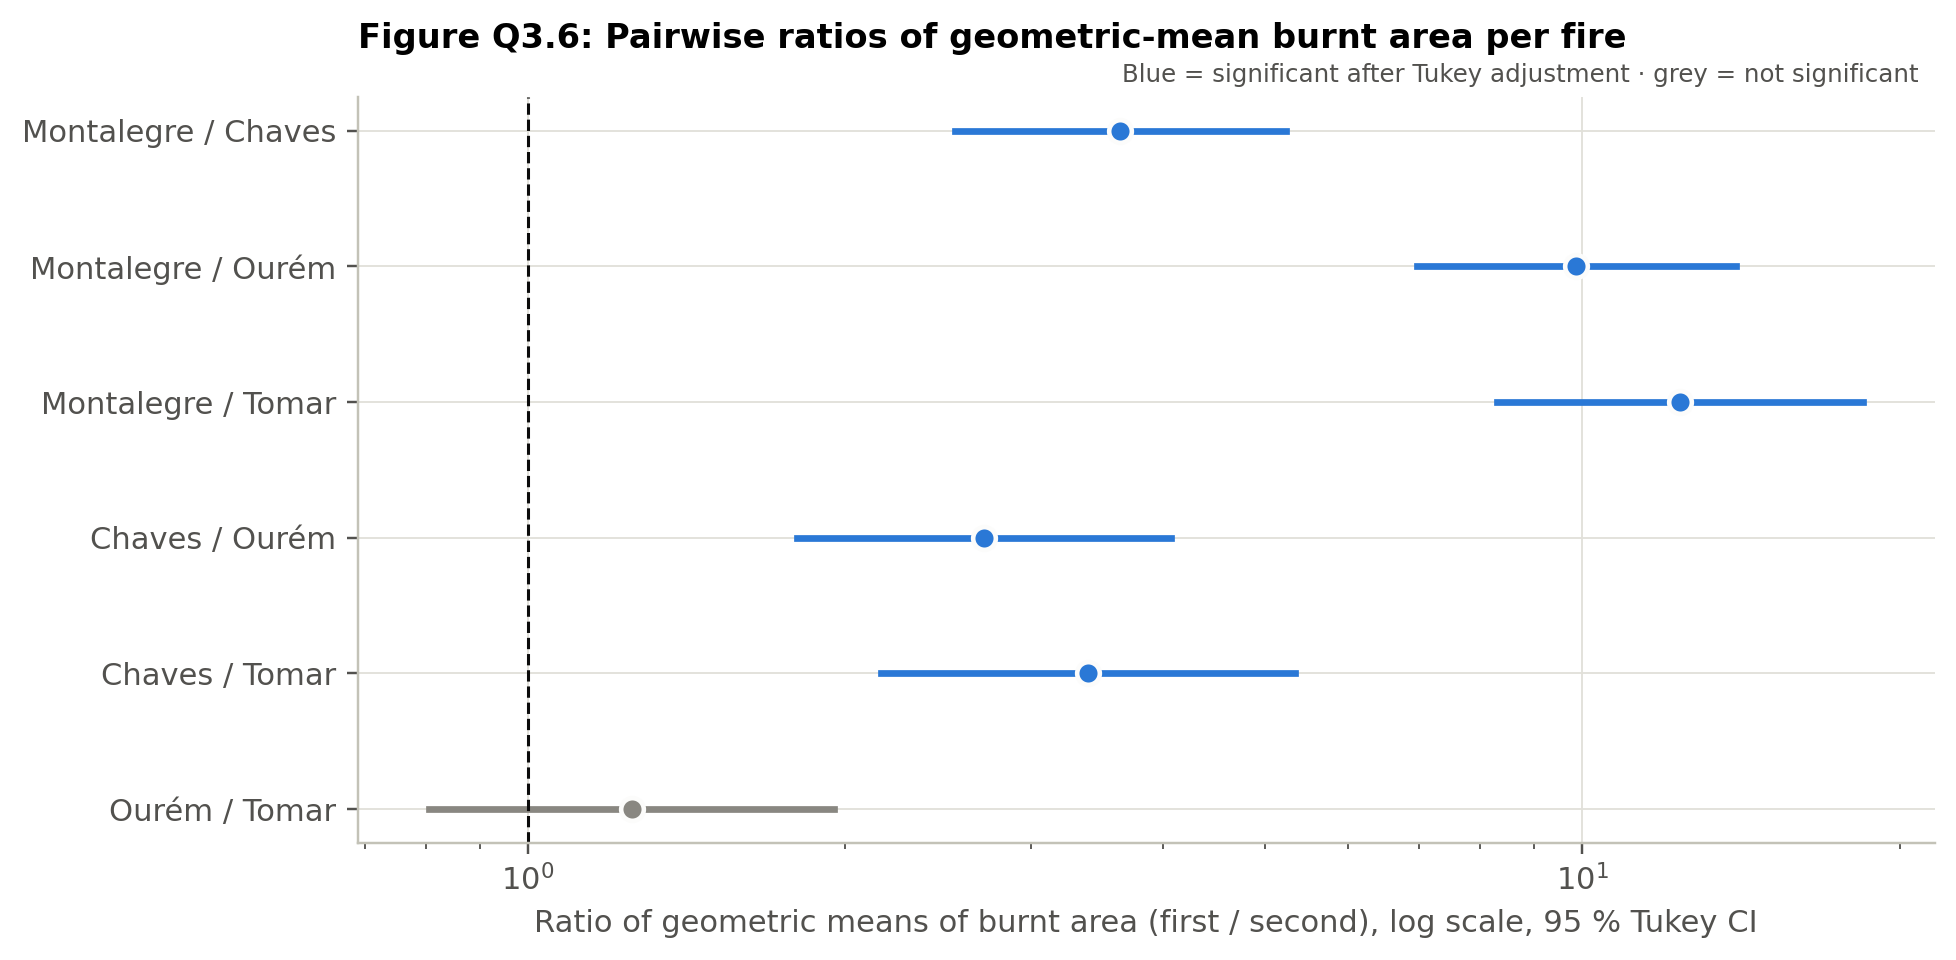

In [46]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ypos = np.arange(len(posthoc))[::-1]
for y_, (name, r) in zip(ypos, posthoc.iterrows()):
    col = BLUE if r["significant (0.05)"] else "#898781"
    ax.plot([r["95% CI ratio low"], r["95% CI ratio high"]], [y_, y_], color=col, linewidth=2.2)
    ax.scatter(r["ratio of geometric means"], y_, s=55, color=col, zorder=3, edgecolor=SURFACE, linewidth=1.5)
ax.axvline(1, color=INK, linestyle="--", linewidth=1)
ax.set_xscale("log"); ax.set_yticks(ypos); ax.set_yticklabels(posthoc.index)
ax.set_xlabel("Ratio of geometric means of burnt area (first / second), log scale, 95 % Tukey CI")
ax.set_title("Figure Q3.6: Pairwise ratios of geometric-mean burnt area per fire", pad=16)
ax.text(0.99, 1.02, "Blue = significant after Tukey adjustment · grey = not significant", transform=ax.transAxes, ha="right", fontsize=8, color=MUTED)
plt.tight_layout(); plt.show()

At a family-wise level of 5 %:

- **Montalegre** has a larger geometric-mean burnt area than each of the other three municipalities: about 3.6 times Chaves, 9.9 times Ourém and 12.4 times Tomar (adjusted p < 0.0001).
- **Chaves** is larger than Ourém (≈ 2.7 times) and Tomar (≈ 3.4 times) (adjusted p < 0.0001).
- **Ourém and Tomar do not differ significantly** (ratio 1.26, 95 % CI 0.81–1.95, adjusted p = 0.55). Failing to detect a difference is not evidence that they are equal; the interval is compatible with ratios from about 0.8 to 2.
- All 6 pairs were compared, and the confidence intervals are on the ratio scale (log differences exponentiated), not in hectares.
- **Statistical vs. practical importance.** The geometric means are all below 1 ha, so a ratio of 10 (e.g., 0.50 ha vs 0.05 ha) is statistically strong but small in absolute hectares; the total burnt area is determined by rare extreme fires, which the logarithm deliberately down-weights.

#### Robustness checks

To see whether the conclusion depends on the choices made along the way, we repeated the analysis changing one of them at a time. We only kept the checks that are relevant to Q3, and all of them use the same response variable, ln(area):

1. **Welch's ANOVA and Games-Howell comparisons.** These do not require equal variances, so they show whether the result depends on that assumption.
2. **Kruskal-Wallis test.** It is based on ranks and is therefore unaffected by monotone transformations such as the logarithm, so it shows whether the result depends on normality. It compares distributions, not means.
3. **Excluding 2025,** which is an incomplete year.
4. **Human-related fires only** (intentional and negligent), which connects Q3 to the theme of the project.
5. **Excluding the 28 largest fires** (1 % of the sample), as an exploratory check on whether a few extreme fires drive the result.

Permutation tests were not used. Permuting the municipality labels tests the stronger hypothesis that the whole distributions are identical, which is hard to justify when the groups have different variances and shapes. Welch's ANOVA is implemented below and was validated against the Welch t-test, since for two groups F equals t².

In [47]:
def welch_anova(samples):
    # Welch (1951) one-way ANOVA for unequal variances; returns F, df1, df2, p
    n = np.array([len(x) for x in samples]); m = np.array([x.mean() for x in samples]); v = np.array([x.var(ddof=1) for x in samples])
    kk = len(samples); w = n / v; W = w.sum(); mw = (w * m).sum() / W
    A = (w * (m - mw) ** 2).sum() / (kk - 1); lam = ((1 - w / W) ** 2 / (n - 1)).sum()
    B = 1 + 2 * (kk - 2) / (kk ** 2 - 1) * lam
    Fw = A / B; df2 = (kk ** 2 - 1) / (3 * lam)
    return Fw, kk - 1, df2, stats.f.sf(Fw, kk - 1, df2)

def games_howell(samples):
    # Games-Howell adjusted p-values for all pairs (unequal variances); returns a symmetric matrix
    kk = len(samples); P = np.ones((kk, kk))
    for i in range(kk):
        for j in range(i + 1, kk):
            a, b = samples[i], samples[j]; va, vb = a.var(ddof=1) / len(a), b.var(ddof=1) / len(b)
            df_ = (va + vb) ** 2 / (va ** 2 / (len(a) - 1) + vb ** 2 / (len(b) - 1))
            q_ = abs(a.mean() - b.mean()) / np.sqrt((va + vb) / 2)
            P[i, j] = P[j, i] = stats.studentized_range.sf(q_, kk, df_)
    return P

# Validation: with two groups, Welch's F equals the square of the Welch t statistic
t_chk = stats.ttest_ind(q3_ln_groups["Chaves"], q3_ln_groups["Montalegre"], equal_var=False)
F_chk, _, df_chk, _ = welch_anova([q3_ln_groups["Chaves"], q3_ln_groups["Montalegre"]])
assert np.isclose(F_chk, t_chk.statistic ** 2) and np.isclose(df_chk, t_chk.df), "Welch implementation check failed"

def ln_samples(df):
    dd = df[df[AREA] > 0]
    return [np.log(dd.loc[dd["Concelho"] == m, AREA].to_numpy()) for m in MUNICIPALITIES]

def sig_set(P):
    return {frozenset((MUNICIPALITIES[i], MUNICIPALITIES[j])) for i in range(4) for j in range(i + 1, 4) if P[i, j] < 0.05}

def pattern(sig):
    return "same pairs as primary" if sig == primary_sig else "DIFFERS: " + str(sorted(tuple(sorted(s)) for s in sig ^ primary_sig))

def classical(samples):
    F_, p_ = stats.f_oneway(*samples); allv = np.concatenate(samples); gm_ = allv.mean()
    return F_, p_, sum(len(x) * (x.mean() - gm_) ** 2 for x in samples) / ((allv - gm_) ** 2).sum()

rows = []
S_all = ln_samples(q3)
F1, p1, e1 = classical(S_all); assert np.isclose(F1, F)
rows.append({"analysis": "Primary: classical ANOVA + Tukey, all fires", "n": sum(map(len, S_all)), "statistic": f"F = {F1:.1f}", "p-value": p1, "eta^2": e1,
             "pairwise pattern": pattern(sig_set(tk.pvalue))})
Fw, d1, d2, pw = welch_anova(S_all)
rows.append({"analysis": "Welch ANOVA + Games-Howell, all fires", "n": sum(map(len, S_all)), "statistic": f"F = {Fw:.1f}", "p-value": pw, "eta^2": np.nan,
             "pairwise pattern": pattern(sig_set(games_howell(S_all)))})
H, pH = stats.kruskal(*[q3_groups[m] for m in MUNICIPALITIES])
rows.append({"analysis": "Kruskal-Wallis (ranks), all fires", "n": len(q3), "statistic": f"H = {H:.1f}", "p-value": pH, "eta^2": np.nan, "pairwise pattern": "not applicable"})
top28 = q3.nlargest(28, AREA).index
for label, df_ in [("Classical ANOVA + Tukey, excluding 2025", sample_no_2025), ("Classical ANOVA + Tukey, human-related fires only", sample_human),
                   ("Classical ANOVA + Tukey, excluding the 28 largest fires", q3.drop(top28))]:
    S = ln_samples(df_); F_, p_, e_ = classical(S)
    rows.append({"analysis": label, "n": sum(map(len, S)), "statistic": f"F = {F_:.1f}", "p-value": p_, "eta^2": e_,
                 "pairwise pattern": pattern(sig_set(stats.tukey_hsd(*S).pvalue))})

robust = pd.DataFrame(rows).set_index("analysis")
robust["p-value"] = robust["p-value"].map(lambda v: "< 0.0001" if v < 1e-4 else f"{v:.4f}")
print(robust.to_string(float_format=lambda v: f"{v:.3f}"))
print()
print(f"Welch on ln(area): F({d1}, {d2:.0f}) = {Fw:.2f}")

                                                            n  statistic   p-value  eta^2       pairwise pattern
analysis                                                                                                        
Primary: classical ANOVA + Tukey, all fires              2738  F = 140.4  < 0.0001  0.134  same pairs as primary
Welch ANOVA + Games-Howell, all fires                    2738  F = 142.8  < 0.0001    NaN  same pairs as primary
Kruskal-Wallis (ranks), all fires                        2739  H = 376.0  < 0.0001    NaN         not applicable
Classical ANOVA + Tukey, excluding 2025                  2418  F = 110.5  < 0.0001  0.121  same pairs as primary
Classical ANOVA + Tukey, human-related fires only        2484  F = 135.0  < 0.0001  0.140  same pairs as primary
Classical ANOVA + Tukey, excluding the 28 largest fires  2710  F = 154.7  < 0.0001  0.146  same pairs as primary

Welch on ln(area): F(3, 1238) = 142.82


- **Equal variances.** Welch's ANOVA on ln(area) leads to the same conclusion as the classical ANOVA (F(3, 1238) = 142.8, p < 0.0001), and the Games-Howell comparisons identify the same pairs as Tukey HSD. The main result therefore does not depend on the assumption of equal variances.
- **Normality.** The Kruskal-Wallis test, which is based on ranks and is not affected by the logarithmic transformation, also rejects the equality of the distributions (H = 376.0, p < 0.0001). It does not compare means, but it indicates that the conclusion does not rest on the normality assumption.
- **Incomplete 2025, human-related fires only and the 28 largest fires.** In all three cases the ANOVA remains highly significant (F between 110 and 155, p < 0.0001), the same five pairs differ, and Ourém and Tomar still cannot be distinguished. The value of η² stays between 0.12 and 0.15. The result is thus not driven by 2025, by non-human causes or by a few extreme fires; on the log scale, the largest fires have limited leverage.
- These checks concern the sensitivity of the **log-scale** conclusion only. None of them is an inference about arithmetic mean burnt areas in hectares which, as shown in Section 3.3, are dominated by a small number of very large fires.

In [48]:
# Numbers quoted in the conclusions (Section 5.3), taken from the objects computed above (traceability check)
print(f"n = {len(q3)} fires; ANOVA sample n = {len(q3_ln)}")
print(f"ANOVA on ln(area): F({df_b}, {df_w}) = {F:.1f}, p = {p_anova:.2g}, eta^2 = {eta2:.3f}")
print("Geometric means (ha):", gm["geometric mean (ha)"].round(2).to_dict())
print(posthoc[["ratio of geometric means", "95% CI ratio low", "95% CI ratio high"]].round(2).to_string())
print("Ourem/Tomar adjusted p =", round(float(posthoc.loc["Ourém / Tomar", "Tukey adj. p"]), 2))
print(f"Welch on ln(area): F({d1}, {d2:.0f}) = {Fw:.1f}; Kruskal-Wallis H = {H:.1f}")

n = 2739 fires; ANOVA sample n = 2738
ANOVA on ln(area): F(3, 2734) = 140.4, p = 1.3e-84, eta^2 = 0.134
Geometric means (ha): {'Chaves': 0.14, 'Montalegre': 0.5, 'Ourém': 0.05, 'Tomar': 0.04}
                             ratio of geometric means  95% CI ratio low  95% CI ratio high
comparison (first / second)                                                               
Montalegre / Chaves                              3.65              2.54               5.23
Montalegre / Ourém                               9.87              6.96              13.98
Montalegre / Tomar                              12.39              8.31              18.46
Chaves / Ourém                                   2.71              1.80               4.07
Chaves / Tomar                                   3.40              2.16               5.34
Ourém / Tomar                                    1.26              0.81               1.95
Ourem/Tomar adjusted p = 0.55
Welch on ln(area): F(3, 1238) = 142.8; Kruskal-Wal

---

### 4.4 Q4: Two-way ANOVA

A two-way ANOVA was chosen because the response variable (`Log_Total_Burnt_Area`) is quantitative and there are two qualitative factors with two levels each, `Cause_Type` (Intentional, Negligent) and `Period` (Pre-2017, Post-2017). This design gives four groups and allows us to test the effect of the cause, the effect of the period and the interaction between them. The research question is answered by the interaction term.

#### Hypotheses

(significance level α = 0.05)

| Effect | H₀ | H₁ |
|---|---|---|
| Cause_Type | The mean log burnt area is the same for intentional and negligent fires | The means differ |
| Period | The mean log burnt area is the same before and after 2017 | The means differ |
| Interaction | The difference between causes is the same in both periods | The difference between causes changes from one period to the other |

#### Checking the assumptions

ANOVA requires three conditions. The observations must be independent, the data within each group must be approximately normal, and the variability must be similar across groups.

Independence is reasonable because each row corresponds to a different fire. The other two conditions are checked below for each of the four Cause_Type x Period groups, using histograms and normal probability plots (Q-Q plots) for normality and comparing the standard deviations of the groups for constant variance.

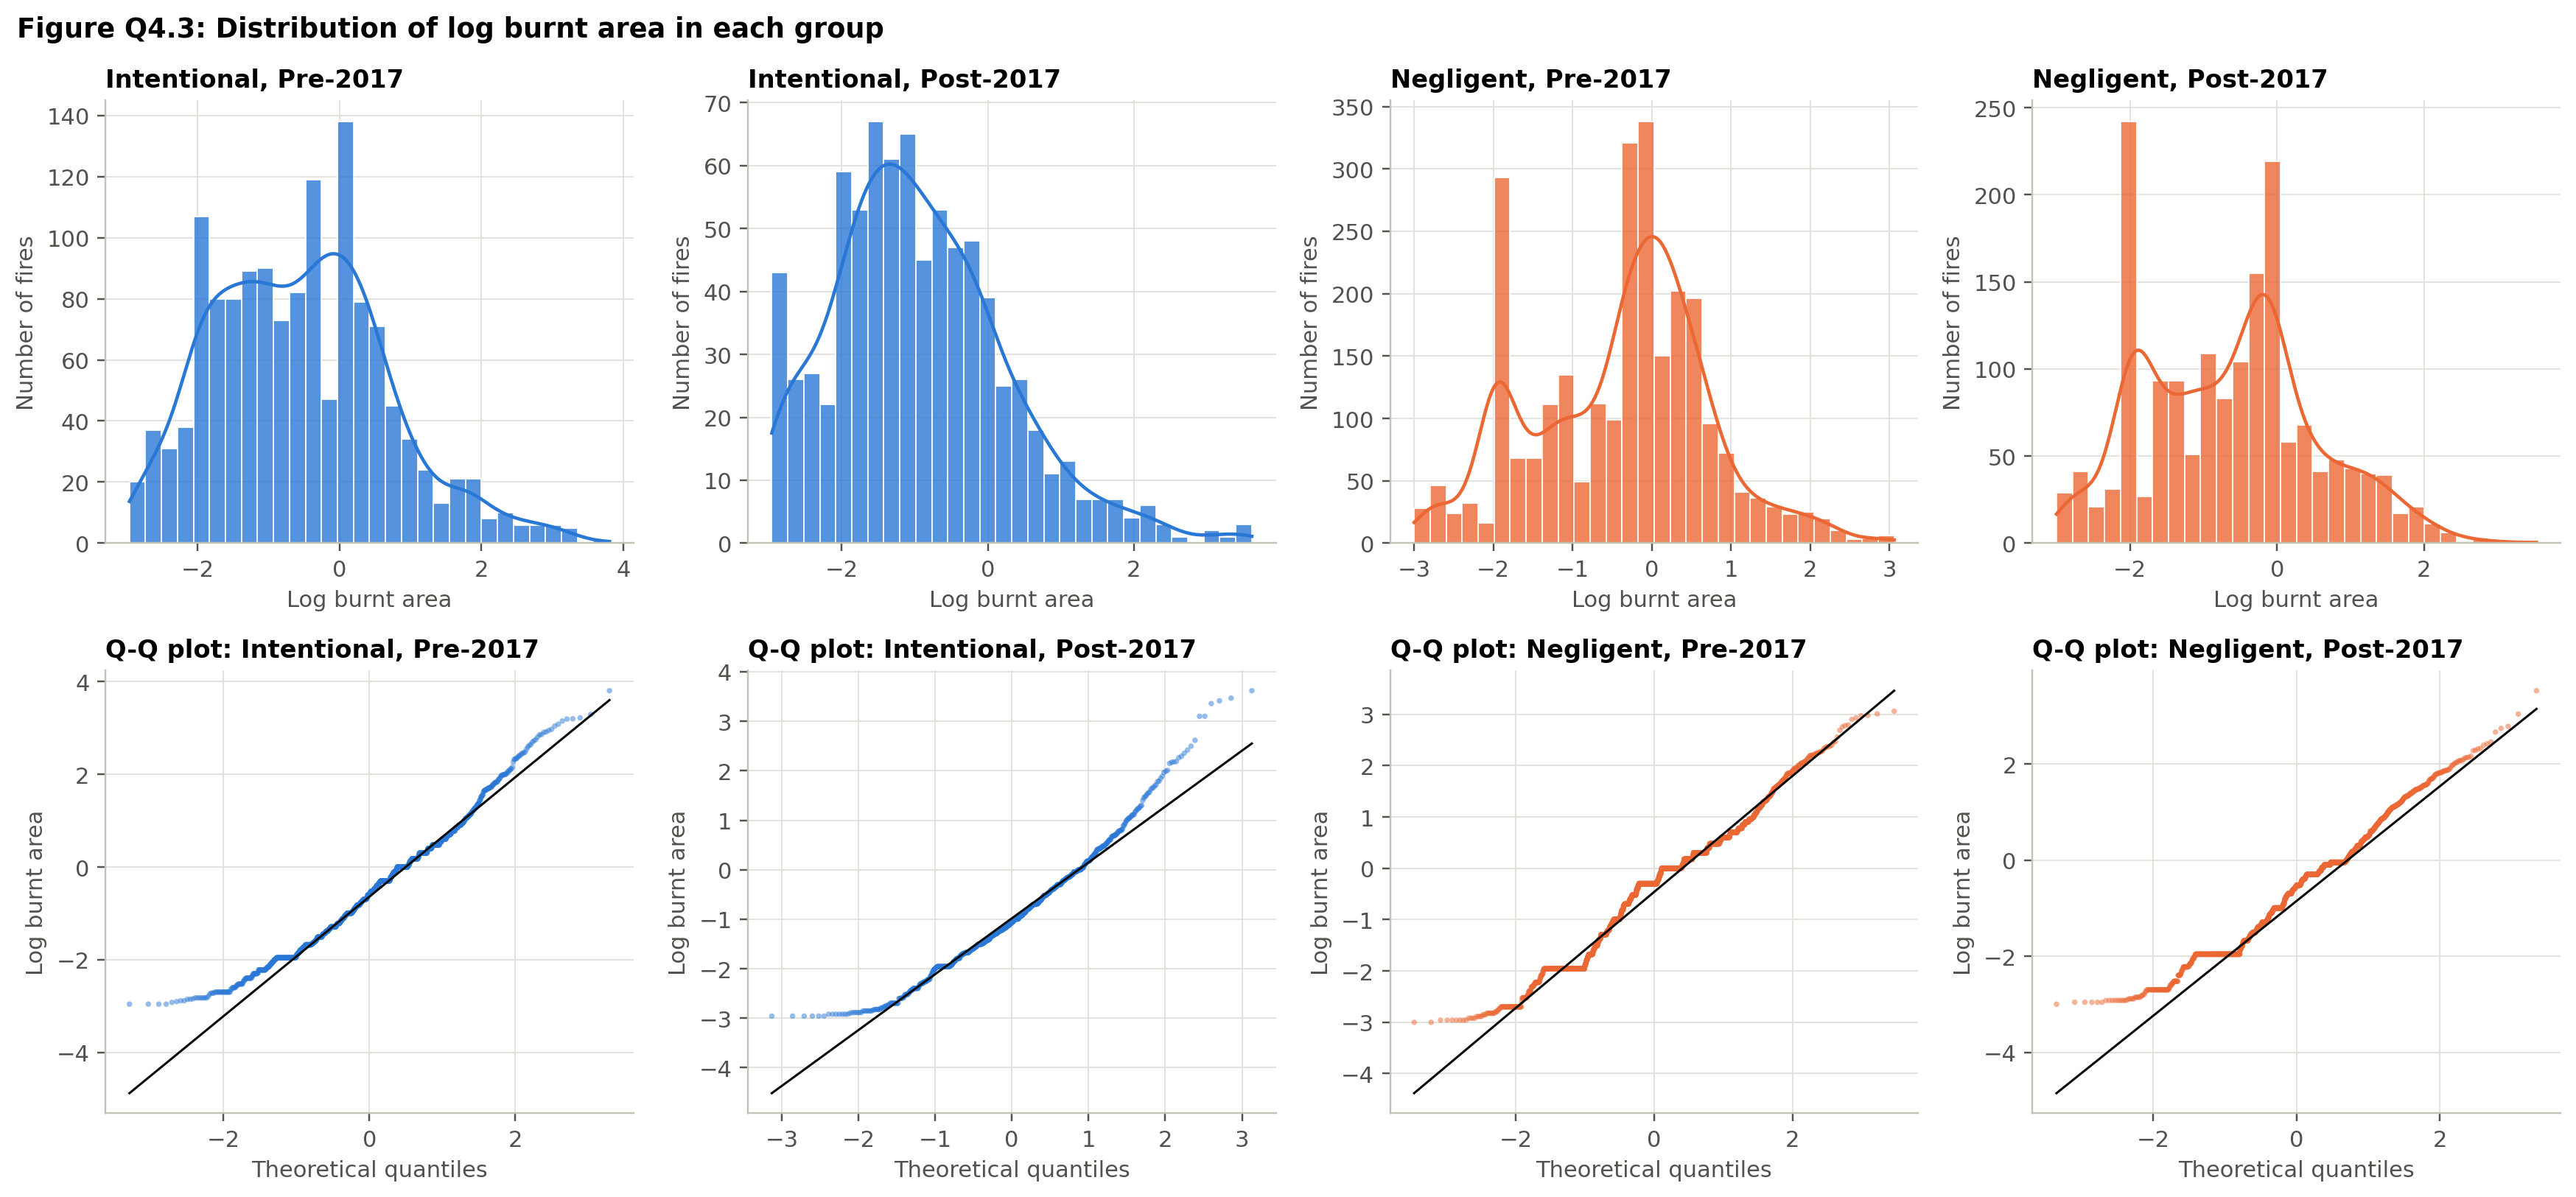

    Cause_Type     Period  Log_Total_Burnt_Area
0  Intentional   Pre-2017                 1.228
1  Intentional  Post-2017                 1.195
2    Negligent   Pre-2017                 1.109
3    Negligent  Post-2017                 1.170

Largest SD / smallest SD: 1.11
Levene test: W = 11.00, p = 3.33e-07


In [49]:
# Normality within each group
fig, axes = plt.subplots(2, 4, figsize=(16, 7.5))
for i, ((cause, period), g) in enumerate(q4.groupby(["Cause_Type", "Period"], observed=True)):
    x = g["Log_Total_Burnt_Area"]
    sns.histplot(x, bins=30, kde=True, color=PAL_CAUSE[cause], alpha=0.8, edgecolor=SURFACE, ax=axes[0, i])
    axes[0, i].set_title(f"{cause}, {period}")
    axes[0, i].set_xlabel("Log burnt area")
    axes[0, i].set_ylabel("Number of fires")
    qq_panel(axes[1, i], x, PAL_CAUSE[cause], f"Q-Q plot: {cause}, {period}", ylabel="Log burnt area")
fig_title(fig, "Figure Q4.3: Distribution of log burnt area in each group")
plt.tight_layout()
plt.show()

# Constant variance: standard deviation of each group
sd_q4 = q4.groupby(["Cause_Type", "Period"], observed=True)["Log_Total_Burnt_Area"].std()
print(sd_q4.round(3).reset_index())
print(f"\nLargest SD / smallest SD: {sd_q4.max() / sd_q4.min():.2f}")

# Complementary test for equal variances (Levene, median-centred)
groups_q4 = [g["Log_Total_Burnt_Area"].values
             for _, g in q4.groupby(["Cause_Type", "Period"], observed=True)]
lev = stats.levene(*groups_q4, center="median")
print(f"Levene test: W = {lev.statistic:.2f}, p = {lev.pvalue:.2e}")

**Normality.** On the log scale, the distributions are much closer to symmetric than the original data, but they are not normal. The intentional groups have a longer right tail, which corresponds to a small number of very large fires. The negligent groups show two peaks (at about -2 and 0) caused by the many fires recorded with exactly 0.01 ha and 1 ha. These peaks reflect the rounding of the recorded areas and also explain the horizontal steps in the Q-Q plots. There are no extreme outliers. Since ANOVA compares means and every group has at least 789 observations, the sampling distribution of each mean is approximately normal by the Central Limit Theorem, so this departure is not a concern. Robustness checks that do not rely on this assumption are presented together with the ANOVA results.

**Constant variance.** The standard deviations range from 1.11 to 1.23, and the largest is only 1.11 times the smallest, so the variability is very similar across groups. The Levene test rejects equal variances (p < 0.001), but with more than 6,500 observations it detects differences too small to matter in practice. The condition of constant variance is considered satisfied.

#### Two-way ANOVA

The model includes the two main effects (Cause_Type and Period) and their interaction. Because the groups have different sizes, Type III sums of squares are used, so that each effect is tested after accounting for the others. Sum-to-zero coding is used so that each main effect is tested as an average across the levels of the other factor.

The effect size of each term is measured with partial eta squared (partial η²), which is the proportion of variability explained by the effect after removing the variability explained by the other effects. The usual reference values are 0.01 (small), 0.06 (medium) and 0.14 (large).

In [50]:
model_q4 = smf.ols(
    "Log_Total_Burnt_Area ~ C(Cause_Type, Sum) * C(Period, Sum)", data=q4
).fit()

anova_q4 = sm.stats.anova_lm(model_q4, typ=3)
ss_res = anova_q4.loc["Residual", "sum_sq"]
anova_q4["partial_eta_sq"] = anova_q4["sum_sq"] / (anova_q4["sum_sq"] + ss_res)
anova_q4.loc[["Intercept", "Residual"], "partial_eta_sq"] = np.nan
anova_q4.index = ["Intercept", "Cause_Type", "Period", "Cause_Type x Period", "Residual"]
anova_q4.round(4)

,sum_sq,df,F,PR(>F),partial_eta_sq
Intercept,2140.5659,1.0,1587.4279,0.0000,NaN
Cause_Type,71.0569,1.0,52.6953,0.0000,0.0080
Period,130.1719,1.0,96.5346,0.0000,0.0146
Cause_Type x Period,6.7470,1.0,5.0036,0.0253,0.0008
Residual,8785.1466,6515.0,NaN,NaN,NaN


To check that the conclusions do not depend on the assumptions that were not fully met, the analysis is repeated in two ways. The first is an ANOVA with heteroscedasticity-consistent standard errors (HC3), which does not assume equal variances. The second is a non-parametric Kruskal-Wallis test applied to the four groups, which does not assume normality.

In [51]:
# Robustness check 1: ANOVA with heteroscedasticity-consistent errors (HC3)
anova_q4_hc3 = sm.stats.anova_lm(model_q4, typ=3, robust="hc3")
anova_q4_hc3.index = ["Intercept", "Cause_Type", "Period", "Cause_Type x Period", "Residual"]
print(anova_q4_hc3[["F", "PR(>F)"]].round(4))

# Robustness check 2: Kruskal-Wallis across the four Cause_Type x Period groups
kw = stats.kruskal(*groups_q4)
print(f"\nKruskal-Wallis: H = {kw.statistic:.2f}, p = {kw.pvalue:.2e}")

                             F  PR(>F)
Intercept            1516.7840  0.0000
Cause_Type             50.3503  0.0000
Period                 92.2386  0.0000
Cause_Type x Period     4.7809  0.0288
Residual                   NaN     NaN

Kruskal-Wallis: H = 181.03, p = 5.29e-39


All three effects are significant at α = 0.05.

- **Cause_Type** (F(1, 6515) = 52.70, p < 0.001). Negligent fires have a larger typical burnt area.
- **Period** (F(1, 6515) = 96.53, p < 0.001). The mean log burnt area is lower after 2017.
- **Interaction** (F(1, 6515) = 5.00, p = 0.025). The difference between causes changes between periods.

The HC3 version gives the same conclusions (interaction p = 0.029), and the Kruskal-Wallis test confirms that the four groups differ (p < 0.001), although it cannot test the interaction separately.

The effect sizes are small. Only Period reaches a small effect (partial η² = 0.015), Cause_Type is below this threshold (0.008) and the interaction is negligible (0.0008). The interaction is statistically significant because the large sample can detect very small differences, but its practical relevance is very limited. In other words, the difference between causes did change between periods, but by an amount that is small compared with the natural variation in burnt area from fire to fire.

#### Post-hoc analysis

Since the interaction is significant, the main effects alone do not fully describe the results. The analysis is therefore completed in two steps. First, the two causes are compared within each period (simple effects), which shows how the difference between causes behaves before and after 2017. Second, all four groups are compared pairwise, which shows how each cause changed between periods.

In [52]:
# Simple effects: Negligent vs Intentional within each period (Welch t-test)
rows = []
for p in PERIOD_ORDER:
    sub = q4[q4["Period"] == p]
    neg = sub.loc[sub["Cause_Type"] == "Negligent", "Log_Total_Burnt_Area"]
    inten = sub.loc[sub["Cause_Type"] == "Intentional", "Log_Total_Burnt_Area"]
    t = stats.ttest_ind(neg, inten, equal_var=False)
    diff = neg.mean() - inten.mean()
    rows.append({"Period": p, "diff_log (Neg - Int)": diff,
                 "ratio_geom_means": 10 ** diff, "t": t.statistic, "p_value": t.pvalue})
pd.DataFrame(rows).round(4)

,Period,diff_log (Neg - Int),ratio_geom_means,t,p_value
0,Pre-2017,0.1586,1.4408,4.0218,0.0001
1,Post-2017,0.2999,1.9947,5.8631,0.0000


In both periods, negligent fires have a significantly larger mean log burnt area (Bonferroni α = 0.025, both p < 0.001). The typical negligent fire was about 1.4 times larger than the intentional one before 2017 and about 2.0 times larger after.

In [53]:
# Pairwise comparisons with Bonferroni correction (OpenIntro, section 7.5)
group_stats = q4.groupby("Cause_Type_Period")["Log_Total_Burnt_Area"].agg(["size", "mean"])
mse = model_q4.mse_resid          # pooled variance from the ANOVA
df_resid = model_q4.df_resid      # 6515
K = 6                             # number of pairwise comparisons
alpha_bonf = 0.05 / K

pairs = []
for g1, g2 in combinations(group_stats.index, 2):
    n_g1, m_g1 = group_stats.loc[g1]
    n_g2, m_g2 = group_stats.loc[g2]
    diff = m_g1 - m_g2
    se = np.sqrt(mse / n_g1 + mse / n_g2)
    t_pair = diff / se
    p_pair = 2 * stats.t.sf(abs(t_pair), df_resid)
    pairs.append({"group1": g1, "group2": g2, "diff": diff, "t": t_pair,
                  "p_value": p_pair, "significant": p_pair < alpha_bonf})

print(f"Bonferroni significance level: 0.05 / {K} = {alpha_bonf:.4f}")
pd.DataFrame(pairs).round(4)

Bonferroni significance level: 0.05 / 6 = 0.0083


,group1,group2,diff,t,p_value,significant
0,Intentional_Post-2017,Intentional_Pre-2017,-0.3809,-7.3503,0.0000,True
1,Intentional_Post-2017,Negligent_Post-2017,-0.2999,-5.9925,0.0000,True
2,Intentional_Post-2017,Negligent_Pre-2017,-0.5395,-11.4571,0.0000,True
3,Intentional_Pre-2017,Negligent_Post-2017,0.0810,1.9252,0.0542,False
4,Intentional_Pre-2017,Negligent_Pre-2017,-0.1586,-4.1160,0.0000,True
5,Negligent_Post-2017,Negligent_Pre-2017,-0.2396,-6.6376,0.0000,True


Six pairwise comparisons were performed using the pooled standard deviation from the ANOVA and a Bonferroni-corrected significance level of 0.05 / 6 ≈ 0.0083. Five of the six pairs differ significantly. The only exception is intentional fires before 2017 vs negligent fires after 2017 (p = 0.054). Both causes decreased after 2017, but intentional fires decreased more, which moved the two causes further apart.

#### Robustness check: controlling for municipality

The four municipalities differ in typical fire size. Fires in Montalegre and Chaves are larger (geometric means of 0.68 ha and 0.36 ha), while fires in Ourém and Tomar are much smaller (0.08 ha and 0.09 ha). The municipalities also do not contribute equally to each group. Ourém accounts for 46% of intentional fires after 2017, compared with 26% before, while Montalegre accounts for more than half of all negligent fires. A change in the mix of municipalities could therefore create an apparent interaction. To check this, Municipality (`Concelho`) was added to the model as a blocking factor.

In [54]:
# Typical burnt area in each municipality
mun_q4 = q4.groupby("Concelho").agg(
    n=("Log_Total_Burnt_Area", "size"),
    mean_log=("Log_Total_Burnt_Area", "mean"),
    median_ha=("Total_Burnt_Area", "median"),
)
mun_q4["geom_mean_ha"] = 10 ** mun_q4["mean_log"]
mun_q4.sort_values("mean_log", ascending=False).round(3)

,n,mean_log,median_ha,geom_mean_ha
Concelho,,,,
Montalegre,2684,-0.168,0.950,0.679
Chaves,1501,-0.445,0.500,0.359
Tomar,1134,-1.055,0.076,0.088
Ourém,1200,-1.090,0.064,0.081


In [55]:
pd.crosstab(q4["Cause_Type_Period"], q4["Concelho"], normalize="index").round(2)

Concelho,Chaves,Montalegre,Ourém,Tomar
Cause_Type_Period,,,,
Intentional_Post-2017,0.18,0.11,0.46,0.25
Intentional_Pre-2017,0.29,0.15,0.26,0.31
Negligent_Post-2017,0.20,0.57,0.11,0.12
Negligent_Pre-2017,0.23,0.54,0.11,0.12


In [56]:
model_q4_mun = smf.ols(
    "Log_Total_Burnt_Area ~ C(Concelho, Sum) + C(Cause_Type, Sum) * C(Period, Sum)",
    data=q4
).fit()
anova_q4_mun = sm.stats.anova_lm(model_q4_mun, typ=3)
anova_q4_mun.index = ["Intercept", "Municipality", "Cause_Type", "Period",
                      "Cause_Type x Period", "Residual"]
anova_q4_mun.round(4)

,sum_sq,df,F,PR(>F)
Intercept,2574.3631,1.0,2153.2091,0.0000
Municipality,999.4406,3.0,278.6456,0.0000
Cause_Type,35.2700,1.0,29.5000,0.0000
Period,90.8401,1.0,75.9791,0.0000
Cause_Type x Period,0.2044,1.0,0.1710,0.6793
Residual,7785.7060,6512.0,NaN,NaN


With municipality in the model, cause type and period remain significant (p < 0.001), but the interaction does not (F = 0.17, p = 0.68). The wider gap after 2017 can therefore be explained by a change in where fires occurred, mainly the larger share of intentional fires in Ourém, and not necessarily by a change in the relationship between cause and fire size.

---

## 5) Formulate Conclusions

This section gathers the answer to each secondary research question, based on the inferences drawn in Section 4.

### 5.1 Q1: Changes in Negligent Causes

**Critical Period:**

Because the p-value is less than 0.05, we reject H₀.

The Z-value of -4.7887 is negative, which tells us the direction of the change: the proportion of negligent fires in the critical period significantly decreased from 55.7% to 47.4% post-2017.

**Non-Critical Period:**

Because the p-value is less than 0.05, we also reject H₀.

The Z-value of 4.1013 is positive, meaning the proportion of negligent fires in the non-critical period significantly increased from 82.6% to 88.2% post-2017.

**Overall Q1 conclusion:**

The change in negligent causes was not uniform, so the reduction was not spread across the whole year. It was concentrated entirely in the critical summer period. The traditional burning months did not benefit from the same improvement. Instead, they saw a significant increase in negligent behaviour, meaning negligent fires remain a persistent challenge in the non-critical months.

### 5.2 Q2: Daily Negligent Ignitions on Weekends and Weekdays

**Statistical decision**

- **Significance level:** $\alpha = 0.05$.
- **Two-sample Welch's t-test (post-2017 Weekend vs. Weekday):**
  - Weekday: $\bar{x} = 1.455$ ($s = 1.161$, $\text{median} = 1.0$, $\text{IQR} = 0.0$, $n_{\text{Weekday}} = 802$)
  - Weekend: $\bar{x} = 1.570$ ($s = 1.402$, $\text{median} = 1.0$, $\text{IQR} = 1.0$, $n_{\text{Weekend}} = 337$)
  - Difference in sample means ($\bar{x}_{\text{Weekend}} - \bar{x}_{\text{Weekday}}$): $+0.115$ ignitions/day ($\text{SE} = 0.0867$).
  - Test statistic and critical value: Welch's $t_{\text{obs}}(538.57) = 1.3223$, two-sided critical value $t_{\text{crit}} = \pm 1.9644$, $p\text{-value} = 0.1866$.
  - 95% confidence interval for $(\mu_{\text{Weekend}} - \mu_{\text{Weekday}})$: $[-0.056, \, 0.285]$.

Because $|t_{\text{obs}}| = 1.3223 < t_{\text{crit}} = 1.9644$ (falling outside the rejection region) and the $p\text{-value} = 0.1866 > \alpha = 0.05$, we **fail to reject the null hypothesis ($H_0$)** at the 5% significance level (the test is inconclusive). Consistently, the 95% confidence interval contains zero. Within the observed sample of active fire days, there is insufficient statistical evidence to claim that the population mean number of daily negligent ignitions differs between weekends and weekdays in the post-2017 period.

**Contextual discussion**

1. **Weekend vs. weekday patterns:** While the sample mean is nominally higher on weekends by $0.115$ ignitions/day, this variation is fully compatible with random sampling variability under $H_0$. The median daily count remains stable at $1.0$ across both subsets, which **suggests** that the typical active fire day involves isolated single occurrences rather than systematic weekend clusters.
2. **Consistency across municipalities (robustness check):** When disaggregating the post-2017 analysis by municipality (`Chaves`, `Montalegre`, `Ourém`, and `Tomar`), all four 95% confidence intervals in Figure Q2.3 cross zero and every municipal $p\text{-value}$ exceeds both the nominal $\alpha = 0.05$ and the Bonferroni-adjusted threshold ($\alpha_{\text{Bonf}} = 0.0125$). This is **consistent with** the conclusion that the absence of a significant weekend effect holds across the individual municipalities rather than being an artifact of pooling.
3. **Temporal consistency (pre vs. post on weekends):** The complementary comparison of weekend ignitions between periods yielded $t(657.32) = -0.5662$ ($p = 0.5715$), failing to reveal a statistically detectable difference in mean daily intensity on active weekends between the pre-2017 and post-2017 timeframes.

### 5.3 Q3: Burnt Area across Municipalities

Descriptively (original scale), the arithmetic mean burnt area per fire was 18.1 ha in Chaves, 13.9 ha in Ourém, 13.7 ha in Montalegre and 3.2 ha in Tomar, whereas the medians were 0.77, 0.16, 0.054 and 0.045 ha in Montalegre, Chaves, Ourém and Tomar, respectively. The arithmetic means are dominated by a few very large fires: the five largest fires of each municipality account for 83 % (Chaves), 84 % (Ourém), 91 % (Tomar) and 40 % (Montalegre) of its burnt area.

The ANOVA rejected the null hypothesis, F(3, 2734) = 140.4, p < 0.001, η² = 0.13: about 13 % of the variation of ln(burnt area) is associated with the municipality. The geometric mean burnt area was 0.50 ha in Montalegre, 0.14 ha in Chaves, 0.05 ha in Ourém and 0.04 ha in Tomar. According to Tukey HSD, the geometric mean in Montalegre was larger than in Chaves (ratio 3.6, 95 % CI 2.5–5.2), Ourém (9.9, 7.0–14.0) and Tomar (12.4, 8.3–18.5), and that of Chaves was larger than in Ourém (2.7, 1.8–4.1) and Tomar (3.4, 2.2–5.3), all with adjusted p < 0.0001. Ourém and Tomar did not differ significantly (ratio 1.26, 95 % CI 0.81–1.95, adjusted p = 0.55). The same conclusions were obtained with Welch's ANOVA (F(3, 1238) = 142.8, p < 0.0001) and Games-Howell comparisons, with the Kruskal-Wallis test (H = 376.0, p < 0.0001), and when excluding 2025, restricting to human-related fires or excluding the 28 largest fires (F between 110 and 155, p < 0.0001, the same five pairs differing in all cases).

We reject the null hypothesis: the mean of the log-transformed burnt area per fire differed significantly across the four municipalities in 2018–2025. It was largest in Montalegre, followed by Chaves, while Ourém and Tomar had the smallest values and could not be distinguished from each other. This result is stable across the robustness checks. It concerns the typical fire and should not be read as a comparison of arithmetic mean burnt areas in hectares: on that scale the descriptive ranking is different (Chaves has the highest mean) because a handful of very large fires dominate the means, and no inference about arithmetic means was made. Differences in the typical fire are also small in absolute terms (geometric means below 1 ha), whereas the total burnt area is determined by rare extreme fires.

### 5.4 Q4: Burnt Area by Cause Type and Period

The disparity in final burnt area between intentional and negligent fires did not narrow after 2017. The typical negligent fire was larger than the typical intentional fire in both periods, and the gap went from a ratio of about 1.4 to about 2.0. The two-way ANOVA found a significant interaction (p = 0.025), but with a negligible effect size, and this interaction is no longer significant when municipality is included in the model.

The most consistent result is the effect of the period, since fires of both causes became smaller after 2017. This effect holds in every version of the analysis. The cause type also has a stable effect, with negligent fires burning more area in a typical case, although intentional fires include the largest events, as shown by their much higher arithmetic mean.

For the four municipalities studied, there is no consistent evidence that the change between periods differed between the two causes. The reduction in fire size after 2017 was shared by both. Since this is an observational study, and the post-2017 period mixes years before and after the 2021 law, this reduction cannot be attributed to specific policy measures.

---

## 6) Look Back and Ahead

### 6.1 Limitations

#### Dataset

Four limitations affect interpretation and should be kept in mind when reading the results:

1. The Period split is set at 2017, but the law was only implemented in 2021. The post-2017 group therefore mixes years before and after the law took effect, so any change attributed to the post-2017 period cannot be separated from the effect of the law itself without a further split.

2. Initial_Response_Time and Fire_Duration depend on how consistently timestamps are recorded across municipalities. The alert source (FonteAlerta) also varies, and response time depends partly on who reported the fire. These differences may introduce variation between municipalities that is not caused by fire behaviour, which is relevant to the municipality comparisons in Q3 and Q4.

3. Burnt area appears to be estimated rather than measured for small fires, since rounded values such as 0.01, 0.5, 1 and 2 ha are much more frequent than intermediate values. This adds measurement error to the response variable of Q3 and Q4 and explains why the log burnt area is not normally distributed.

4. The four municipalities contribute unequally to each group, and their share changed between periods. In Q4, this change in composition was enough to produce a significant interaction that disappeared once municipality was added to the model, so results based on the pooled data should be read with this in mind.

#### Q2: Daily negligent ignitions

1. **Truncated/conditional sampling on active ignition days ($Y \ge 1$).** The SGIF database only records days on which at least one fire occurred in a given municipality. Municipal days with zero ignitions ($0$ fires) are unobserved in this aggregated table. As a result, the test evaluates the *operational density of ignitions given that an event occurred*, rather than the unconditional daily risk or overall community fire incidence rate.
2. **Spatial and temporal dependency (assumption of independence).** The two-sample t-test assumes mutually independent observations. In wildfire dynamics, ignitions occurring in neighbouring municipalities (e.g., Chaves and Montalegre) or on consecutive calendar days are often subject to common synoptic meteorological systems (such as heat waves or dry winds), introducing potential unmodelled spatial and temporal autocorrelation.
3. **Distributional shape and discrete nature.** Daily counts are non-negative integers bounded at 1 with strong right skewness (skewness $\approx 4$, excess kurtosis $\approx 20$). Although the Central Limit Theorem provides asymptotic approximation for the distribution of the sample mean given the substantial sample sizes ($n_1 = 337, n_2 = 802$), strong skewness slows convergence, and count-based generalized linear models would account more naturally for discrete structures.
4. **Retention of zero-area records ($0\text{ ha}$).** In this analysis, occurrences with a recorded burnt area of $0\text{ ha}$ (such as immediate interventions extinguished before spreading) were **explicitly retained** when computing `Daily_Ignitions_Count`, assuming that any validated negligent record in SGIF represents an actual ignition occurrence regardless of final area burned. However, maintaining or excluding these minor records shifts daily event counts, underscoring the sensitivity of empirical metrics to institutional reporting thresholds.

#### Q3: Burnt area across municipalities

This is an observational study, so the differences cannot be attributed to wildfire policies, the events of 2017 or any other cause; the municipalities differ in vegetation, terrain, weather and land use, and the comparison is unadjusted. The independence of the records cannot be verified: there are indications of possible clustering (55 % of the fires occurred on days with at least two fires in the same municipality, and most of the 130 reignition records followed another fire in the same parish within three days), but these do not prove dependence, so the p-values should be interpreted as approximate. Some deviations from normality and equal variances remain on the log scale, although they are small. One fire with 0 ha was excluded from the ANOVA, a noticeable share of the recorded areas is exactly 0.01 ha (possibly reflecting rounding or reporting conventions), 2025 is incomplete, and the post-2017 period mixes years before and after the 2021 law. Finally, Q3 alone does not answer the main research question of the project on response times and burnt areas before and after 2017.

### 6.2 Alternative Approaches and Future Work

#### Q1: Changes in negligent causes

Looking back at our analysis for Q1, we used two separate Z-tests to evaluate the change in negligent causes for the critical and non-critical periods independently. While this answered our research question and showed that the reduction was concentrated in the summer months, a **Chi-Square Test of Independence** would have been a stronger statistical approach.

If we had used a Chi-Square test on a 2x2x2 contingency table (Cause_Type vs. Period vs. Season), we could have directly tested for an **interaction effect**. This would mathematically prove whether the change in negligent proportions between pre-2017 and post-2017 was significantly *different* between the two seasons, rather than just proving that both changed individually.

Looking ahead, applying a Chi-Square test or a Logistic Regression model with an interaction term (`Period * Season_Risk_Period`) would provide a more robust statistical confirmation that the policy effect was concentrated in the summer.

#### Q2: Daily negligent ignitions

1. **Full calendar reconstruction and hurdle models.** Construct an exhaustive daily panel grid (365 days $\times$ 25 years $\times$ 4 municipalities) and estimate a two-part Hurdle or Zero-Inflated Poisson / Negative Binomial model to simultaneously evaluate the probability of ignition occurrence ($P(Y > 0)$) and conditional count severity ($E[Y \mid Y > 0]$).
2. **Integration of environmental covariates.** Control for daily meteorological hazard indicators (such as the Fire Weather Index, Drought Code, and wind speed) as interacting covariates to assess whether weekend differences emerge specifically under critical atmospheric thresholds.

#### Q4: Burnt area by cause type and period

Looking back at Q4, municipality was only added as a robustness check. Since it explained much more variability than cause type or period, including it in the model from the start, for example with a three-way ANOVA (Cause_Type x Period x Municipality), would have been a more appropriate design. It would also show whether the change between periods differed between municipalities.

Looking ahead, the post-2017 period could be split into 2018-2020 and 2021-2025 to separate the years before and after the law. Since burnt area is skewed and contains many rounded values, a model for the median, such as quantile regression, would also be a useful alternative to the comparison of means.